SIH SMART BUOY – PHYSICS-CALIBRATED MODEL V2
Battery capacity             : 640.0 Wh
Number of WEC arms           : 9
Arm length                   : 0.55 m
Generator rated power/arm    : 75.0 W
Total generator rating       : 675.0 W
Simulation duration           : 720 h


30-DAY PHYSICS-CALIBRATED ENERGY RESULTS


,Parameter,Value
0,Battery Capacity,640.00 Wh
1,Number of WEC Arms,9
2,Generator Rating / Arm,75.0 W
3,Total Generator Rating,675.0 W
4,Initial SOC,100.00%
5,Final SOC,100.00%
6,Minimum SOC,94.30%
7,Average SOC,99.90%
8,Total WEC Energy,236115.46 Wh
9,Total Solar Energy,18931.69 Wh




DAILY ENERGY ANALYSIS


,Wave Height (m),WEC Energy (Wh),Solar Energy (Wh),Load Energy (Wh),Energy Surplus (Wh),Energy Deficit (Wh),SOC (%),Arm RPM,Generator RPM,Net Energy (Wh)
Day Number,,,,,,,,,,
1,1.14,10195.46,645.64,102.3,10738.80,0.00,100.00,7.12,7.12,10738.80
2,1.29,13698.49,645.64,102.3,14241.83,0.00,100.00,7.96,7.96,14241.83
3,1.19,11579.48,645.64,102.3,12122.82,0.00,100.00,7.39,7.39,12122.82
4,0.82,4382.99,645.64,102.3,4926.33,0.00,100.00,5.32,5.32,4926.33
5,0.67,2471.66,645.64,102.3,3015.00,0.00,100.00,4.47,4.47,3015.00
6,0.81,4293.31,645.64,102.3,4836.65,0.00,100.00,5.29,5.29,4836.65
7,1.19,11309.31,645.64,102.3,11852.65,0.00,100.00,7.40,7.40,11852.65
8,1.34,14361.01,645.64,102.3,14904.34,0.00,100.00,8.19,8.19,14904.34
9,1.22,12129.64,645.64,102.3,12672.98,0.00,100.00,7.56,7.56,12672.98


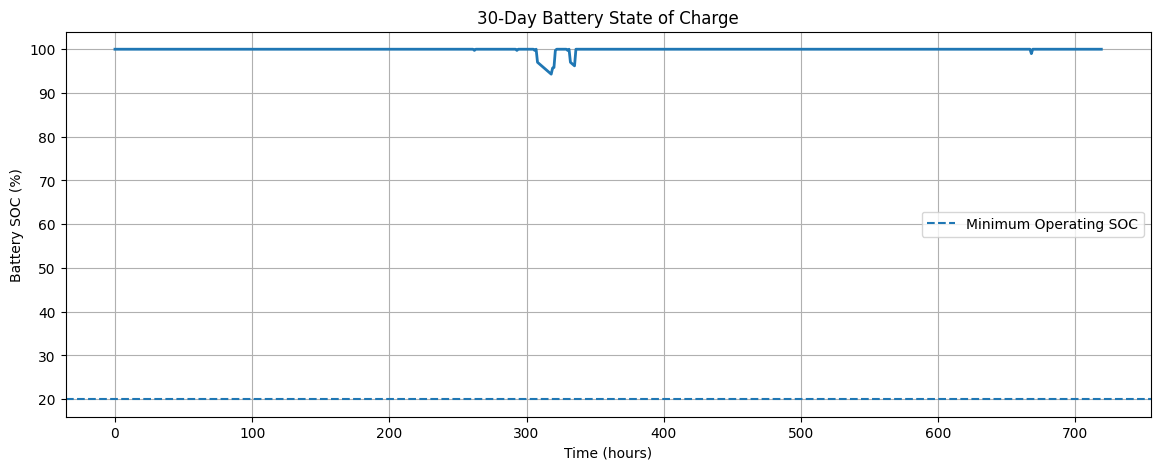

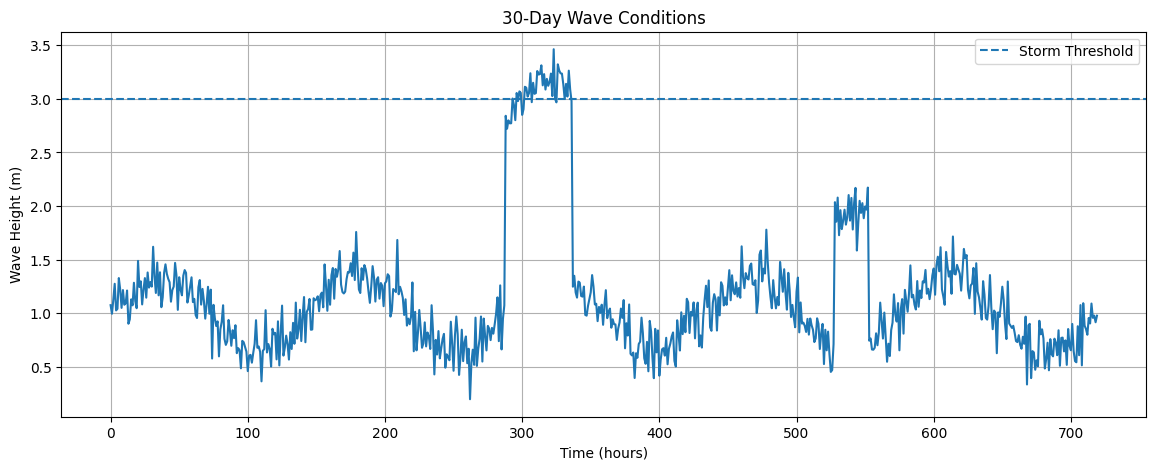

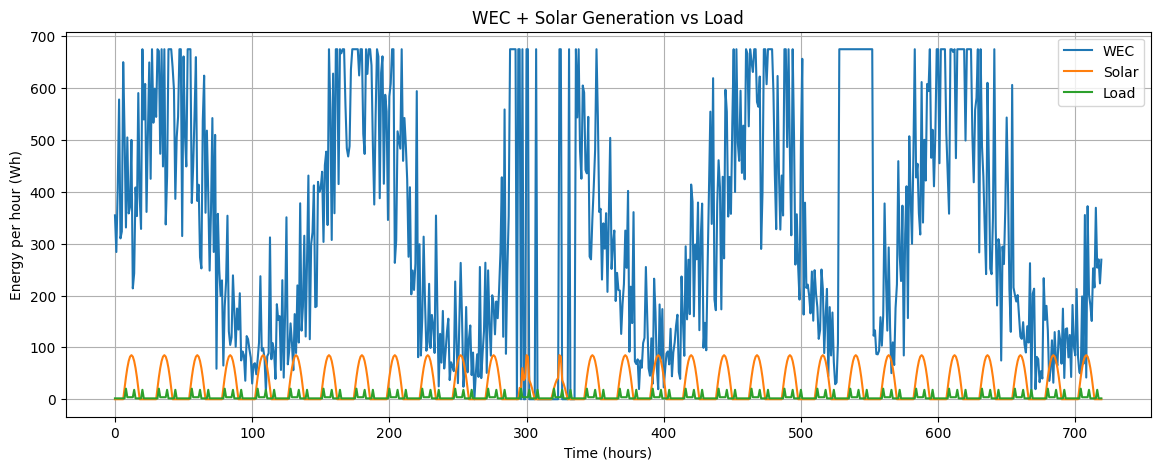

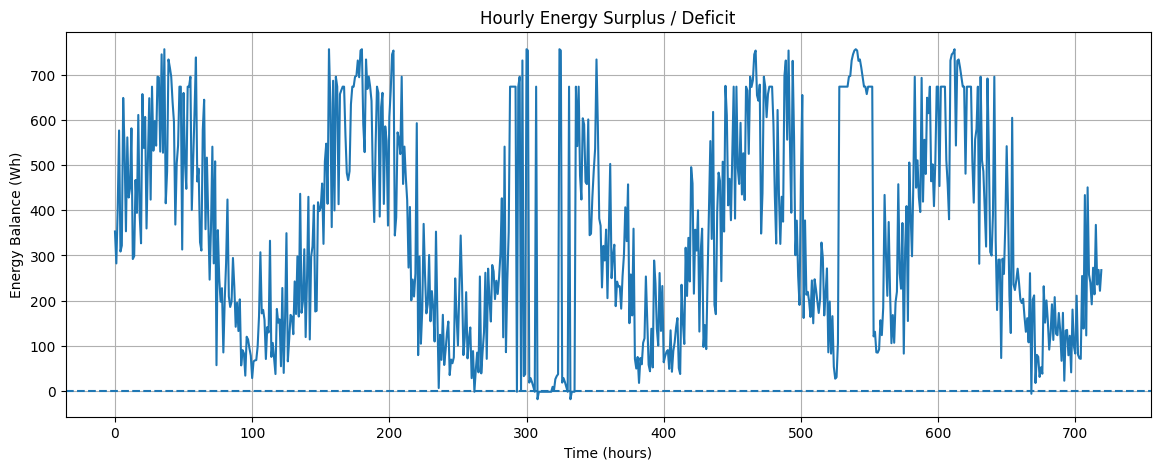

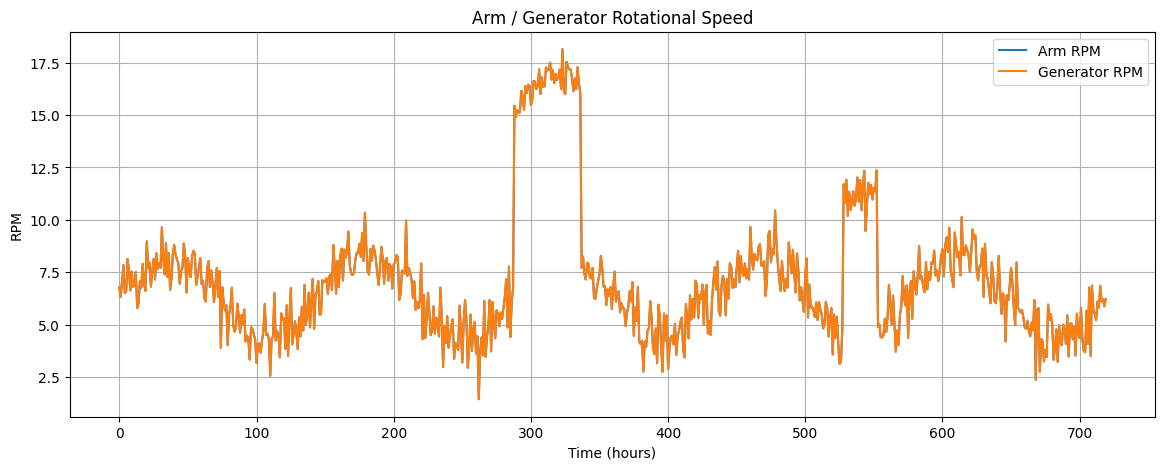

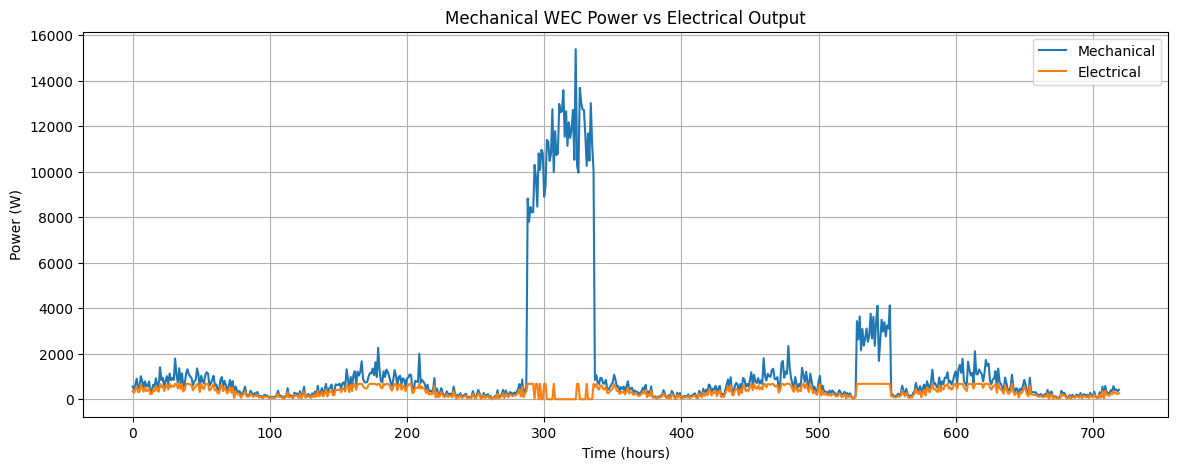

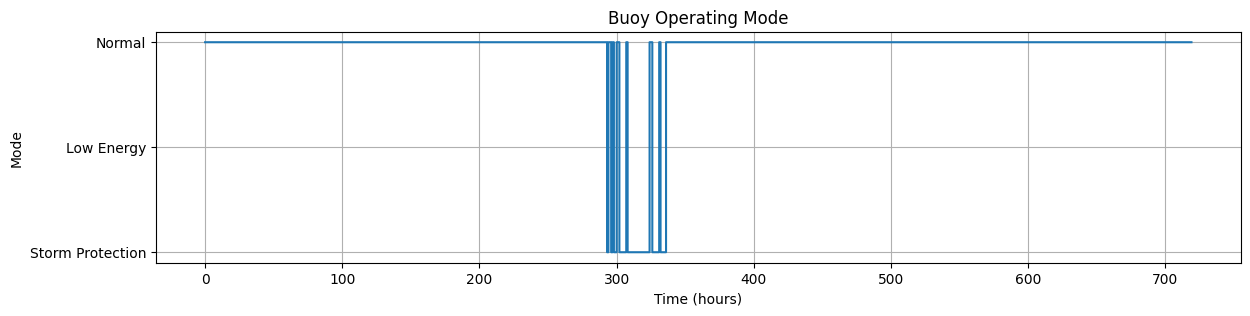



WAVE HEIGHT SCENARIO ANALYSIS


,Hs (m),Average WEC Power (W),Average Mechanical Power (W),Average Arm RPM,Minimum SOC (%),Final SOC (%),Total WEC Energy (kWh),Total Load Energy (kWh)
0,0.5,38.905,60.670,3.433,100.000,100.000,28.011,3.069
1,1.0,288.446,449.819,6.364,100.000,100.000,207.681,3.069
2,2.0,675.000,3260.877,11.533,100.000,100.000,486.000,3.069
3,3.0,0.000,10266.256,16.138,93.758,95.658,0.000,3.069




FINAL ENGINEERING DIAGNOSTIC
Minimum SOC       : 94.30%
Final SOC         : 100.00%
WEC energy        : 236.12 kWh
Solar energy      : 18.93 kWh
Load energy       : 3.07 kWh
Energy deficit    : 0.070 kWh
Storm hours       : 34 h
Low-energy hours  : 0 h
Survival          : 100.00%

Simulation complete.


In [ ]:
# ================================================================
# SIH SMART BUOY – PHYSICS-CALIBRATED 30-DAY ENERGY SIMULATION V2
# ================================================================
#
# ENERGY CHAIN:
#
# Wave height
#     ↓
# Arm displacement
#     ↓
# Arm angular displacement
#     ↓
# Arm angular velocity
#     ↓
# Mechanical torque
#     ↓
# Mechanical power
#     ↓
# Drivetrain efficiency
#     ↓
# Generator efficiency
#     ↓
# Electrical WEC power
#     ↓
# Battery / Load
#
# SYSTEM:
#   9 WEC arms
#   640 Wh battery
#   Solar
#   Electronics
#   Sensors
#   Communications
#   Low-energy mode
#   Storm protection
#
# SIMULATION:
#   30 days
#   1-hour timestep
#
# IMPORTANT:
#   The WEC parameters below are engineering model assumptions.
#   Replace them with prototype measurements when available.
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass


# ================================================================
# 2. SYSTEM PARAMETERS
# ================================================================

@dataclass
class Parameters:

    # ------------------------------------------------------------
    # Simulation
    # ------------------------------------------------------------

    simulation_days: int = 30
    timestep_hours: float = 1.0

    # ------------------------------------------------------------
    # WEC SYSTEM
    # ------------------------------------------------------------

    number_of_arms: int = 9

    # Frozen arm geometry
    arm_length_m: float = 0.55

    # Effective vertical wave motion fraction
    # This is calibrated rather than assuming the full Hs.
    wave_to_arm_motion_ratio: float = 0.35

    # Effective arm angular motion
    # radians per metre of arm-end vertical motion
    angular_motion_factor: float = 1.0 / 0.55

    # Mechanical capture / hydrodynamic efficiency
    hydrodynamic_efficiency: float = 0.15

    # Drivetrain efficiency
    drivetrain_efficiency: float = 0.90

    # Generator efficiency
    generator_efficiency: float = 0.75

    # Electrical controller efficiency
    controller_efficiency: float = 0.95

    # Generator rated electrical power PER ARM
    #
    # This is deliberately much more conservative than the
    # previous 300 W assumption.
    generator_rated_power_per_arm_W: float = 75.0

    # Minimum wave height required for meaningful PTO operation
    cut_in_wave_height_m: float = 0.25

    # Wave height at which generator reaches rated power
    rated_wave_height_m: float = 2.0

    # High-wave/storm protection threshold
    storm_wave_height_m: float = 3.0

    # ------------------------------------------------------------
    # BATTERY
    # ------------------------------------------------------------

    battery_voltage_V: float = 12.8

    battery_capacity_Ah: float = 50.0

    battery_charge_efficiency: float = 0.95

    battery_discharge_efficiency: float = 0.95

    initial_SOC: float = 1.0

    minimum_operating_SOC: float = 0.20

    maximum_SOC: float = 1.00

    # ------------------------------------------------------------
    # SOLAR
    # ------------------------------------------------------------

    solar_panel_power_W: float = 100.0

    solar_efficiency: float = 0.85

    # Approximate equivalent peak-sun-hours/day
    average_sun_hours_per_day: float = 3.5

    # ------------------------------------------------------------
    # ELECTRONICS
    # ------------------------------------------------------------

    base_electronics_W: float = 1.5

    # Sensor power while active
    sensor_power_W: float = 2.0

    sensor_hours_per_day: float = 6.0

    # ------------------------------------------------------------
    # COMMUNICATION
    # ------------------------------------------------------------

    communication_power_W: float = 15.0

    communication_duration_hours: float = 0.10

    communications_per_day: int = 3

    # ------------------------------------------------------------
    # POWER MANAGEMENT
    # ------------------------------------------------------------

    power_management_loss_fraction: float = 0.10

    # ------------------------------------------------------------
    # LOW ENERGY MODE
    # ------------------------------------------------------------

    low_energy_load_reduction: float = 0.50

    # ------------------------------------------------------------
    # STORM PROTECTION
    # ------------------------------------------------------------

    storm_wec_shutdown: bool = True

    storm_solar_factor: float = 0.50


# Create parameter object

p = Parameters()


# ================================================================
# 3. DERIVED VALUES
# ================================================================

battery_capacity_Wh = (
    p.battery_voltage_V *
    p.battery_capacity_Ah
)

simulation_hours = int(
    p.simulation_days *
    24 /
    p.timestep_hours
)

total_rated_generator_power_W = (
    p.number_of_arms *
    p.generator_rated_power_per_arm_W
)

print("=" * 65)
print("SIH SMART BUOY – PHYSICS-CALIBRATED MODEL V2")
print("=" * 65)

print(f"Battery capacity             : {battery_capacity_Wh:.1f} Wh")
print(f"Number of WEC arms           : {p.number_of_arms}")
print(f"Arm length                   : {p.arm_length_m:.2f} m")
print(f"Generator rated power/arm    : {p.generator_rated_power_per_arm_W:.1f} W")
print(f"Total generator rating       : {total_rated_generator_power_W:.1f} W")
print(f"Simulation duration           : {simulation_hours} h")

print("=" * 65)


# ================================================================
# 4. RANDOM SEED
# ================================================================

np.random.seed(42)


# ================================================================
# 5. WAVE MODEL
# ================================================================

def generate_wave_height(hour):
    """
    Synthetic variable Southern Ocean-style wave model.

    This is NOT measured Antarctic data.

    It is intended for testing the energy-management model
    until actual wave/reanalysis data are imported.
    """

    day = hour / 24.0

    # Long-period variability
    slow_variation = (
        0.35 *
        np.sin(2 * np.pi * day / 6.0)
    )

    # Short-term variability
    random_variation = np.random.normal(
        0,
        0.15
    )

    # Baseline
    wave_height = (
        1.0 +
        slow_variation +
        random_variation
    )

    # First storm
    if 12 <= day <= 14:
        wave_height += 1.8

    # Second storm
    if 22 <= day <= 23:
        wave_height += 1.3

    return max(0.1, wave_height)


# ================================================================
# 6. ARM MOTION MODEL
# ================================================================

def calculate_arm_motion(wave_height):
    """
    Estimate arm-end motion from significant wave height.

    Returns:
        displacement amplitude [m]
        angular displacement [rad]
    """

    vertical_motion = (
        wave_height *
        p.wave_to_arm_motion_ratio
    )

    angular_displacement = (
        vertical_motion *
        p.angular_motion_factor
    )

    return (
        vertical_motion,
        angular_displacement
    )


# ================================================================
# 7. WAVE PERIOD MODEL
# ================================================================

def estimate_wave_period(wave_height):
    """
    Simplified relationship between wave height and period.

    This is an engineering approximation.

    Later replace with actual Tp / Te data.
    """

    period = (
        4.5 +
        1.5 *
        np.sqrt(wave_height)
    )

    return period


# ================================================================
# 8. ARM ANGULAR VELOCITY
# ================================================================

def calculate_arm_angular_velocity(
    angular_displacement,
    wave_period
):

    omega = (
        2 *
        np.pi /
        wave_period
    )

    angular_velocity = (
        angular_displacement *
        omega
    )

    return angular_velocity


# ================================================================
# 9. MECHANICAL WEC POWER
# ================================================================

def calculate_mechanical_power(
    wave_height,
    angular_velocity
):

    if wave_height < p.cut_in_wave_height_m:
        return 0.0

    # Approximate available hydrodynamic power.
    #
    # This is not the open-water wave-energy flux formula.
    # It is a reduced effective capture model for our arm system.

    effective_wave_power = (
        0.5 *
        wave_height**2 *
        angular_velocity *
        1000
    )

    mechanical_power = (
        effective_wave_power *
        p.hydrodynamic_efficiency
    )

    return max(
        0.0,
        mechanical_power
    )


# ================================================================
# 10. GENERATOR POWER
# ================================================================

def calculate_generator_power(
    mechanical_power,
    storm=False
):

    if storm and p.storm_wec_shutdown:
        return 0.0

    # Apply drivetrain efficiency
    generator_input = (
        mechanical_power *
        p.drivetrain_efficiency
    )

    # Generator conversion
    electrical_power = (
        generator_input *
        p.generator_efficiency
    )

    # Controller
    electrical_power *= (
        p.controller_efficiency
    )

    # Apply generator rating
    total_max_power = (
        p.number_of_arms *
        p.generator_rated_power_per_arm_W
    )

    electrical_power = min(
        electrical_power,
        total_max_power
    )

    return max(
        0.0,
        electrical_power
    )


# ================================================================
# 11. SOLAR MODEL
# ================================================================

def calculate_solar_power(
    hour,
    storm=False
):

    hour_of_day = hour % 24

    sunrise = 6
    sunset = 18

    if (
        hour_of_day < sunrise or
        hour_of_day >= sunset
    ):
        return 0.0

    daylight_fraction = (
        hour_of_day - sunrise
    ) / (
        sunset - sunrise
    )

    solar_curve = np.sin(
        np.pi *
        daylight_fraction
    )

    solar_power = (
        p.solar_panel_power_W *
        solar_curve *
        p.solar_efficiency
    )

    # Storm/cloud attenuation
    if storm:
        solar_power *= p.storm_solar_factor

    return max(
        0.0,
        solar_power
    )


# ================================================================
# 12. LOAD MODEL
# ================================================================

def calculate_load(
    hour,
    low_energy_mode=False
):

    hour_of_day = hour % 24

    # Base electronics
    load = p.base_electronics_W

    # Sensor operation
    sensor_start = 8
    sensor_end = 14

    if (
        sensor_start <=
        hour_of_day <
        sensor_end
    ):

        load += p.sensor_power_W

    # Communication schedule
    communication_hours = [
        8,
        14,
        20
    ]

    active_comms = (
        communication_hours[
            :p.communications_per_day
        ]
    )

    if any(
        abs(hour_of_day - t) < 0.5
        for t in active_comms
    ):

        load += (
            p.communication_power_W
        )

    # Low energy mode
    if low_energy_mode:

        load *= (
            1 -
            p.low_energy_load_reduction
        )

    # Power-management losses
    load *= (
        1 +
        p.power_management_loss_fraction
    )

    return load


# ================================================================
# 13. BATTERY MODEL
# ================================================================

def update_battery(
    soc,
    generation_Wh,
    load_Wh
):

    battery_energy = (
        soc *
        battery_capacity_Wh
    )

    net_energy = (
        generation_Wh -
        load_Wh
    )

    # Charging
    if net_energy > 0:

        stored_energy = (
            net_energy *
            p.battery_charge_efficiency
        )

        battery_energy += (
            stored_energy
        )

    # Discharging
    else:

        withdrawn_energy = (
            abs(net_energy) /
            p.battery_discharge_efficiency
        )

        battery_energy -= (
            withdrawn_energy
        )

    # Battery limits
    battery_energy = min(
        battery_energy,
        battery_capacity_Wh *
        p.maximum_SOC
    )

    battery_energy = max(
        battery_energy,
        0
    )

    new_soc = (
        battery_energy /
        battery_capacity_Wh
    )

    return new_soc


# ================================================================
# 14. 30-DAY SIMULATION
# ================================================================

results = []

soc = p.initial_SOC

for hour in range(simulation_hours):

    day = (
        hour /
        24.0
    )

    # ------------------------------------------------------------
    # WAVE
    # ------------------------------------------------------------

    wave_height = (
        generate_wave_height(hour)
    )

    storm = (
        wave_height >=
        p.storm_wave_height_m
    )

    # ------------------------------------------------------------
    # OPERATING MODE
    # ------------------------------------------------------------

    if storm:

        operating_mode = (
            "STORM PROTECTION"
        )

    elif soc <= p.minimum_operating_SOC:

        operating_mode = (
            "LOW ENERGY"
        )

    else:

        operating_mode = "NORMAL"

    low_energy_mode = (
        operating_mode ==
        "LOW ENERGY"
    )

    # ------------------------------------------------------------
    # ARM MOTION
    # ------------------------------------------------------------

    arm_displacement, \
    arm_angular_displacement = \
        calculate_arm_motion(
            wave_height
        )

    # ------------------------------------------------------------
    # WAVE PERIOD
    # ------------------------------------------------------------

    wave_period = (
        estimate_wave_period(
            wave_height
        )
    )

    # ------------------------------------------------------------
    # ARM ANGULAR VELOCITY
    # ------------------------------------------------------------

    angular_velocity = (
        calculate_arm_angular_velocity(
            arm_angular_displacement,
            wave_period
        )
    )

    # ------------------------------------------------------------
    # RPM
    # ------------------------------------------------------------

    arm_rpm = (
        angular_velocity *
        60 /
        (2 * np.pi)
    )

    # ------------------------------------------------------------
    # MECHANICAL POWER
    # ------------------------------------------------------------

    mechanical_power_per_arm = (
        calculate_mechanical_power(
            wave_height,
            angular_velocity
        )
    )

    total_mechanical_power = (
        mechanical_power_per_arm *
        p.number_of_arms
    )

    # ------------------------------------------------------------
    # ELECTRICAL WEC POWER
    # ------------------------------------------------------------

    wec_power = (
        calculate_generator_power(
            total_mechanical_power,
            storm
        )
    )

    wec_energy = (
        wec_power *
        p.timestep_hours
    )

    # ------------------------------------------------------------
    # SOLAR
    # ------------------------------------------------------------

    solar_power = (
        calculate_solar_power(
            hour,
            storm
        )
    )

    solar_energy = (
        solar_power *
        p.timestep_hours
    )

    # ------------------------------------------------------------
    # LOAD
    # ------------------------------------------------------------

    load_power = (
        calculate_load(
            hour,
            low_energy_mode
        )
    )

    load_energy = (
        load_power *
        p.timestep_hours
    )

    # ------------------------------------------------------------
    # TOTAL GENERATION
    # ------------------------------------------------------------

    total_generation = (
        wec_energy +
        solar_energy
    )

    # ------------------------------------------------------------
    # ENERGY BALANCE
    # ------------------------------------------------------------

    energy_balance = (
        total_generation -
        load_energy
    )

    energy_surplus = max(
        0,
        energy_balance
    )

    energy_deficit = max(
        0,
        -energy_balance
    )

    # ------------------------------------------------------------
    # BATTERY
    # ------------------------------------------------------------

    soc = update_battery(
        soc,
        total_generation,
        load_energy
    )

    battery_energy = (
        soc *
        battery_capacity_Wh
    )

    # ------------------------------------------------------------
    # GENERATOR / ARM METRICS
    # ------------------------------------------------------------

    generator_rpm = (
        arm_rpm
    )

    # ------------------------------------------------------------
    # RECORD
    # ------------------------------------------------------------

    results.append({

        "Hour": hour,

        "Day": day,

        "Wave Height (m)": wave_height,

        "Wave Period (s)": wave_period,

        "Arm Displacement (m)": arm_displacement,

        "Arm Angular Displacement (rad)": (
            arm_angular_displacement
        ),

        "Arm Angular Velocity (rad/s)": (
            angular_velocity
        ),

        "Arm RPM": arm_rpm,

        "Generator RPM": generator_rpm,

        "Mechanical Power/Arm (W)": (
            mechanical_power_per_arm
        ),

        "Total Mechanical Power (W)": (
            total_mechanical_power
        ),

        "WEC Power (W)": wec_power,

        "WEC Energy (Wh)": wec_energy,

        "Solar Power (W)": solar_power,

        "Solar Energy (Wh)": solar_energy,

        "Load Power (W)": load_power,

        "Load Energy (Wh)": load_energy,

        "Total Generation (Wh)": (
            total_generation
        ),

        "Energy Balance (Wh)": (
            energy_balance
        ),

        "Energy Surplus (Wh)": (
            energy_surplus
        ),

        "Energy Deficit (Wh)": (
            energy_deficit
        ),

        "SOC (%)": soc * 100,

        "Battery Energy (Wh)": (
            battery_energy
        ),

        "Storm": storm,

        "Operating Mode": operating_mode
    })


# ================================================================
# 15. DATAFRAME
# ================================================================

df = pd.DataFrame(
    results
)


# ================================================================
# 16. ENERGY ANALYSIS
# ================================================================

total_wec_energy = (
    df["WEC Energy (Wh)"].sum()
)

total_solar_energy = (
    df["Solar Energy (Wh)"].sum()
)

total_generation = (
    df["Total Generation (Wh)"].sum()
)

total_load = (
    df["Load Energy (Wh)"].sum()
)

total_surplus = (
    df["Energy Surplus (Wh)"].sum()
)

total_deficit = (
    df["Energy Deficit (Wh)"].sum()
)

minimum_soc = (
    df["SOC (%)"].min()
)

final_soc = (
    df["SOC (%)"].iloc[-1]
)

average_soc = (
    df["SOC (%)"].mean()
)

storm_hours = (
    df["Storm"].sum()
)

low_energy_hours = (
    (
        df["Operating Mode"] ==
        "LOW ENERGY"
    ).sum()
)

# ================================================================
# 17. AUTONOMOUS SURVIVAL
# ================================================================

survival_hours = (
    df["SOC (%)"] >
    p.minimum_operating_SOC * 100
).sum()

survival_percentage = (
    survival_hours /
    simulation_hours
) * 100


# ================================================================
# 18. ENERGY CONTRIBUTION
# ================================================================

if total_generation > 0:

    wec_contribution = (
        total_wec_energy /
        total_generation
    ) * 100

    solar_contribution = (
        total_solar_energy /
        total_generation
    ) * 100

else:

    wec_contribution = 0
    solar_contribution = 0


# ================================================================
# 19. SUMMARY TABLE
# ================================================================

summary = pd.DataFrame({

    "Parameter": [

        "Battery Capacity",

        "Number of WEC Arms",

        "Generator Rating / Arm",

        "Total Generator Rating",

        "Initial SOC",

        "Final SOC",

        "Minimum SOC",

        "Average SOC",

        "Total WEC Energy",

        "Total Solar Energy",

        "Total Generation",

        "Total Load",

        "Energy Surplus",

        "Energy Deficit",

        "Storm Hours",

        "Low-Energy Hours",

        "Autonomous Survival",

        "WEC Contribution",

        "Solar Contribution"
    ],

    "Value": [

        f"{battery_capacity_Wh:.2f} Wh",

        f"{p.number_of_arms}",

        f"{p.generator_rated_power_per_arm_W:.1f} W",

        f"{total_rated_generator_power_W:.1f} W",

        f"{p.initial_SOC*100:.2f}%",

        f"{final_soc:.2f}%",

        f"{minimum_soc:.2f}%",

        f"{average_soc:.2f}%",

        f"{total_wec_energy:.2f} Wh",

        f"{total_solar_energy:.2f} Wh",

        f"{total_generation:.2f} Wh",

        f"{total_load:.2f} Wh",

        f"{total_surplus:.2f} Wh",

        f"{total_deficit:.2f} Wh",

        f"{storm_hours:.0f} h",

        f"{low_energy_hours:.0f} h",

        f"{survival_percentage:.2f}%",

        f"{wec_contribution:.2f}%",

        f"{solar_contribution:.2f}%"
    ]
})


print("\n")
print("=" * 65)
print("30-DAY PHYSICS-CALIBRATED ENERGY RESULTS")
print("=" * 65)

display(summary)


# ================================================================
# 20. DAILY ANALYSIS
# ================================================================

df["Day Number"] = (
    df["Hour"] // 24
) + 1

daily = df.groupby(
    "Day Number"
).agg({

    "Wave Height (m)": "mean",

    "WEC Energy (Wh)": "sum",

    "Solar Energy (Wh)": "sum",

    "Load Energy (Wh)": "sum",

    "Energy Surplus (Wh)": "sum",

    "Energy Deficit (Wh)": "sum",

    "SOC (%)": "mean",

    "Arm RPM": "mean",

    "Generator RPM": "mean"

})

daily["Net Energy (Wh)"] = (
    daily["WEC Energy (Wh)"] +
    daily["Solar Energy (Wh)"] -
    daily["Load Energy (Wh)"]
)


print("\n")
print("=" * 65)
print("DAILY ENERGY ANALYSIS")
print("=" * 65)

display(
    daily.round(2)
)


# ================================================================
# 21. PLOT – SOC
# ================================================================

plt.figure(figsize=(14, 5))

plt.plot(
    df["Hour"],
    df["SOC (%)"],
    linewidth=2
)

plt.axhline(
    p.minimum_operating_SOC * 100,
    linestyle="--",
    label="Minimum Operating SOC"
)

plt.xlabel("Time (hours)")
plt.ylabel("Battery SOC (%)")

plt.title(
    "30-Day Battery State of Charge"
)

plt.grid(True)
plt.legend()

plt.show()


# ================================================================
# 22. PLOT – WAVE HEIGHT
# ================================================================

plt.figure(figsize=(14, 5))

plt.plot(
    df["Hour"],
    df["Wave Height (m)"],
    linewidth=1.5
)

plt.axhline(
    p.storm_wave_height_m,
    linestyle="--",
    label="Storm Threshold"
)

plt.xlabel("Time (hours)")
plt.ylabel("Wave Height (m)")

plt.title(
    "30-Day Wave Conditions"
)

plt.grid(True)
plt.legend()

plt.show()


# ================================================================
# 23. PLOT – WEC / SOLAR / LOAD
# ================================================================

plt.figure(figsize=(14, 5))

plt.plot(
    df["Hour"],
    df["WEC Energy (Wh)"],
    label="WEC"
)

plt.plot(
    df["Hour"],
    df["Solar Energy (Wh)"],
    label="Solar"
)

plt.plot(
    df["Hour"],
    df["Load Energy (Wh)"],
    label="Load"
)

plt.xlabel("Time (hours)")
plt.ylabel("Energy per hour (Wh)")

plt.title(
    "WEC + Solar Generation vs Load"
)

plt.grid(True)
plt.legend()

plt.show()


# ================================================================
# 24. PLOT – ENERGY BALANCE
# ================================================================

plt.figure(figsize=(14, 5))

plt.plot(
    df["Hour"],
    df["Energy Balance (Wh)"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Time (hours)")
plt.ylabel("Energy Balance (Wh)")

plt.title(
    "Hourly Energy Surplus / Deficit"
)

plt.grid(True)

plt.show()


# ================================================================
# 25. PLOT – ARM RPM
# ================================================================

plt.figure(figsize=(14, 5))

plt.plot(
    df["Hour"],
    df["Arm RPM"],
    label="Arm RPM"
)

plt.plot(
    df["Hour"],
    df["Generator RPM"],
    label="Generator RPM"
)

plt.xlabel("Time (hours)")
plt.ylabel("RPM")

plt.title(
    "Arm / Generator Rotational Speed"
)

plt.grid(True)
plt.legend()

plt.show()


# ================================================================
# 26. PLOT – MECHANICAL VS ELECTRICAL POWER
# ================================================================

plt.figure(figsize=(14, 5))

plt.plot(
    df["Hour"],
    df["Total Mechanical Power (W)"],
    label="Mechanical"
)

plt.plot(
    df["Hour"],
    df["WEC Power (W)"],
    label="Electrical"
)

plt.xlabel("Time (hours)")
plt.ylabel("Power (W)")

plt.title(
    "Mechanical WEC Power vs Electrical Output"
)

plt.grid(True)
plt.legend()

plt.show()


# ================================================================
# 27. OPERATING MODES
# ================================================================

mode_numeric = df[
    "Operating Mode"
].map({

    "NORMAL": 1,

    "LOW ENERGY": 0.5,

    "STORM PROTECTION": 0
})


plt.figure(figsize=(14, 3))

plt.step(
    df["Hour"],
    mode_numeric,
    where="post"
)

plt.yticks(
    [0, 0.5, 1],
    [
        "Storm Protection",
        "Low Energy",
        "Normal"
    ]
)

plt.xlabel("Time (hours)")
plt.ylabel("Mode")

plt.title(
    "Buoy Operating Mode"
)

plt.grid(True)

plt.show()


# ================================================================
# 28. SCENARIO TEST FUNCTION
# ================================================================

def run_constant_wave_scenario(
    wave_height,
    hours=720
):

    scenario_data = []

    soc = p.initial_SOC

    for hour in range(hours):

        storm = (
            wave_height >=
            p.storm_wave_height_m
        )

        # Arm motion
        displacement, angular_disp = (
            calculate_arm_motion(
                wave_height
            )
        )

        # Wave period
        period = (
            estimate_wave_period(
                wave_height
            )
        )

        # Angular velocity
        omega = (
            calculate_arm_angular_velocity(
                angular_disp,
                period
            )
        )

        # RPM
        rpm = (
            omega *
            60 /
            (2 * np.pi)
        )

        # Mechanical power
        mech_per_arm = (
            calculate_mechanical_power(
                wave_height,
                omega
            )
        )

        total_mech = (
            mech_per_arm *
            p.number_of_arms
        )

        # Electrical WEC power
        wec_power = (
            calculate_generator_power(
                total_mech,
                storm
            )
        )

        # Solar
        solar_power = (
            calculate_solar_power(
                hour,
                storm
            )
        )

        # Load
        load_power = (
            calculate_load(
                hour,
                False
            )
        )

        generation = (
            wec_power +
            solar_power
        )

        balance = (
            generation -
            load_power
        )

        soc = update_battery(
            soc,
            generation,
            load_power
        )

        scenario_data.append({

            "Hour": hour,

            "Wave Height (m)": wave_height,

            "Arm RPM": rpm,

            "Mechanical Power (W)": total_mech,

            "WEC Power (W)": wec_power,

            "Solar Power (W)": solar_power,

            "Load Power (W)": load_power,

            "Energy Balance (Wh)": balance,

            "SOC (%)": soc * 100
        })

    return pd.DataFrame(
        scenario_data
    )


# ================================================================
# 29. FOUR WAVE SCENARIOS
# ================================================================

scenario_wave_heights = [
    0.5,
    1.0,
    2.0,
    3.0
]

scenario_summary = []


for Hs in scenario_wave_heights:

    scenario = (
        run_constant_wave_scenario(
            Hs
        )
    )

    scenario_summary.append({

        "Hs (m)": Hs,

        "Average WEC Power (W)": (
            scenario["WEC Power (W)"].mean()
        ),

        "Average Mechanical Power (W)": (
            scenario["Mechanical Power (W)"].mean()
        ),

        "Average Arm RPM": (
            scenario["Arm RPM"].mean()
        ),

        "Minimum SOC (%)": (
            scenario["SOC (%)"].min()
        ),

        "Final SOC (%)": (
            scenario["SOC (%)"].iloc[-1]
        ),

        "Total WEC Energy (kWh)": (
            scenario["WEC Power (W)"].sum()
            / 1000
        ),

        "Total Load Energy (kWh)": (
            scenario["Load Power (W)"].sum()
            / 1000
        )
    })


scenario_table = pd.DataFrame(
    scenario_summary
)


print("\n")
print("=" * 65)
print("WAVE HEIGHT SCENARIO ANALYSIS")
print("=" * 65)

display(
    scenario_table.round(3)
)


# ================================================================
# 30. EXPORT DATA
# ================================================================

df.to_csv(
    "SIH_Buoy_V2_30_Day_Hourly.csv",
    index=False
)

daily.to_csv(
    "SIH_Buoy_V2_30_Day_Daily.csv"
)

summary.to_csv(
    "SIH_Buoy_V2_30_Day_Summary.csv",
    index=False
)

scenario_table.to_csv(
    "SIH_Buoy_V2_Wave_Scenarios.csv",
    index=False
)


# ================================================================
# 31. FINAL DIAGNOSTIC
# ================================================================

print("\n")
print("=" * 65)
print("FINAL ENGINEERING DIAGNOSTIC")
print("=" * 65)

print(
    f"Minimum SOC       : {minimum_soc:.2f}%"
)

print(
    f"Final SOC         : {final_soc:.2f}%"
)

print(
    f"WEC energy        : "
    f"{total_wec_energy/1000:.2f} kWh"
)

print(
    f"Solar energy      : "
    f"{total_solar_energy/1000:.2f} kWh"
)

print(
    f"Load energy       : "
    f"{total_load/1000:.2f} kWh"
)

print(
    f"Energy deficit    : "
    f"{total_deficit/1000:.3f} kWh"
)

print(
    f"Storm hours       : "
    f"{storm_hours:.0f} h"
)

print(
    f"Low-energy hours  : "
    f"{low_energy_hours:.0f} h"
)

print(
    f"Survival          : "
    f"{survival_percentage:.2f}%"
)

print("\nSimulation complete.")

SIH SMART BUOY — V3 ENGINEERING MODEL
Battery capacity       : 640.0 Wh
WEC arms               : 9
Arm length             : 0.55 m
Torque @ 1 m/arm      : 8.00 Nm
Gear ratio             : 1:20.0
Generator/arm          : 75.0 W
Total generator rating : 675.0 W
Simulation duration    : 720 h


V3 — 30-DAY ENERGY RESULTS


,Parameter,Value
0,Battery Capacity,640.00 Wh
1,WEC Arms,9
2,Arm Length,0.55 m
3,Reference Torque / Arm,8.00 Nm
4,Gearbox Ratio,1:20.0
5,Generator Rating / Arm,75.0 W
6,Total Generator Rating,675.0 W
7,Initial SOC,100.00%
8,Final SOC,100.00%
9,Minimum SOC,94.64%




V3 — DAILY ANALYSIS


,Wave Height (m),Torque/Arm (Nm),Arm RPM,Generator RPM,WEC Energy (Wh),Solar Energy (Wh),Load Energy (Wh),Energy Surplus (Wh),Energy Deficit (Wh),SOC (%),Net Energy (Wh)
Day Number,,,,,,,,,,,
1,1.139,6.308,7.119,142.371,666.958,645.639,95.4,1217.197,0.000,100.000,1217.197
2,1.295,8.128,7.958,159.159,954.631,645.639,95.4,1504.870,0.000,100.000,1504.870
3,1.188,6.860,7.386,147.711,750.770,645.639,95.4,1301.009,0.000,100.000,1301.009
4,0.819,3.369,5.323,106.455,280.511,645.639,95.4,842.560,11.809,99.808,830.750
5,0.673,2.269,4.473,89.469,158.186,645.639,95.4,719.312,10.886,99.850,708.426
6,0.813,3.319,5.287,105.742,274.772,645.639,95.4,825.011,0.000,100.000,825.011
7,1.193,6.988,7.404,148.073,780.813,645.639,95.4,1331.052,0.000,100.000,1331.052
8,1.339,8.697,8.189,163.778,1053.591,645.639,95.4,1603.830,0.000,100.000,1603.830
9,1.221,7.259,7.562,151.239,816.815,645.639,95.4,1367.054,0.000,100.000,1367.054




V3 — CONSTANT WAVE SCENARIOS


,Hs (m),Average Torque/Arm (Nm),Average Arm RPM,Average Generator RPM,Average Mechanical Power (W),Average WEC Power (W),Minimum SOC (%),Final SOC (%),WEC Energy (kWh),Load Energy (kWh)
0,0.25,0.3,1.818,36.364,0.514,0.000,94.112,95.954,0.000,2.862
1,0.50,1.2,3.433,68.664,3.883,2.490,97.679,98.076,1.793,2.862
2,1.00,4.8,6.364,127.273,28.788,18.461,100.000,100.000,13.292,2.862
3,2.00,19.2,11.533,230.660,208.696,133.826,100.000,100.000,96.355,2.862
4,3.00,43.2,16.138,322.751,657.040,0.000,94.112,95.954,0.000,2.862




ADVERSE 30-DAY SCENARIO
Minimum SOC : 94.11%
Final SOC   : 100.00%
WEC energy  : 4.916 kWh
Load energy : 2.862 kWh


NO-SOLAR + ADVERSE WAVE STRESS TEST
Minimum SOC : 0.00%
Final SOC   : 100.00%
Low-energy hours : 282 h


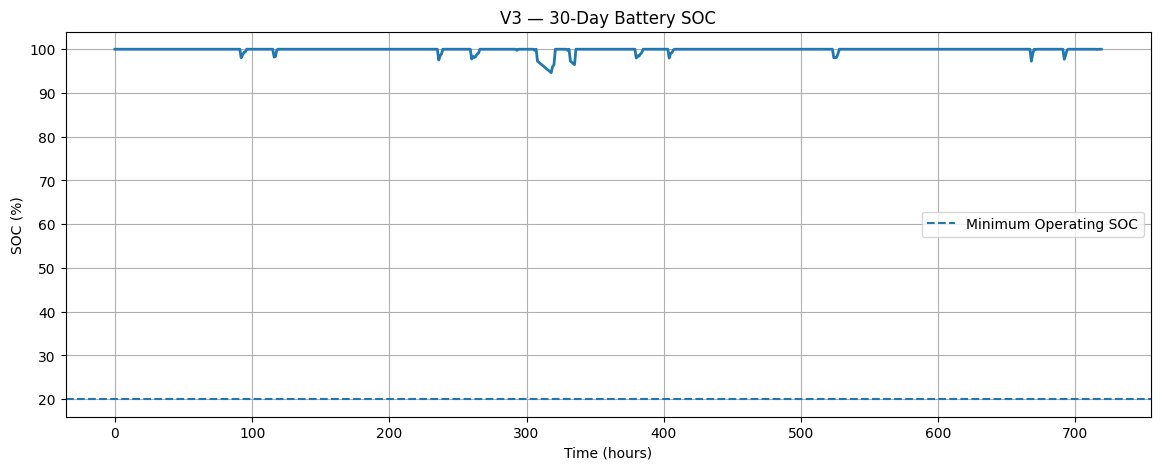

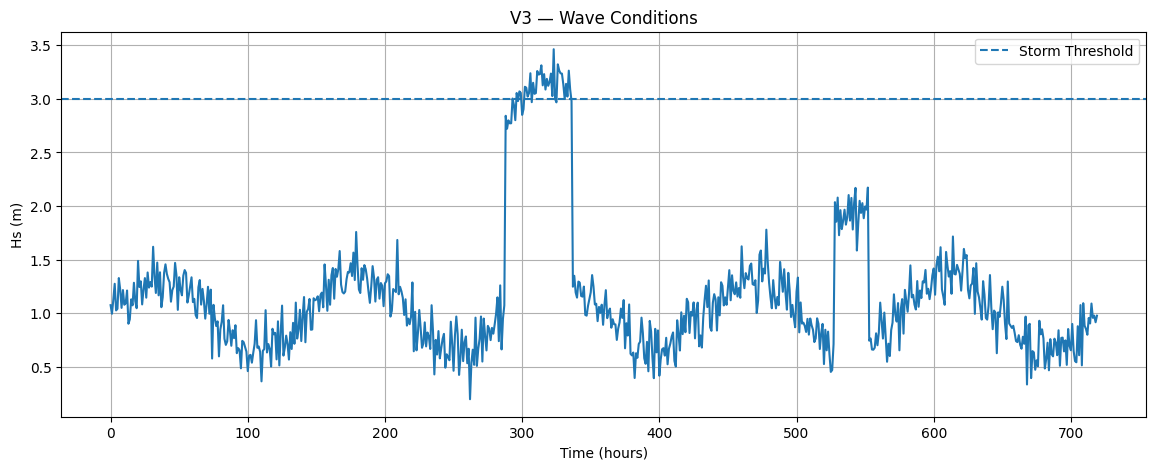

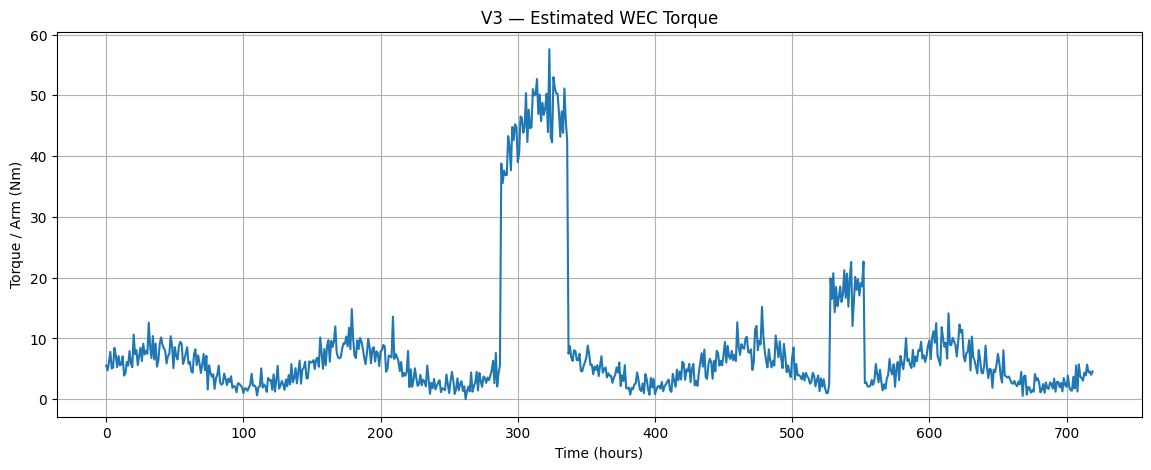

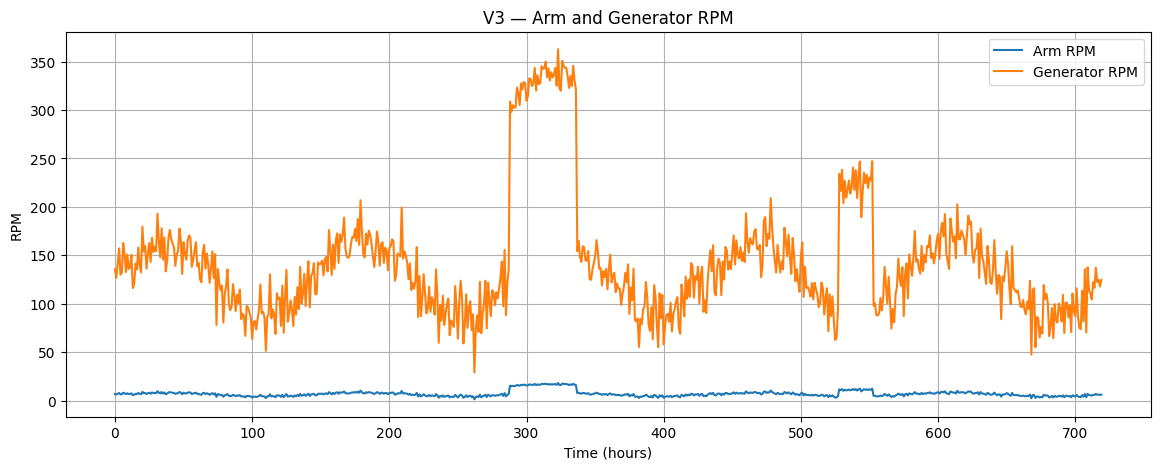

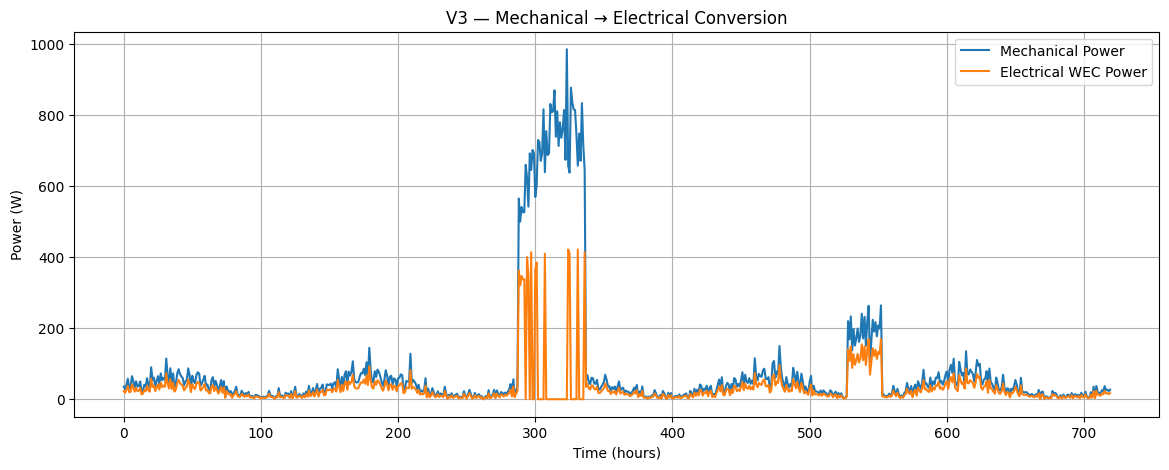

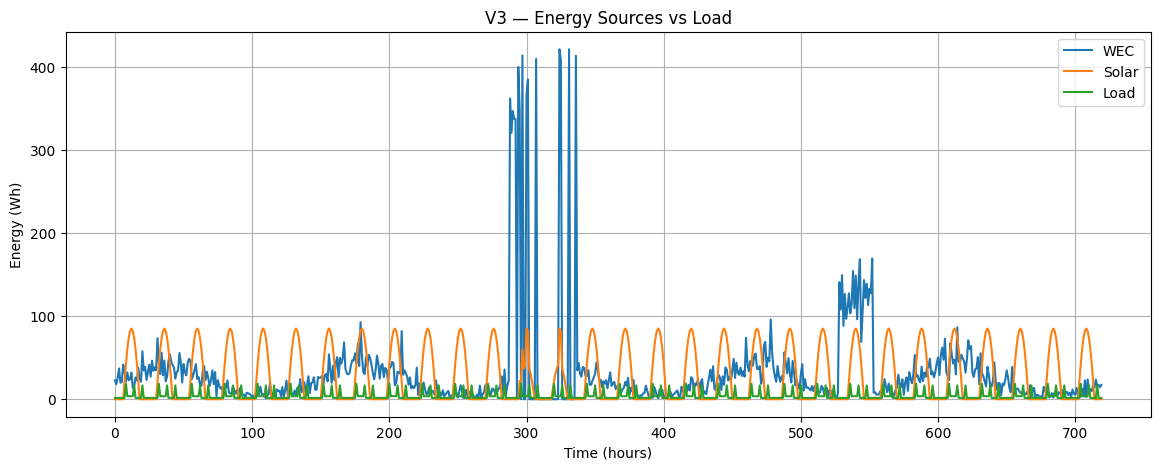

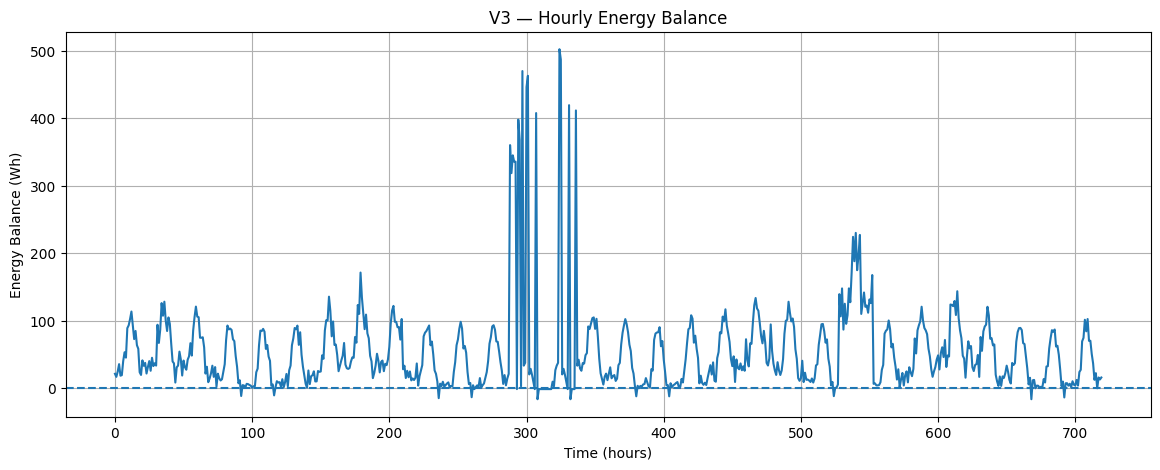

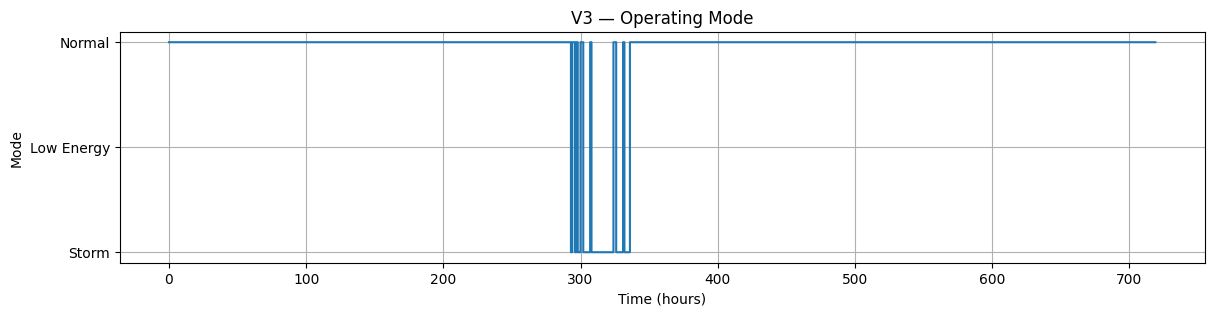

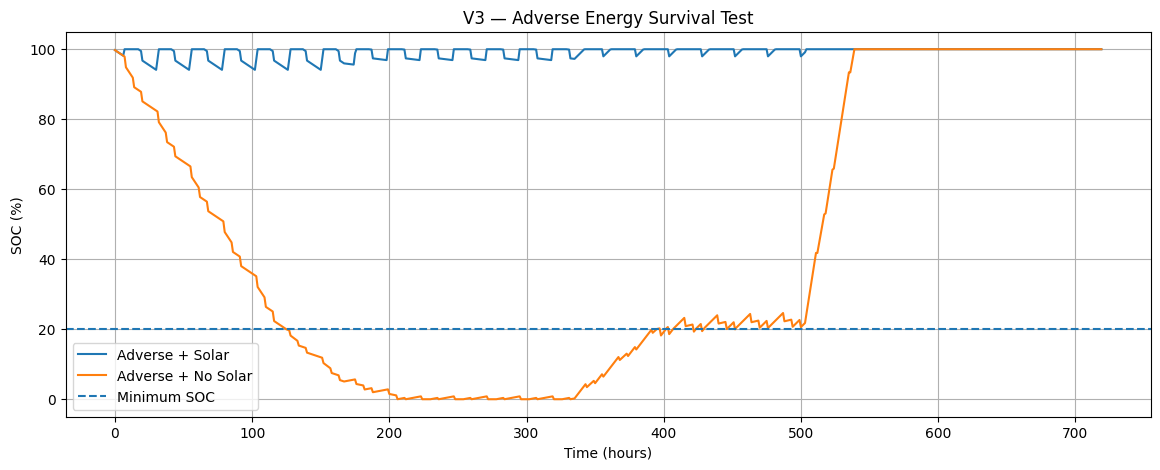



V3 — FINAL ENGINEERING DIAGNOSTIC
Minimum SOC        : 94.64%
Final SOC          : 100.00%
WEC energy         : 22.993 kWh
Solar energy       : 18.932 kWh
Load energy        : 2.862 kWh
Energy deficit     : 0.180 kWh
Storm hours        : 34 h
Low-energy hours   : 0 h
Survival           : 100.00%


V3 SIMULATION COMPLETE.
Do NOT use the result as experimental validation.
Replace torque calibration with prototype measurements
before freezing the final WEC power curve.


In [ ]:
# ================================================================
# SIH SMART BUOY — V3
# MECHANICAL → ELECTRICAL → BATTERY AUTONOMY MODEL
# ================================================================
#
# 9 WEC ARMS
# 640 Wh LiFePO4 battery
# Solar + WEC hybrid energy system
#
# ENERGY CHAIN:
#
# Wave Height
#     ↓
# Arm Displacement
#     ↓
# Arm Angular Displacement
#     ↓
# Arm Angular Velocity
#     ↓
# Hydrodynamic Torque
#     ↓
# Mechanical Power = Torque × Angular Velocity
#     ↓
# Gearbox
#     ↓
# Generator RPM
#     ↓
# Generator Efficiency
#     ↓
# Controller Efficiency
#     ↓
# WEC Electrical Power
#     ↓
# Battery SOC
#
# Includes:
#   - Normal operation
#   - Low-energy mode
#   - Storm protection
#   - Solar
#   - Detailed load model
#   - 30-day simulation
#   - Constant-wave scenarios
#   - Adverse low-wave scenarios
#   - 7-day / 14-day / 30-day no-solar stress tests
#
# IMPORTANT:
# Torque coefficient and load assumptions are MODEL PARAMETERS.
# They must eventually be replaced by prototype measurements.
# ================================================================


# ================================================================
# 1. IMPORTS
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass


# ================================================================
# 2. ENGINEERING PARAMETERS
# ================================================================

@dataclass
class P:

    # ------------------------------------------------------------
    # SIMULATION
    # ------------------------------------------------------------

    simulation_days: int = 30
    timestep_hours: float = 1.0

    # ------------------------------------------------------------
    # WEC GEOMETRY
    # ------------------------------------------------------------

    number_of_arms: int = 9

    arm_length_m: float = 0.55

    # Fraction of significant wave height transferred
    # to effective arm-end motion.
    wave_to_arm_motion_ratio: float = 0.35

    # ------------------------------------------------------------
    # WAVE / ARM DYNAMICS
    # ------------------------------------------------------------

    cut_in_wave_height_m: float = 0.25

    storm_wave_height_m: float = 3.0

    # ------------------------------------------------------------
    # TORQUE MODEL
    # ------------------------------------------------------------
    #
    # Torque model:
    #
    # T = T_ref × (Hs / H_ref)^2
    #
    # This is a CALIBRATION parameter.
    #
    # Replace T_ref with measured prototype torque.
    #

    reference_wave_height_m: float = 1.0

    reference_torque_per_arm_Nm: float = 8.0

    # Torque scaling exponent
    torque_wave_exponent: float = 2.0

    # Hydrodynamic capture factor
    hydrodynamic_efficiency: float = 0.60

    # ------------------------------------------------------------
    # DRIVE TRAIN
    # ------------------------------------------------------------

    gearbox_ratio: float = 20.0

    drivetrain_efficiency: float = 0.90

    # ------------------------------------------------------------
    # GENERATOR
    # ------------------------------------------------------------

    generator_rated_power_per_arm_W: float = 75.0

    generator_efficiency: float = 0.75

    controller_efficiency: float = 0.95

    generator_cut_in_rpm: float = 50.0

    generator_rated_rpm: float = 3000.0

    # ------------------------------------------------------------
    # BATTERY
    # ------------------------------------------------------------

    battery_voltage_V: float = 12.8

    battery_capacity_Ah: float = 50.0

    battery_charge_efficiency: float = 0.95

    battery_discharge_efficiency: float = 0.95

    initial_SOC: float = 1.0

    minimum_operating_SOC: float = 0.20

    maximum_SOC: float = 1.0

    # ------------------------------------------------------------
    # SOLAR
    # ------------------------------------------------------------

    solar_panel_power_W: float = 100.0

    solar_efficiency: float = 0.85

    storm_solar_factor: float = 0.50

    # ------------------------------------------------------------
    # ELECTRONICS LOAD
    # ------------------------------------------------------------

    MCU_standby_W: float = 0.8

    sensor_standby_W: float = 0.3

    power_management_W: float = 0.3

    data_logger_W: float = 0.2

    # ------------------------------------------------------------
    # SENSOR OPERATION
    # ------------------------------------------------------------

    sensor_active_power_W: float = 2.0

    sensor_hours_per_day: float = 6.0

    # ------------------------------------------------------------
    # COMMUNICATION
    # ------------------------------------------------------------

    communication_power_W: float = 15.0

    communication_duration_hours: float = 0.10

    communications_per_day: int = 3

    # ------------------------------------------------------------
    # LOW ENERGY MODE
    # ------------------------------------------------------------

    low_energy_load_reduction: float = 0.50

    # ------------------------------------------------------------
    # STORM
    # ------------------------------------------------------------

    storm_wec_shutdown: bool = True


p = P()


# ================================================================
# 3. DERIVED PARAMETERS
# ================================================================

battery_capacity_Wh = (
    p.battery_voltage_V *
    p.battery_capacity_Ah
)

simulation_hours = int(
    p.simulation_days *
    24 /
    p.timestep_hours
)

total_generator_rating_W = (
    p.number_of_arms *
    p.generator_rated_power_per_arm_W
)

print("=" * 70)
print("SIH SMART BUOY — V3 ENGINEERING MODEL")
print("=" * 70)

print(f"Battery capacity       : {battery_capacity_Wh:.1f} Wh")
print(f"WEC arms               : {p.number_of_arms}")
print(f"Arm length             : {p.arm_length_m:.2f} m")
print(f"Torque @ 1 m/arm      : {p.reference_torque_per_arm_Nm:.2f} Nm")
print(f"Gear ratio             : 1:{p.gearbox_ratio:.1f}")
print(f"Generator/arm          : {p.generator_rated_power_per_arm_W:.1f} W")
print(f"Total generator rating : {total_generator_rating_W:.1f} W")
print(f"Simulation duration    : {simulation_hours} h")

print("=" * 70)


# ================================================================
# 4. WAVE MODEL
# ================================================================

np.random.seed(42)


def generate_wave_height(hour):

    day = hour / 24.0

    # Normal variability
    long_variation = (
        0.35 *
        np.sin(
            2 * np.pi * day / 6.0
        )
    )

    short_variation = np.random.normal(
        0,
        0.15
    )

    Hs = (
        1.0 +
        long_variation +
        short_variation
    )

    # Storm event 1
    if 12 <= day <= 14:
        Hs += 1.8

    # Storm event 2
    if 22 <= day <= 23:
        Hs += 1.3

    return max(
        0.1,
        Hs
    )


# ================================================================
# 5. WAVE PERIOD
# ================================================================

def estimate_wave_period(Hs):

    return (
        4.5 +
        1.5 *
        np.sqrt(Hs)
    )


# ================================================================
# 6. ARM MOTION
# ================================================================

def calculate_arm_motion(Hs):

    effective_vertical_motion = (
        Hs *
        p.wave_to_arm_motion_ratio
    )

    angular_displacement = (
        effective_vertical_motion /
        p.arm_length_m
    )

    return (
        effective_vertical_motion,
        angular_displacement
    )


# ================================================================
# 7. ARM ANGULAR VELOCITY
# ================================================================

def calculate_angular_velocity(
    angular_displacement,
    wave_period
):

    omega_wave = (
        2 *
        np.pi /
        wave_period
    )

    angular_velocity = (
        angular_displacement *
        omega_wave
    )

    return angular_velocity


# ================================================================
# 8. ARM RPM
# ================================================================

def calculate_arm_rpm(
    angular_velocity
):

    return (
        angular_velocity *
        60 /
        (2 * np.pi)
    )


# ================================================================
# 9. HYDRODYNAMIC TORQUE
# ================================================================

def calculate_torque(Hs):

    if Hs < p.cut_in_wave_height_m:

        return 0.0

    torque = (
        p.reference_torque_per_arm_Nm *
        (
            Hs /
            p.reference_wave_height_m
        ) ** p.torque_wave_exponent
    )

    torque *= p.hydrodynamic_efficiency

    return max(
        0.0,
        torque
    )


# ================================================================
# 10. MECHANICAL POWER
# ================================================================

def calculate_mechanical_power(
    torque,
    angular_velocity
):

    return (
        torque *
        angular_velocity
    )


# ================================================================
# 11. GENERATOR RPM
# ================================================================

def calculate_generator_rpm(
    arm_rpm
):

    return (
        arm_rpm *
        p.gearbox_ratio
    )


# ================================================================
# 12. GENERATOR ELECTRICAL POWER
# ================================================================

def calculate_generator_power(
    mechanical_power_per_arm,
    generator_rpm,
    storm=False
):

    if storm and p.storm_wec_shutdown:

        return 0.0

    if (
        generator_rpm <
        p.generator_cut_in_rpm
    ):

        return 0.0

    # Mechanical power entering gearbox
    gearbox_output = (
        mechanical_power_per_arm *
        p.drivetrain_efficiency
    )

    # Generator conversion
    electrical_power = (
        gearbox_output *
        p.generator_efficiency
    )

    # Controller
    electrical_power *= (
        p.controller_efficiency
    )

    # Generator rating
    electrical_power = min(
        electrical_power,
        p.generator_rated_power_per_arm_W
    )

    return max(
        0.0,
        electrical_power
    )


# ================================================================
# 13. SOLAR MODEL
# ================================================================

def calculate_solar_power(
    hour,
    storm=False
):

    hour_of_day = hour % 24

    sunrise = 6
    sunset = 18

    if (
        hour_of_day < sunrise or
        hour_of_day >= sunset
    ):

        return 0.0

    solar_position = (
        hour_of_day -
        sunrise
    ) / (
        sunset -
        sunrise
    )

    solar_curve = np.sin(
        np.pi *
        solar_position
    )

    power = (
        p.solar_panel_power_W *
        solar_curve *
        p.solar_efficiency
    )

    if storm:

        power *= (
            p.storm_solar_factor
        )

    return max(
        0.0,
        power
    )


# ================================================================
# 14. DETAILED LOAD MODEL
# ================================================================

def calculate_load(
    hour,
    low_energy_mode=False
):

    hour_of_day = hour % 24

    # ------------------------------------------------------------
    # Continuous loads
    # ------------------------------------------------------------

    load = (
        p.MCU_standby_W +
        p.sensor_standby_W +
        p.power_management_W +
        p.data_logger_W
    )

    # ------------------------------------------------------------
    # Sensor operation
    # ------------------------------------------------------------

    sensor_start = 8

    sensor_end = (
        sensor_start +
        p.sensor_hours_per_day
    )

    if (
        sensor_start <=
        hour_of_day <
        sensor_end
    ):

        load += (
            p.sensor_active_power_W
        )

    # ------------------------------------------------------------
    # Communication
    # ------------------------------------------------------------

    communication_hours = [
        8,
        14,
        20
    ]

    active_times = (
        communication_hours[
            :p.communications_per_day
        ]
    )

    for comm_time in active_times:

        if (
            abs(
                hour_of_day -
                comm_time
            ) <
            p.communication_duration_hours / 2
        ):

            load += (
                p.communication_power_W
            )

    # ------------------------------------------------------------
    # Low-energy mode
    # ------------------------------------------------------------

    if low_energy_mode:

        load *= (
            1 -
            p.low_energy_load_reduction
        )

    return load


# ================================================================
# 15. BATTERY MODEL
# ================================================================

def update_battery(
    soc,
    generation_Wh,
    load_Wh
):

    battery_energy = (
        soc *
        battery_capacity_Wh
    )

    net_energy = (
        generation_Wh -
        load_Wh
    )

    if net_energy > 0:

        battery_energy += (
            net_energy *
            p.battery_charge_efficiency
        )

    else:

        battery_energy -= (
            abs(net_energy) /
            p.battery_discharge_efficiency
        )

    battery_energy = min(
        battery_energy,
        battery_capacity_Wh
    )

    battery_energy = max(
        battery_energy,
        0
    )

    return (
        battery_energy /
        battery_capacity_Wh
    )


# ================================================================
# 16. SIMULATION ENGINE
# ================================================================

def run_simulation(
    hours=simulation_hours,
    custom_wave_function=None,
    solar_enabled=True
):

    results = []

    soc = p.initial_SOC

    for hour in range(hours):

        # --------------------------------------------------------
        # WAVE
        # --------------------------------------------------------

        if custom_wave_function:

            Hs = custom_wave_function(
                hour
            )

        else:

            Hs = generate_wave_height(
                hour
            )

        storm = (
            Hs >=
            p.storm_wave_height_m
        )

        # --------------------------------------------------------
        # OPERATING MODE
        # --------------------------------------------------------

        if storm:

            mode = "STORM PROTECTION"

        elif soc <= p.minimum_operating_SOC:

            mode = "LOW ENERGY"

        else:

            mode = "NORMAL"

        low_energy = (
            mode ==
            "LOW ENERGY"
        )

        # --------------------------------------------------------
        # ARM MOTION
        # --------------------------------------------------------

        displacement, \
        angular_displacement = \
            calculate_arm_motion(Hs)

        period = (
            estimate_wave_period(Hs)
        )

        omega = (
            calculate_angular_velocity(
                angular_displacement,
                period
            )
        )

        arm_rpm = (
            calculate_arm_rpm(
                omega
            )
        )

        # --------------------------------------------------------
        # TORQUE
        # --------------------------------------------------------

        torque_per_arm = (
            calculate_torque(Hs)
        )

        # --------------------------------------------------------
        # MECHANICAL POWER
        # --------------------------------------------------------

        mechanical_power_per_arm = (
            calculate_mechanical_power(
                torque_per_arm,
                omega
            )
        )

        total_mechanical_power = (
            mechanical_power_per_arm *
            p.number_of_arms
        )

        # --------------------------------------------------------
        # GENERATOR RPM
        # --------------------------------------------------------

        generator_rpm = (
            calculate_generator_rpm(
                arm_rpm
            )
        )

        # --------------------------------------------------------
        # GENERATOR ELECTRICAL POWER
        # --------------------------------------------------------

        electrical_power_per_arm = (
            calculate_generator_power(
                mechanical_power_per_arm,
                generator_rpm,
                storm
            )
        )

        total_wec_power = (
            electrical_power_per_arm *
            p.number_of_arms
        )

        # --------------------------------------------------------
        # WEC ENERGY
        # --------------------------------------------------------

        wec_energy = (
            total_wec_power *
            p.timestep_hours
        )

        # --------------------------------------------------------
        # SOLAR
        # --------------------------------------------------------

        if solar_enabled:

            solar_power = (
                calculate_solar_power(
                    hour,
                    storm
                )

            )

        else:

            solar_power = 0.0

        solar_energy = (
            solar_power *
            p.timestep_hours
        )

        # --------------------------------------------------------
        # LOAD
        # --------------------------------------------------------

        load_power = (
            calculate_load(
                hour,
                low_energy
            )
        )

        load_energy = (
            load_power *
            p.timestep_hours
        )

        # --------------------------------------------------------
        # TOTAL ENERGY
        # --------------------------------------------------------

        total_generation = (
            wec_energy +
            solar_energy
        )

        energy_balance = (
            total_generation -
            load_energy
        )

        surplus = max(
            0,
            energy_balance
        )

        deficit = max(
            0,
            -energy_balance
        )

        # --------------------------------------------------------
        # BATTERY
        # --------------------------------------------------------

        soc = update_battery(
            soc,
            total_generation,
            load_energy
        )

        battery_energy = (
            soc *
            battery_capacity_Wh
        )

        # --------------------------------------------------------
        # SAVE
        # --------------------------------------------------------

        results.append({

            "Hour": hour,

            "Day": hour / 24,

            "Wave Height (m)": Hs,

            "Wave Period (s)": period,

            "Arm Displacement (m)": displacement,

            "Angular Displacement (rad)": (
                angular_displacement
            ),

            "Angular Velocity (rad/s)": (
                omega
            ),

            "Arm RPM": arm_rpm,

            "Generator RPM": generator_rpm,

            "Torque/Arm (Nm)": (
                torque_per_arm
            ),

            "Mechanical Power/Arm (W)": (
                mechanical_power_per_arm
            ),

            "Total Mechanical Power (W)": (
                total_mechanical_power
            ),

            "WEC Power (W)": (
                total_wec_power
            ),

            "WEC Energy (Wh)": (
                wec_energy
            ),

            "Solar Power (W)": (
                solar_power
            ),

            "Solar Energy (Wh)": (
                solar_energy
            ),

            "Load Power (W)": (
                load_power
            ),

            "Load Energy (Wh)": (
                load_energy
            ),

            "Total Generation (Wh)": (
                total_generation
            ),

            "Energy Balance (Wh)": (
                energy_balance
            ),

            "Energy Surplus (Wh)": (
                surplus
            ),

            "Energy Deficit (Wh)": (
                deficit
            ),

            "SOC (%)": (
                soc * 100
            ),

            "Battery Energy (Wh)": (
                battery_energy
            ),

            "Storm": storm,

            "Operating Mode": mode
        })

    return pd.DataFrame(results)


# ================================================================
# 17. RUN MAIN 30-DAY SIMULATION
# ================================================================

df = run_simulation()


# ================================================================
# 18. ANALYSIS
# ================================================================

total_wec = (
    df["WEC Energy (Wh)"].sum()
)

total_solar = (
    df["Solar Energy (Wh)"].sum()
)

total_generation = (
    df["Total Generation (Wh)"].sum()
)

total_load = (
    df["Load Energy (Wh)"].sum()
)

total_surplus = (
    df["Energy Surplus (Wh)"].sum()
)

total_deficit = (
    df["Energy Deficit (Wh)"].sum()
)

minimum_soc = (
    df["SOC (%)"].min()
)

final_soc = (
    df["SOC (%)"].iloc[-1]
)

average_soc = (
    df["SOC (%)"].mean()
)

storm_hours = (
    df["Storm"].sum()
)

low_energy_hours = (
    df["Operating Mode"]
    .eq("LOW ENERGY")
    .sum()
)

if total_generation > 0:

    wec_percentage = (
        total_wec /
        total_generation
    ) * 100

    solar_percentage = (
        total_solar /
        total_generation
    ) * 100

else:

    wec_percentage = 0
    solar_percentage = 0


survival_hours = (
    df["SOC (%)"] >
    p.minimum_operating_SOC * 100
).sum()

survival_percentage = (
    survival_hours /
    len(df)
) * 100


# ================================================================
# 19. SUMMARY
# ================================================================

summary = pd.DataFrame({

    "Parameter": [

        "Battery Capacity",

        "WEC Arms",

        "Arm Length",

        "Reference Torque / Arm",

        "Gearbox Ratio",

        "Generator Rating / Arm",

        "Total Generator Rating",

        "Initial SOC",

        "Final SOC",

        "Minimum SOC",

        "Average SOC",

        "Total WEC Energy",

        "Total Solar Energy",

        "Total Generation",

        "Total Load",

        "Energy Surplus",

        "Energy Deficit",

        "Storm Hours",

        "Low-Energy Hours",

        "Autonomous Survival",

        "WEC Contribution",

        "Solar Contribution"
    ],

    "Value": [

        f"{battery_capacity_Wh:.2f} Wh",

        f"{p.number_of_arms}",

        f"{p.arm_length_m:.2f} m",

        f"{p.reference_torque_per_arm_Nm:.2f} Nm",

        f"1:{p.gearbox_ratio:.1f}",

        f"{p.generator_rated_power_per_arm_W:.1f} W",

        f"{total_generator_rating_W:.1f} W",

        f"{p.initial_SOC*100:.2f}%",

        f"{final_soc:.2f}%",

        f"{minimum_soc:.2f}%",

        f"{average_soc:.2f}%",

        f"{total_wec/1000:.3f} kWh",

        f"{total_solar/1000:.3f} kWh",

        f"{total_generation/1000:.3f} kWh",

        f"{total_load/1000:.3f} kWh",

        f"{total_surplus/1000:.3f} kWh",

        f"{total_deficit/1000:.3f} kWh",

        f"{storm_hours:.0f} h",

        f"{low_energy_hours:.0f} h",

        f"{survival_percentage:.2f}%",

        f"{wec_percentage:.2f}%",

        f"{solar_percentage:.2f}%"
    ]
})


print("\n")
print("=" * 70)
print("V3 — 30-DAY ENERGY RESULTS")
print("=" * 70)

display(summary)


# ================================================================
# 20. DAILY ANALYSIS
# ================================================================

df["Day Number"] = (
    df["Hour"] // 24
) + 1

daily = df.groupby(
    "Day Number"
).agg({

    "Wave Height (m)": "mean",

    "Torque/Arm (Nm)": "mean",

    "Arm RPM": "mean",

    "Generator RPM": "mean",

    "WEC Energy (Wh)": "sum",

    "Solar Energy (Wh)": "sum",

    "Load Energy (Wh)": "sum",

    "Energy Surplus (Wh)": "sum",

    "Energy Deficit (Wh)": "sum",

    "SOC (%)": "mean"

})

daily["Net Energy (Wh)"] = (
    daily["WEC Energy (Wh)"] +
    daily["Solar Energy (Wh)"] -
    daily["Load Energy (Wh)"]
)


print("\n")
print("=" * 70)
print("V3 — DAILY ANALYSIS")
print("=" * 70)

display(
    daily.round(3)
)


# ================================================================
# 21. WAVE SCENARIO FUNCTION
# ================================================================

def constant_wave(
    Hs
):

    def wave_function(hour):

        return Hs

    return wave_function


# ================================================================
# 22. CONSTANT WAVE SCENARIOS
# ================================================================

scenario_values = [
    0.25,
    0.50,
    1.00,
    2.00,
    3.00
]

scenario_results = []


for Hs in scenario_values:

    scenario = run_simulation(
        hours=720,
        custom_wave_function=constant_wave(Hs)
    )

    scenario_results.append({

        "Hs (m)": Hs,

        "Average Torque/Arm (Nm)": (
            scenario["Torque/Arm (Nm)"].mean()
        ),

        "Average Arm RPM": (
            scenario["Arm RPM"].mean()
        ),

        "Average Generator RPM": (
            scenario["Generator RPM"].mean()
        ),

        "Average Mechanical Power (W)": (
            scenario[
                "Total Mechanical Power (W)"
            ].mean()
        ),

        "Average WEC Power (W)": (
            scenario["WEC Power (W)"].mean()
        ),

        "Minimum SOC (%)": (
            scenario["SOC (%)"].min()
        ),

        "Final SOC (%)": (
            scenario["SOC (%)"].iloc[-1]
        ),

        "WEC Energy (kWh)": (
            scenario[
                "WEC Energy (Wh)"
            ].sum() / 1000
        ),

        "Load Energy (kWh)": (
            scenario[
                "Load Energy (Wh)"
            ].sum() / 1000
        )
    })


scenario_table = pd.DataFrame(
    scenario_results
)


print("\n")
print("=" * 70)
print("V3 — CONSTANT WAVE SCENARIOS")
print("=" * 70)

display(
    scenario_table.round(3)
)


# ================================================================
# 23. ADVERSE LOW-WAVE SCENARIO
# ================================================================

def adverse_low_wave(hour):

    # First 7 days:
    # extremely low wave

    if hour < 7 * 24:

        return 0.25

    # Next 7 days:
    # low wave

    elif hour < 14 * 24:

        return 0.40

    # Next 7 days:
    # moderate

    elif hour < 21 * 24:

        return 0.60

    # Final 9 days:
    # normal

    else:

        return 1.0


adverse = run_simulation(
    hours=720,
    custom_wave_function=adverse_low_wave
)


print("\n")
print("=" * 70)
print("ADVERSE 30-DAY SCENARIO")
print("=" * 70)

print(
    f"Minimum SOC : "
    f"{adverse['SOC (%)'].min():.2f}%"
)

print(
    f"Final SOC   : "
    f"{adverse['SOC (%)'].iloc[-1]:.2f}%"
)

print(
    f"WEC energy  : "
    f"{adverse['WEC Energy (Wh)'].sum()/1000:.3f} kWh"
)

print(
    f"Load energy : "
    f"{adverse['Load Energy (Wh)'].sum()/1000:.3f} kWh"
)


# ================================================================
# 24. NO-SOLAR STRESS TEST
# ================================================================

no_solar = run_simulation(
    hours=720,
    custom_wave_function=adverse_low_wave,
    solar_enabled=False
)


print("\n")
print("=" * 70)
print("NO-SOLAR + ADVERSE WAVE STRESS TEST")
print("=" * 70)

print(
    f"Minimum SOC : "
    f"{no_solar['SOC (%)'].min():.2f}%"
)

print(
    f"Final SOC   : "
    f"{no_solar['SOC (%)'].iloc[-1]:.2f}%"
)

print(
    f"Low-energy hours : "
    f"{no_solar['Operating Mode'].eq('LOW ENERGY').sum()} h"
)


# ================================================================
# 25. PLOTS
# ================================================================

# ---------------------------------------------------------------
# SOC
# ---------------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(
    df["Hour"],
    df["SOC (%)"],
    linewidth=2
)

plt.axhline(
    p.minimum_operating_SOC * 100,
    linestyle="--",
    label="Minimum Operating SOC"
)

plt.xlabel("Time (hours)")
plt.ylabel("SOC (%)")
plt.title("V3 — 30-Day Battery SOC")

plt.grid(True)
plt.legend()

plt.show()


# ---------------------------------------------------------------
# WAVE
# ---------------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(
    df["Hour"],
    df["Wave Height (m)"]
)

plt.axhline(
    p.storm_wave_height_m,
    linestyle="--",
    label="Storm Threshold"
)

plt.xlabel("Time (hours)")
plt.ylabel("Hs (m)")
plt.title("V3 — Wave Conditions")

plt.grid(True)
plt.legend()

plt.show()


# ---------------------------------------------------------------
# TORQUE
# ---------------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(
    df["Hour"],
    df["Torque/Arm (Nm)"]
)

plt.xlabel("Time (hours)")
plt.ylabel("Torque / Arm (Nm)")
plt.title("V3 — Estimated WEC Torque")

plt.grid(True)

plt.show()


# ---------------------------------------------------------------
# ARM / GENERATOR RPM
# ---------------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(
    df["Hour"],
    df["Arm RPM"],
    label="Arm RPM"
)

plt.plot(
    df["Hour"],
    df["Generator RPM"],
    label="Generator RPM"
)

plt.xlabel("Time (hours)")
plt.ylabel("RPM")
plt.title("V3 — Arm and Generator RPM")

plt.grid(True)
plt.legend()

plt.show()


# ---------------------------------------------------------------
# MECHANICAL VS ELECTRICAL
# ---------------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(
    df["Hour"],
    df["Total Mechanical Power (W)"],
    label="Mechanical Power"
)

plt.plot(
    df["Hour"],
    df["WEC Power (W)"],
    label="Electrical WEC Power"
)

plt.xlabel("Time (hours)")
plt.ylabel("Power (W)")
plt.title("V3 — Mechanical → Electrical Conversion")

plt.grid(True)
plt.legend()

plt.show()


# ---------------------------------------------------------------
# WEC / SOLAR / LOAD
# ---------------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(
    df["Hour"],
    df["WEC Energy (Wh)"],
    label="WEC"
)

plt.plot(
    df["Hour"],
    df["Solar Energy (Wh)"],
    label="Solar"
)

plt.plot(
    df["Hour"],
    df["Load Energy (Wh)"],
    label="Load"
)

plt.xlabel("Time (hours)")
plt.ylabel("Energy (Wh)")
plt.title("V3 — Energy Sources vs Load")

plt.grid(True)
plt.legend()

plt.show()


# ---------------------------------------------------------------
# ENERGY BALANCE
# ---------------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(
    df["Hour"],
    df["Energy Balance (Wh)"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Time (hours)")
plt.ylabel("Energy Balance (Wh)")
plt.title("V3 — Hourly Energy Balance")

plt.grid(True)

plt.show()


# ---------------------------------------------------------------
# OPERATING MODE
# ---------------------------------------------------------------

mode_numeric = (
    df["Operating Mode"].map({
        "NORMAL": 1,
        "LOW ENERGY": 0.5,
        "STORM PROTECTION": 0
    })
)

plt.figure(figsize=(14,3))

plt.step(
    df["Hour"],
    mode_numeric,
    where="post"
)

plt.yticks(
    [0, 0.5, 1],
    [
        "Storm",
        "Low Energy",
        "Normal"
    ]
)

plt.xlabel("Time (hours)")
plt.ylabel("Mode")

plt.title(
    "V3 — Operating Mode"
)

plt.grid(True)

plt.show()


# ================================================================
# 26. STRESS TEST PLOT
# ================================================================

plt.figure(figsize=(14,5))

plt.plot(
    adverse["Hour"],
    adverse["SOC (%)"],
    label="Adverse + Solar"
)

plt.plot(
    no_solar["Hour"],
    no_solar["SOC (%)"],
    label="Adverse + No Solar"
)

plt.axhline(
    p.minimum_operating_SOC * 100,
    linestyle="--",
    label="Minimum SOC"
)

plt.xlabel("Time (hours)")
plt.ylabel("SOC (%)")

plt.title(
    "V3 — Adverse Energy Survival Test"
)

plt.grid(True)
plt.legend()

plt.show()


# ================================================================
# 27. EXPORT
# ================================================================

df.to_csv(
    "SIH_Buoy_V3_30_Day_Hourly.csv",
    index=False
)

daily.to_csv(
    "SIH_Buoy_V3_30_Day_Daily.csv"
)

summary.to_csv(
    "SIH_Buoy_V3_30_Day_Summary.csv",
    index=False
)

scenario_table.to_csv(
    "SIH_Buoy_V3_Wave_Scenarios.csv",
    index=False
)

adverse.to_csv(
    "SIH_Buoy_V3_Adverse_30_Day.csv",
    index=False
)

no_solar.to_csv(
    "SIH_Buoy_V3_NoSolar_Stress.csv",
    index=False
)


# ================================================================
# 28. FINAL DIAGNOSTIC
# ================================================================

print("\n")
print("=" * 70)
print("V3 — FINAL ENGINEERING DIAGNOSTIC")
print("=" * 70)

print(
    f"Minimum SOC        : "
    f"{minimum_soc:.2f}%"
)

print(
    f"Final SOC          : "
    f"{final_soc:.2f}%"
)

print(
    f"WEC energy         : "
    f"{total_wec/1000:.3f} kWh"
)

print(
    f"Solar energy       : "
    f"{total_solar/1000:.3f} kWh"
)

print(
    f"Load energy        : "
    f"{total_load/1000:.3f} kWh"
)

print(
    f"Energy deficit     : "
    f"{total_deficit/1000:.3f} kWh"
)

print(
    f"Storm hours        : "
    f"{storm_hours:.0f} h"
)

print(
    f"Low-energy hours   : "
    f"{low_energy_hours:.0f} h"
)

print(
    f"Survival           : "
    f"{survival_percentage:.2f}%"
)

print("\n")
print("V3 SIMULATION COMPLETE.")
print("Do NOT use the result as experimental validation.")
print("Replace torque calibration with prototype measurements")
print("before freezing the final WEC power curve.")


SIH SMART BUOY — V4 CALIBRATION + SURVIVAL MODEL
Battery                 : 640.0 Wh
WEC arms                : 9
Arm length              : 0.55 m
Reference torque        : 8.00 Nm
Gear ratio              : 1:20.0
Generator / arm         : 75.0 W
Total generator rating  : 675.0 W
Battery charge limit    : 320.0 W
Battery discharge limit : 320.0 W


V4 — NORMAL 30-DAY RESULT


,Scenario,Duration_days,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Curtailed_kWh,Unmet_Load_kWh,Minimum_SOC_pct,Final_SOC_pct,Storm_hours,Low_energy_hours,Load_Survival_pct
0,30-day Normal,30.0,18.21,18.932,37.142,2.862,34.254,-0.0,94.638,100.0,34,0,100.0




V4 — TORQUE SENSITIVITY


,Scenario,Duration_days,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Curtailed_kWh,Unmet_Load_kWh,Minimum_SOC_pct,Final_SOC_pct,Storm_hours,Low_energy_hours,Load_Survival_pct,Reference_Torque_Nm,Average_WEC_W,Average_Generator_RPM
0,2 Nm,30.0,4.553,18.932,23.484,2.862,20.581,-0.0,94.638,98.284,34,0,100.0,2,6.323,142.792
1,4 Nm,30.0,9.105,18.932,28.037,2.862,25.136,0.0,94.638,100.000,34,0,100.0,4,12.646,142.792
2,6 Nm,30.0,13.658,18.932,32.589,2.862,29.698,0.0,94.638,100.000,34,0,100.0,6,18.969,142.792
3,8 Nm,30.0,18.210,18.932,37.142,2.862,34.254,-0.0,94.638,100.000,34,0,100.0,8,25.292,142.792
4,10 Nm,30.0,22.763,18.932,41.694,2.862,38.809,0.0,94.638,100.000,34,0,100.0,10,31.615,142.792
5,12 Nm,30.0,27.315,18.932,46.247,2.862,43.363,0.0,94.638,100.000,34,0,100.0,12,37.938,142.792
6,15 Nm,30.0,33.755,18.932,52.687,2.862,49.804,0.0,94.638,100.000,34,0,100.0,15,46.882,142.792




V4 — GEARBOX SENSITIVITY


,Scenario,Duration_days,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Curtailed_kWh,Unmet_Load_kWh,Minimum_SOC_pct,Final_SOC_pct,Storm_hours,Low_energy_hours,Load_Survival_pct,Gearbox_Ratio,Average_Generator_RPM,Average_Generator_Efficiency,Average_WEC_W
0,5:1,30.0,2.441,18.932,21.372,2.862,18.427,0.0,94.112,95.954,34,0,100.0,5,35.698,0.024,3.390
1,10:1,30.0,10.950,18.932,29.882,2.862,26.977,-0.0,94.328,98.048,34,0,100.0,10,71.396,0.189,15.209
2,15:1,30.0,16.169,18.932,35.101,2.862,32.207,0.0,94.638,100.000,34,0,100.0,15,107.094,0.403,22.457
3,20:1,30.0,18.210,18.932,37.142,2.862,34.254,-0.0,94.638,100.000,34,0,100.0,20,142.792,0.509,25.292
4,25:1,30.0,19.478,18.932,38.410,2.862,35.525,-0.0,94.638,100.000,34,0,100.0,25,178.490,0.565,27.053
5,30:1,30.0,20.565,18.932,39.497,2.862,36.613,0.0,94.638,100.000,34,0,100.0,30,214.188,0.603,28.562


... (8 outputs left out)



V4 — TORQUE × GEARBOX MATRIX


,Torque_Nm,Gear_Ratio,Average_Generator_RPM,Average_Generator_Efficiency,Average_WEC_Power_W,Minimum_SOC_pct,Unmet_Load_kWh
0,2,5,35.698,0.024,0.847,94.112,0.0
1,2,10,71.396,0.189,3.802,94.166,0.0
2,2,15,107.094,0.403,5.614,94.638,-0.0
3,2,20,142.792,0.509,6.323,94.638,-0.0
4,2,25,178.490,0.565,6.763,94.638,0.0
5,2,30,214.188,0.603,7.141,94.638,-0.0
6,4,5,35.698,0.024,1.695,94.112,0.0
7,4,10,71.396,0.189,7.604,94.220,0.0
8,4,15,107.094,0.403,11.228,94.638,0.0
9,4,20,142.792,0.509,12.646,94.638,0.0




V4 — CONSTANT WAVE PHYSICS


,Hs_m,Torque_per_arm_Nm,Arm_RPM,Generator_RPM,Generator_Efficiency,Mechanical_Power_Total_W,WEC_Power_W,Minimum_SOC_pct,WEC_Energy_kWh,Unmet_Load_kWh
0,0.25,0.3,1.818,36.364,0.000,0.514,0.000,94.112,0.000,0.0
1,0.50,1.2,3.433,68.664,0.187,3.883,0.620,95.437,0.446,0.0
2,1.00,4.8,6.364,127.273,0.527,28.788,12.978,99.404,9.344,0.0
3,2.00,19.2,11.533,230.660,0.631,208.696,112.532,100.000,81.023,0.0
4,3.00,43.2,16.138,322.751,0.709,657.040,0.000,94.112,0.000,0.0


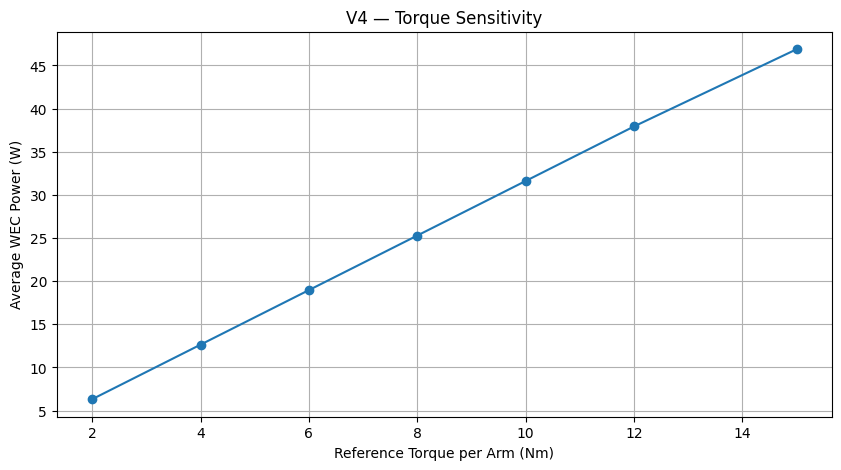

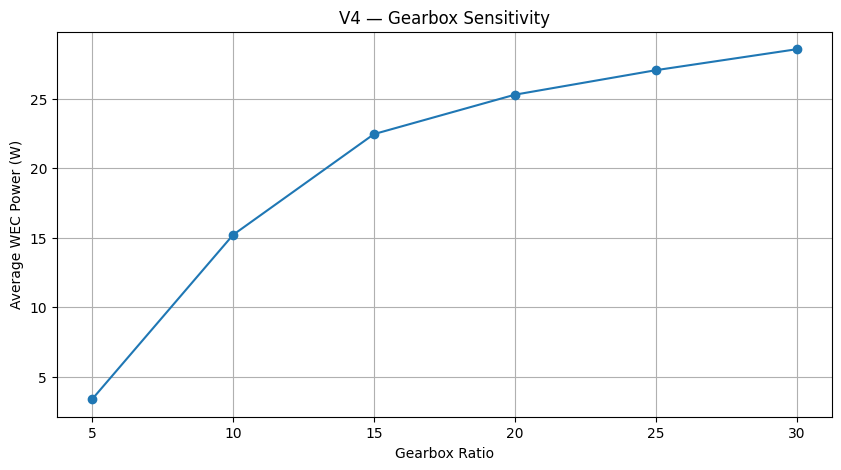

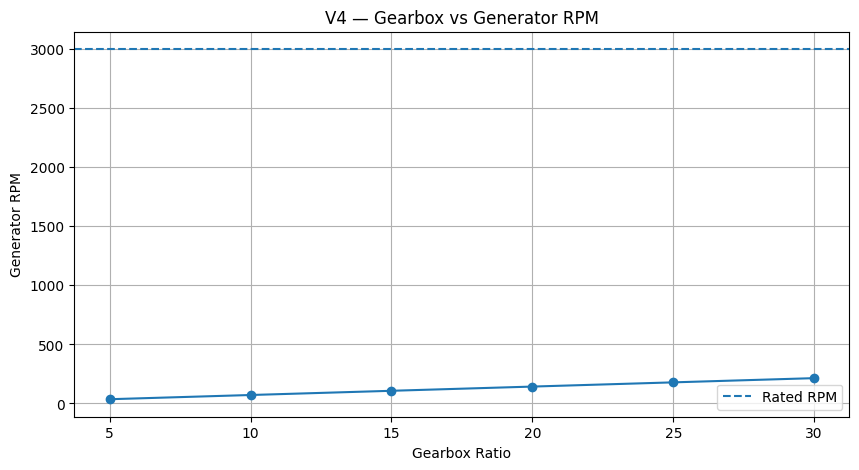

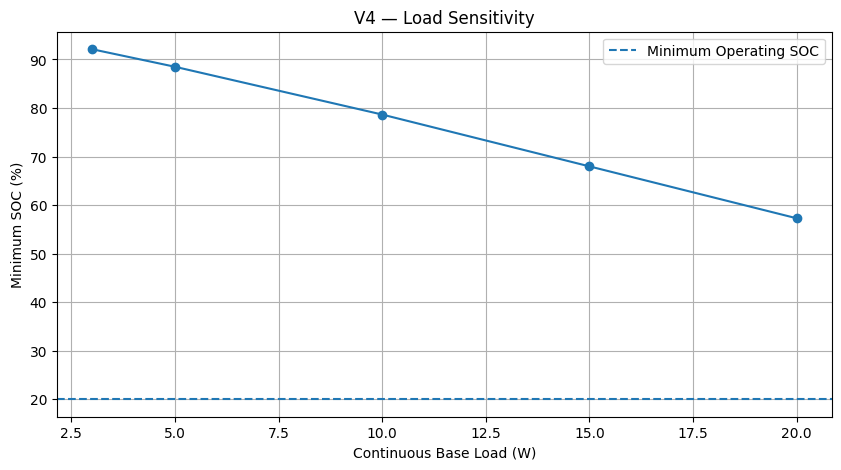

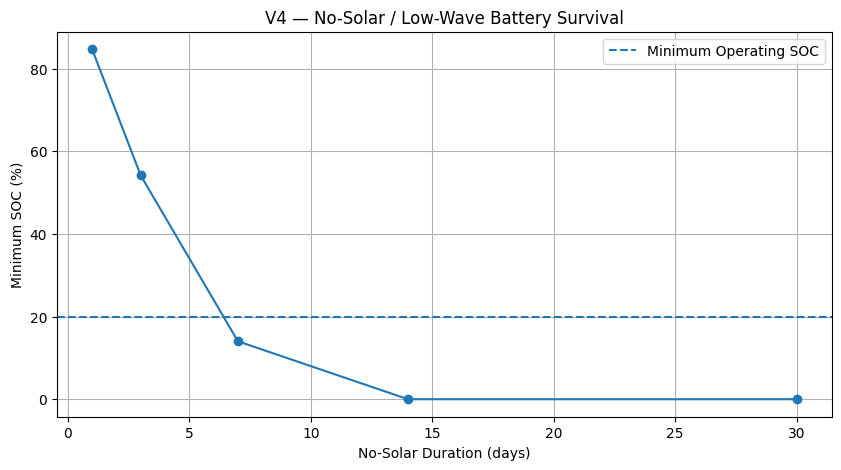

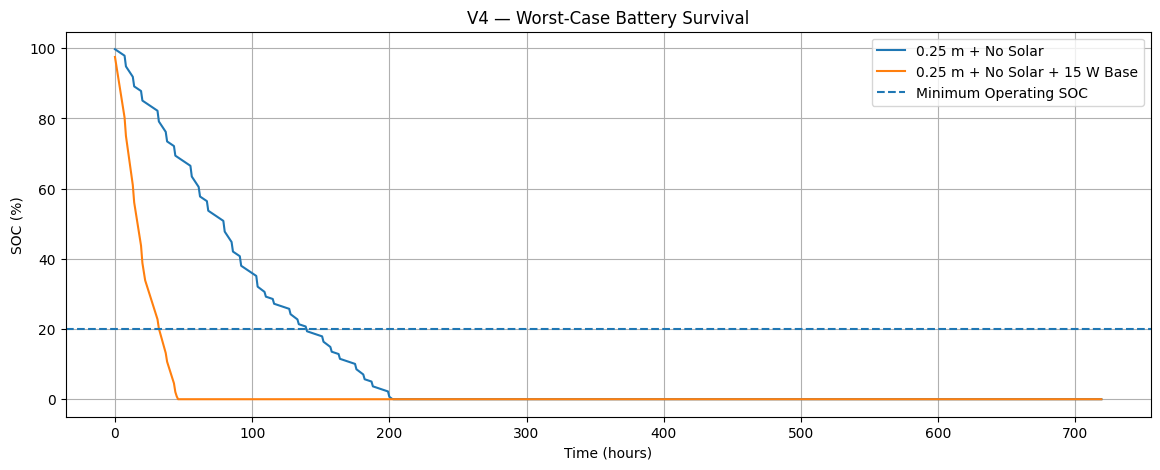

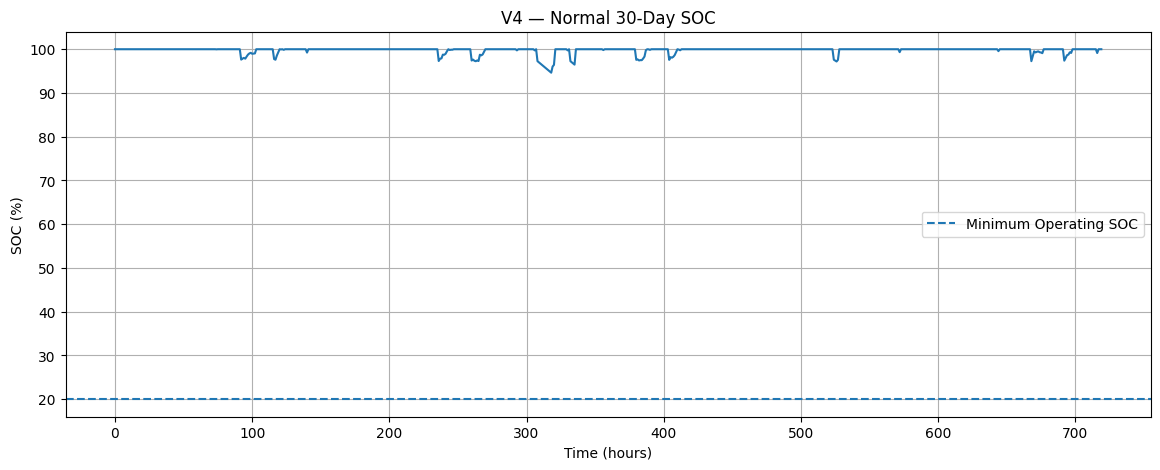

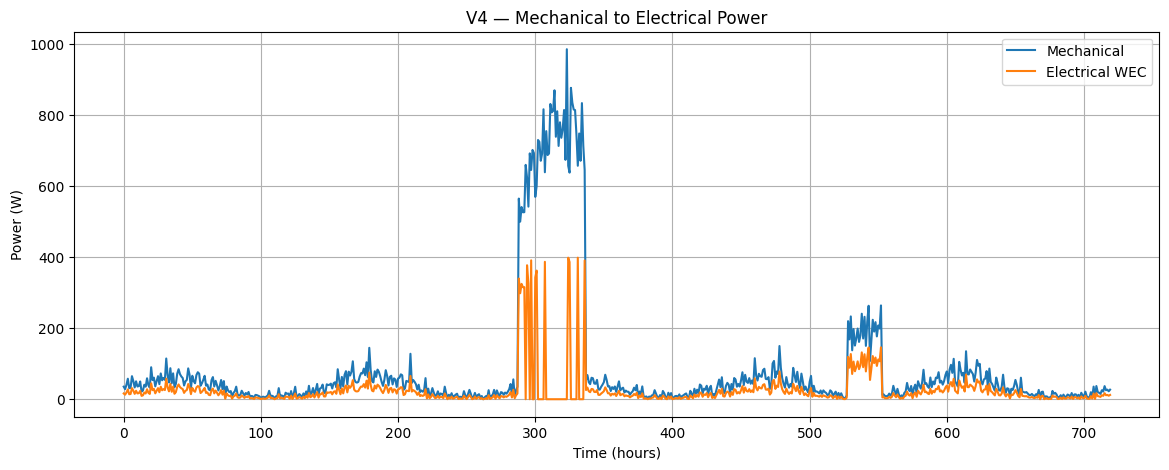



V4 — FINAL ENGINEERING DIAGNOSTIC

NORMAL 30-DAY:
Minimum SOC       : 94.64%
Final SOC         : 100.00%
WEC energy        : 18.210 kWh
Solar energy      : 18.932 kWh
Unmet load        : -0.000000 kWh

SEVERE LOW-WAVE + NO SOLAR:
Minimum SOC       : 0.00%
Final SOC         : 0.00%
Unmet load        : 1.029 kWh

COMBINED WORST CASE:
Minimum SOC       : 0.00%
Final SOC         : 0.00%
Unmet load        : 5.848 kWh


V4 COMPLETE

NEXT ENGINEERING STEP:

1. Replace the assumed torque with measured prototype torque.
2. Replace the assumed generator efficiency curve with datasheet data.
3. Select gearbox ratio from generator RPM operating range.
4. Validate the actual continuous electrical load.
5. Use the validated V4 envelope as the input to V5.
6. V5 = 1-year seasonal + 5-year degradation simulation.



In [ ]:
# ================================================================
# SIH SMART BUOY — V4
# CALIBRATION + SURVIVAL ENVELOPE MODEL
# ================================================================
#
# PURPOSE:
#   V4 does NOT try to prove the final 5-year design.
#
#   It establishes the operating/survival envelope before V5.
#
# MAIN STUDIES:
#
#   1. Torque sensitivity
#   2. Gearbox sensitivity
#   3. Generator RPM / efficiency
#   4. Battery charge/discharge limits
#   5. Load sensitivity
#   6. No-solar survival
#   7. Combined worst-case condition
#   8. Torque × gearbox matrix
#
# ENERGY CHAIN:
#
# Wave
#   ↓
# Arm displacement
#   ↓
# Angular velocity
#   ↓
# PTO torque
#   ↓
# Mechanical power = T × omega
#   ↓
# Gearbox
#   ↓
# Generator RPM
#   ↓
# Generator efficiency
#   ↓
# Controller
#   ↓
# WEC electrical power
#   ↓
# Battery
#   ↓
# Electronics / Sensors / Communication
#
# IMPORTANT:
#
# reference_torque_per_arm_Nm is NOT experimentally validated.
# Replace it with prototype measurements later.
# ================================================================


# ================================================================
# 1. IMPORTS
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass


# ================================================================
# 2. ENGINEERING PARAMETERS
# ================================================================

@dataclass
class V4Parameters:

    # ------------------------------------------------------------
    # SIMULATION
    # ------------------------------------------------------------

    timestep_hours: float = 1.0

    # ------------------------------------------------------------
    # WEC ARCHITECTURE
    # ------------------------------------------------------------

    number_of_arms: int = 9

    arm_length_m: float = 0.55

    wave_to_arm_motion_ratio: float = 0.35

    cut_in_wave_height_m: float = 0.25

    storm_wave_height_m: float = 3.0

    # ------------------------------------------------------------
    # TORQUE MODEL
    # ------------------------------------------------------------

    reference_wave_height_m: float = 1.0

    # CALIBRATION PARAMETER
    reference_torque_per_arm_Nm: float = 8.0

    torque_wave_exponent: float = 2.0

    hydrodynamic_efficiency: float = 0.60

    # ------------------------------------------------------------
    # DRIVE TRAIN
    # ------------------------------------------------------------

    gearbox_ratio: float = 20.0

    drivetrain_efficiency: float = 0.90

    # ------------------------------------------------------------
    # GENERATOR
    # ------------------------------------------------------------

    generator_rated_power_per_arm_W: float = 75.0

    generator_rated_rpm: float = 3000.0

    generator_cut_in_rpm: float = 50.0

    controller_efficiency: float = 0.95

    # ------------------------------------------------------------
    # BATTERY
    # ------------------------------------------------------------

    battery_voltage_V: float = 12.8

    battery_capacity_Ah: float = 50.0

    battery_charge_efficiency: float = 0.95

    battery_discharge_efficiency: float = 0.95

    initial_SOC: float = 1.0

    minimum_operating_SOC: float = 0.20

    maximum_SOC: float = 1.0

    # Battery power limits
    #
    # 0.5C at 640 Wh approximately corresponds to:
    #
    # 320 W
    #
    battery_max_charge_power_W: float = 320.0

    battery_max_discharge_power_W: float = 320.0

    # ------------------------------------------------------------
    # SOLAR
    # ------------------------------------------------------------

    solar_panel_power_W: float = 100.0

    solar_efficiency: float = 0.85

    storm_solar_factor: float = 0.50

    # ------------------------------------------------------------
    # BASE LOAD
    # ------------------------------------------------------------

    MCU_standby_W: float = 0.8

    sensor_standby_W: float = 0.3

    power_management_W: float = 0.3

    data_logger_W: float = 0.2

    sensor_active_power_W: float = 2.0

    sensor_hours_per_day: float = 6.0

    # ------------------------------------------------------------
    # COMMUNICATION
    # ------------------------------------------------------------

    communication_power_W: float = 15.0

    communication_duration_hours: float = 0.10

    communications_per_day: int = 3

    # ------------------------------------------------------------
    # LOW ENERGY MODE
    # ------------------------------------------------------------

    low_energy_enter_SOC: float = 0.35

    low_energy_exit_SOC: float = 0.45

    low_energy_load_factor: float = 0.50

    # ------------------------------------------------------------
    # STORM
    # ------------------------------------------------------------

    storm_wec_shutdown: bool = True


P4 = V4Parameters()


# ================================================================
# 3. DERIVED VALUES
# ================================================================

BATTERY_WH = (
    P4.battery_voltage_V *
    P4.battery_capacity_Ah
)

TOTAL_GENERATOR_RATING = (
    P4.number_of_arms *
    P4.generator_rated_power_per_arm_W
)


print("=" * 72)
print("SIH SMART BUOY — V4 CALIBRATION + SURVIVAL MODEL")
print("=" * 72)

print(f"Battery                 : {BATTERY_WH:.1f} Wh")
print(f"WEC arms                : {P4.number_of_arms}")
print(f"Arm length              : {P4.arm_length_m:.2f} m")
print(f"Reference torque        : {P4.reference_torque_per_arm_Nm:.2f} Nm")
print(f"Gear ratio              : 1:{P4.gearbox_ratio:.1f}")
print(f"Generator / arm         : {P4.generator_rated_power_per_arm_W:.1f} W")
print(f"Total generator rating  : {TOTAL_GENERATOR_RATING:.1f} W")
print(f"Battery charge limit    : {P4.battery_max_charge_power_W:.1f} W")
print(f"Battery discharge limit : {P4.battery_max_discharge_power_W:.1f} W")

print("=" * 72)


# ================================================================
# 4. GENERATOR EFFICIENCY CURVE
# ================================================================
#
# Assumed engineering curve.
#
# REPLACE WITH ACTUAL GENERATOR DATASHEET LATER.
#
# RPM        Efficiency
# 0          0
# 50         0
# 100        0.50
# 300        0.70
# 500        0.78
# 1000       0.82
# 2000       0.80
# 3000       0.75
#
# ================================================================

GENERATOR_RPM_POINTS = np.array([
    0,
    50,
    100,
    300,
    500,
    1000,
    2000,
    3000,
    4000
])

GENERATOR_EFFICIENCY_POINTS = np.array([
    0.0,
    0.0,
    0.50,
    0.70,
    0.78,
    0.82,
    0.80,
    0.75,
    0.65
])


def generator_efficiency(rpm):

    rpm = max(
        0.0,
        rpm
    )

    return np.interp(
        rpm,
        GENERATOR_RPM_POINTS,
        GENERATOR_EFFICIENCY_POINTS
    )


# ================================================================
# 5. WAVE MODEL
# ================================================================

def generate_normal_wave(hour):

    day = hour / 24.0

    long_variation = (
        0.35 *
        np.sin(
            2 * np.pi * day / 6.0
        )
    )

    short_variation = np.random.normal(
        0,
        0.15
    )

    Hs = (
        1.0 +
        long_variation +
        short_variation
    )

    # Storm event
    if 12 <= day <= 14:
        Hs += 1.8

    # Second storm
    if 22 <= day <= 23:
        Hs += 1.3

    return max(
        0.10,
        Hs
    )


# ================================================================
# 6. WAVE PERIOD
# ================================================================

def wave_period(Hs):

    return (
        4.5 +
        1.5 *
        np.sqrt(
            max(Hs, 0.1)
        )
    )


# ================================================================
# 7. ARM MOTION
# ================================================================

def arm_motion(Hs):

    displacement = (
        Hs *
        P4.wave_to_arm_motion_ratio
    )

    theta = (
        displacement /
        P4.arm_length_m
    )

    return displacement, theta


# ================================================================
# 8. ANGULAR VELOCITY
# ================================================================

def angular_velocity(theta, T):

    omega = (
        theta *
        2 *
        np.pi /
        T
    )

    return omega


# ================================================================
# 9. ARM RPM
# ================================================================

def arm_rpm(omega):

    return (
        omega *
        60 /
        (2 * np.pi)
    )


# ================================================================
# 10. TORQUE
# ================================================================

def pto_torque(
    Hs,
    reference_torque=None
):

    if reference_torque is None:

        reference_torque = (
            P4.reference_torque_per_arm_Nm
        )

    if Hs < P4.cut_in_wave_height_m:

        return 0.0

    torque = (
        reference_torque *
        (
            Hs /
            P4.reference_wave_height_m
        ) ** P4.torque_wave_exponent
    )

    torque *= (
        P4.hydrodynamic_efficiency
    )

    return max(
        0.0,
        torque
    )


# ================================================================
# 11. MECHANICAL POWER
# ================================================================

def mechanical_power(
    torque,
    omega
):

    return (
        torque *
        omega
    )


# ================================================================
# 12. GENERATOR RPM
# ================================================================

def generator_rpm(
    arm_rpm_value,
    gearbox_ratio
):

    return (
        arm_rpm_value *
        gearbox_ratio
    )


# ================================================================
# 13. WEC ELECTRICAL POWER
# ================================================================

def wec_electrical_power(
    mechanical_power_per_arm,
    generator_rpm_value,
    gearbox_ratio,
    storm=False
):

    if storm and P4.storm_wec_shutdown:

        return 0.0

    if (
        generator_rpm_value <
        P4.generator_cut_in_rpm
    ):

        return 0.0

    eta_generator = (
        generator_efficiency(
            generator_rpm_value
        )
    )

    # Mechanical power after drivetrain
    mechanical_at_generator = (
        mechanical_power_per_arm *
        P4.drivetrain_efficiency
    )

    # Generator conversion
    electrical = (
        mechanical_at_generator *
        eta_generator
    )

    # Controller
    electrical *= (
        P4.controller_efficiency
    )

    # Generator rating
    electrical = min(
        electrical,
        P4.generator_rated_power_per_arm_W
    )

    return max(
        0.0,
        electrical
    )


# ================================================================
# 14. SOLAR
# ================================================================

def solar_power(
    hour,
    storm=False,
    enabled=True
):

    if not enabled:

        return 0.0

    hod = hour % 24

    if hod < 6 or hod >= 18:

        return 0.0

    solar_position = (
        hod - 6
    ) / 12

    solar_curve = np.sin(
        np.pi *
        solar_position
    )

    power = (
        P4.solar_panel_power_W *
        P4.solar_efficiency *
        solar_curve
    )

    if storm:

        power *= (
            P4.storm_solar_factor
        )

    return max(
        0.0,
        power
    )


# ================================================================
# 15. LOAD MODEL
# ================================================================

def load_power(
    hour,
    continuous_load_override=None,
    low_energy=False
):

    # ------------------------------------------------------------
    # Base load
    # ------------------------------------------------------------

    if continuous_load_override is None:

        base = (
            P4.MCU_standby_W +
            P4.sensor_standby_W +
            P4.power_management_W +
            P4.data_logger_W
        )

    else:

        base = (
            continuous_load_override
        )

    # ------------------------------------------------------------
    # Sensor operation
    # ------------------------------------------------------------

    hod = hour % 24

    sensor_start = 8

    sensor_end = (
        sensor_start +
        P4.sensor_hours_per_day
    )

    active_sensor = (
        sensor_start <= hod <
        sensor_end
    )

    if active_sensor:

        base += (
            P4.sensor_active_power_W
        )

    # ------------------------------------------------------------
    # Communications
    # ------------------------------------------------------------

    communication_hours = [
        8,
        14,
        20
    ]

    for comm_time in communication_hours[
        :P4.communications_per_day
    ]:

        if (
            abs(
                hod - comm_time
            )
            <
            P4.communication_duration_hours / 2
        ):

            base += (
                P4.communication_power_W
            )

    # ------------------------------------------------------------
    # Low-energy mode
    # ------------------------------------------------------------

    if low_energy:

        base *= (
            P4.low_energy_load_factor
        )

    return max(
        0.0,
        base
    )


# ================================================================
# 16. BATTERY STEP
# ================================================================
#
# This version explicitly separates:
#
#   generation
#   battery charge acceptance
#   battery discharge
#   unmet load
#   curtailed energy
#
# ================================================================

def battery_step(
    soc,
    generation_power_W,
    load_power_W,
    dt_hours
):

    battery_energy = (
        soc *
        BATTERY_WH
    )

    # ------------------------------------------------------------
    # Energy available from generation
    # ------------------------------------------------------------

    generation_energy = (
        generation_power_W *
        dt_hours
    )

    load_energy = (
        load_power_W *
        dt_hours
    )

    # ------------------------------------------------------------
    # First serve load directly from generation
    # ------------------------------------------------------------

    direct_to_load = min(
        generation_energy,
        load_energy
    )

    remaining_generation = (
        generation_energy -
        direct_to_load
    )

    remaining_load = (
        load_energy -
        direct_to_load
    )

    # ------------------------------------------------------------
    # CHARGING
    # ------------------------------------------------------------

    max_charge_energy = (
        P4.battery_max_charge_power_W *
        dt_hours
    )

    charge_energy = min(
        remaining_generation,
        max_charge_energy
    )

    # Available battery capacity
    available_capacity = (
        BATTERY_WH -
        battery_energy
    )

    # Account for charging efficiency
    battery_stored_energy = (
        charge_energy *
        P4.battery_charge_efficiency
    )

    battery_stored_energy = min(
        battery_stored_energy,
        available_capacity
    )

    battery_energy += (
        battery_stored_energy
    )

    # Energy that could not be stored
    stored_input_energy = (
        battery_stored_energy /
        P4.battery_charge_efficiency
    )

    curtailed_generation = (
        remaining_generation -
        stored_input_energy
    )

    # ------------------------------------------------------------
    # DISCHARGING
    # ------------------------------------------------------------

    max_discharge_energy = (
        P4.battery_max_discharge_power_W *
        dt_hours
    )

    available_for_load = min(
        remaining_load,
        max_discharge_energy
    )

    battery_energy_needed = (
        available_for_load /
        P4.battery_discharge_efficiency
    )

    battery_energy_used = min(
        battery_energy,
        battery_energy_needed
    )

    battery_energy -= (
        battery_energy_used
    )

    load_supplied_by_battery = (
        battery_energy_used *
        P4.battery_discharge_efficiency
    )

    unmet_load = (
        remaining_load -
        load_supplied_by_battery
    )

    # ------------------------------------------------------------
    # SOC
    # ------------------------------------------------------------

    battery_energy = np.clip(
        battery_energy,
        0,
        BATTERY_WH
    )

    new_soc = (
        battery_energy /
        BATTERY_WH
    )

    return {

        "SOC": new_soc,

        "Battery Energy Wh":
            battery_energy,

        "Direct Load Wh":
            direct_to_load,

        "Battery Charge Input Wh":
            stored_input_energy,

        "Curtailed Generation Wh":
            curtailed_generation,

        "Battery Discharge Wh":
            battery_energy_used,

        "Load Supplied By Battery Wh":
            load_supplied_by_battery,

        "Unmet Load Wh":
            unmet_load
    }


# ================================================================
# 17. OPERATING MODE
# ================================================================

def determine_mode(
    soc,
    previous_mode,
    storm
):

    if storm:

        return "STORM PROTECTION"

    # Hysteresis
    if previous_mode == "LOW ENERGY":

        if soc >= P4.low_energy_exit_SOC:

            return "NORMAL"

        return "LOW ENERGY"

    if soc <= P4.low_energy_enter_SOC:

        return "LOW ENERGY"

    return "NORMAL"


# ================================================================
# 18. MAIN SIMULATION
# ================================================================

def run_v4(
    hours,
    wave_function,
    solar_enabled=True,
    continuous_load_override=None,
    torque_override=None,
    gearbox_override=None
):

    if torque_override is None:

        torque_reference = (
            P4.reference_torque_per_arm_Nm
        )

    else:

        torque_reference = (
            torque_override
        )

    if gearbox_override is None:

        gearbox = (
            P4.gearbox_ratio
        )

    else:

        gearbox = (
            gearbox_override
        )

    soc = P4.initial_SOC

    previous_mode = "NORMAL"

    rows = []

    for hour in range(hours):

        # --------------------------------------------------------
        # WAVE
        # --------------------------------------------------------

        Hs = max(
            0.05,
            wave_function(hour)
        )

        storm = (
            Hs >=
            P4.storm_wave_height_m
        )

        # --------------------------------------------------------
        # MODE
        # --------------------------------------------------------

        mode = determine_mode(
            soc,
            previous_mode,
            storm
        )

        low_energy = (
            mode == "LOW ENERGY"
        )

        # --------------------------------------------------------
        # ARM MOTION
        # --------------------------------------------------------

        displacement, theta = (
            arm_motion(Hs)
        )

        T_wave = wave_period(Hs)

        omega = (
            angular_velocity(
                theta,
                T_wave
            )
        )

        arm_RPM = arm_rpm(
            omega
        )

        # --------------------------------------------------------
        # TORQUE
        # --------------------------------------------------------

        torque = pto_torque(
            Hs,
            torque_reference
        )

        # --------------------------------------------------------
        # MECHANICAL POWER
        # --------------------------------------------------------

        mech_per_arm = (
            mechanical_power(
                torque,
                omega
            )
        )

        total_mech = (
            mech_per_arm *
            P4.number_of_arms
        )

        # --------------------------------------------------------
        # GENERATOR
        # --------------------------------------------------------

        gen_RPM = generator_rpm(
            arm_RPM,
            gearbox
        )

        eta_gen = generator_efficiency(
            gen_RPM
        )

        electrical_per_arm = (
            wec_electrical_power(
                mech_per_arm,
                gen_RPM,
                gearbox,
                storm
            )
        )

        wec_power = (
            electrical_per_arm *
            P4.number_of_arms
        )

        # --------------------------------------------------------
        # SOLAR
        # --------------------------------------------------------

        solar = solar_power(
            hour,
            storm,
            solar_enabled
        )

        # --------------------------------------------------------
        # LOAD
        # --------------------------------------------------------

        load = load_power(
            hour,
            continuous_load_override,
            low_energy
        )

        total_generation = (
            wec_power +
            solar
        )

        # --------------------------------------------------------
        # BATTERY
        # --------------------------------------------------------

        battery = battery_step(
            soc,
            total_generation,
            load,
            P4.timestep_hours
        )

        soc = battery["SOC"]

        # --------------------------------------------------------
        # RECORD
        # --------------------------------------------------------

        rows.append({

            "Hour": hour,

            "Day": hour / 24,

            "Hs_m": Hs,

            "Wave_Period_s": T_wave,

            "Arm_Displacement_m":
                displacement,

            "Angular_Displacement_rad":
                theta,

            "Omega_rad_s":
                omega,

            "Arm_RPM":
                arm_RPM,

            "Gearbox":
                gearbox,

            "Generator_RPM":
                gen_RPM,

            "Generator_Efficiency":
                eta_gen,

            "Torque_Per_Arm_Nm":
                torque,

            "Mechanical_Power_Per_Arm_W":
                mech_per_arm,

            "Mechanical_Power_Total_W":
                total_mech,

            "WEC_Power_W":
                wec_power,

            "Solar_Power_W":
                solar,

            "Generation_W":
                total_generation,

            "Load_W":
                load,

            "SOC_pct":
                soc * 100,

            "Battery_Energy_Wh":
                battery[
                    "Battery Energy Wh"
                ],

            "Curtailed_Wh":
                battery[
                    "Curtailed Generation Wh"
                ],

            "Unmet_Load_Wh":
                battery[
                    "Unmet Load Wh"
                ],

            "Operating_Mode":
                mode,

            "Storm":
                storm
        })

        previous_mode = mode

    return pd.DataFrame(rows)


# ================================================================
# 19. NORMAL WAVE TEST
# ================================================================

np.random.seed(42)

normal_v4 = run_v4(
    hours=720,
    wave_function=generate_normal_wave,
    solar_enabled=True
)


# ================================================================
# 20. SUMMARY FUNCTION
# ================================================================

def summarize(
    df,
    name=""
):

    total_wec = (
        df["WEC_Power_W"].sum()
        *
        P4.timestep_hours
    )

    total_solar = (
        df["Solar_Power_W"].sum()
        *
        P4.timestep_hours
    )

    total_load = (
        df["Load_W"].sum()
        *
        P4.timestep_hours
    )

    total_generation = (
        df["Generation_W"].sum()
        *
        P4.timestep_hours
    )

    curtailed = (
        df["Curtailed_Wh"].sum()
    )

    unmet = (
        df["Unmet_Load_Wh"].sum()
    )

    minimum_soc = (
        df["SOC_pct"].min()
    )

    final_soc = (
        df["SOC_pct"].iloc[-1]
    )

    storm_hours = (
        df["Storm"].sum()
    )

    low_energy_hours = (
        df["Operating_Mode"]
        .eq("LOW ENERGY")
        .sum()
    )

    if unmet <= 1e-9:

        survival = 100.0

    else:

        survival = (
            100 *
            (
                1 -
                unmet /
                max(total_load, 1e-9)
            )
        )

    return {

        "Scenario": name,

        "Duration_days":
            len(df) / 24,

        "WEC_kWh":
            total_wec / 1000,

        "Solar_kWh":
            total_solar / 1000,

        "Generation_kWh":
            total_generation / 1000,

        "Load_kWh":
            total_load / 1000,

        "Curtailed_kWh":
            curtailed / 1000,

        "Unmet_Load_kWh":
            unmet / 1000,

        "Minimum_SOC_pct":
            minimum_soc,

        "Final_SOC_pct":
            final_soc,

        "Storm_hours":
            storm_hours,

        "Low_energy_hours":
            low_energy_hours,

        "Load_Survival_pct":
            survival
    }


normal_summary = summarize(
    normal_v4,
    "30-day Normal"
)

print("\n")
print("=" * 72)
print("V4 — NORMAL 30-DAY RESULT")
print("=" * 72)

display(
    pd.DataFrame([normal_summary]).round(3)
)


# ================================================================
# 21. TORQUE SENSITIVITY
# ================================================================

torque_values = [
    2,
    4,
    6,
    8,
    10,
    12,
    15
]

torque_results = []

for torque in torque_values:

    np.random.seed(42)

    sim = run_v4(
        hours=720,
        wave_function=generate_normal_wave,
        solar_enabled=True,
        torque_override=torque
    )

    result = summarize(
        sim,
        f"{torque} Nm"
    )

    result["Reference_Torque_Nm"] = torque

    result["Average_WEC_W"] = (
        sim["WEC_Power_W"].mean()
    )

    result["Average_Generator_RPM"] = (
        sim["Generator_RPM"].mean()
    )

    torque_results.append(
        result
    )


torque_table = pd.DataFrame(
    torque_results
)


print("\n")
print("=" * 72)
print("V4 — TORQUE SENSITIVITY")
print("=" * 72)

display(
    torque_table.round(3)
)


# ================================================================
# 22. GEARBOX SENSITIVITY
# ================================================================

gearbox_values = [
    5,
    10,
    15,
    20,
    25,
    30
]

gearbox_results = []

for gear in gearbox_values:

    np.random.seed(42)

    sim = run_v4(
        hours=720,
        wave_function=generate_normal_wave,
        solar_enabled=True,
        gearbox_override=gear
    )

    result = summarize(
        sim,
        f"{gear}:1"
    )

    result["Gearbox_Ratio"] = gear

    result["Average_Generator_RPM"] = (
        sim["Generator_RPM"].mean()
    )

    result["Average_Generator_Efficiency"] = (
        sim["Generator_Efficiency"].mean()
    )

    result["Average_WEC_W"] = (
        sim["WEC_Power_W"].mean()
    )

    gearbox_results.append(
        result
    )


gearbox_table = pd.DataFrame(
    gearbox_results
)


print("\n")
print("=" * 72)
print("V4 — GEARBOX SENSITIVITY")
print("=" * 72)

display(
    gearbox_table.round(3)
)


# ================================================================
# 23. LOAD SENSITIVITY
# ================================================================
#
# Here the override represents CONTINUOUS equivalent base load.
#
# Communications and active sensor operation are still added.
#
# ================================================================

load_values = [
    3,
    5,
    10,
    15,
    20
]

load_results = []

for base_load in load_values:

    np.random.seed(42)

    sim = run_v4(
        hours=720,
        wave_function=generate_normal_wave,
        solar_enabled=True,
        continuous_load_override=base_load
    )

    result = summarize(
        sim,
        f"{base_load} W base load"
    )

    result["Base_Load_W"] = base_load

    load_results.append(
        result
    )


load_table = pd.DataFrame(
    load_results
)


print("\n")
print("=" * 72)
print("V4 — LOAD SENSITIVITY")
print("=" * 72)

display(
    load_table.round(3)
)


# ================================================================
# 24. CONSTANT LOW-WAVE FUNCTION
# ================================================================

def constant_wave(Hs):

    def wave_function(hour):

        return Hs

    return wave_function


# ================================================================
# 25. NO-SOLAR SURVIVAL TESTS
# ================================================================

durations_days = [
    1,
    3,
    7,
    14,
    30
]

no_solar_results = []


for days in durations_days:

    np.random.seed(42)

    sim = run_v4(
        hours=days * 24,
        wave_function=constant_wave(0.40),
        solar_enabled=False
    )

    result = summarize(
        sim,
        f"{days}-day no solar / Hs 0.40m"
    )

    result["Duration_days_requested"] = days

    no_solar_results.append(
        result
    )


no_solar_table = pd.DataFrame(
    no_solar_results
)


print("\n")
print("=" * 72)
print("V4 — NO-SOLAR / LOW-WAVE SURVIVAL")
print("=" * 72)

display(
    no_solar_table.round(3)
)


# ================================================================
# 26. SEVERE LOW-WAVE + NO-SOLAR TEST
# ================================================================

def severe_low_wave(hour):

    # Very low wave for entire test

    return 0.25


severe_no_solar = run_v4(
    hours=720,
    wave_function=severe_low_wave,
    solar_enabled=False
)


severe_summary = summarize(
    severe_no_solar,
    "30-day Hs=0.25m + No Solar"
)


print("\n")
print("=" * 72)
print("V4 — SEVERE LOW-WAVE + NO-SOLAR")
print("=" * 72)

display(
    pd.DataFrame([severe_summary]).round(3)
)


# ================================================================
# 27. COMBINED WORST-CASE SCENARIO
# ================================================================
#
# Conditions:
#
#   - Very low wave
#   - No solar
#   - Higher continuous load
#
# This is deliberately conservative.
#
# ================================================================

worst_case = run_v4(
    hours=720,
    wave_function=constant_wave(0.25),
    solar_enabled=False,
    continuous_load_override=15.0
)


worst_summary = summarize(
    worst_case,
    "30-day worst case"
)


print("\n")
print("=" * 72)
print("V4 — COMBINED WORST-CASE")
print("=" * 72)

display(
    pd.DataFrame([worst_summary]).round(3)
)


# ================================================================
# 28. TORQUE × GEARBOX MATRIX
# ================================================================

matrix_torques = [
    2,
    4,
    6,
    8,
    10,
    12,
    15
]

matrix_gears = [
    5,
    10,
    15,
    20,
    25,
    30
]

matrix_rows = []


for torque in matrix_torques:

    for gear in matrix_gears:

        np.random.seed(42)

        sim = run_v4(
            hours=720,
            wave_function=generate_normal_wave,
            solar_enabled=True,
            torque_override=torque,
            gearbox_override=gear
        )

        matrix_rows.append({

            "Torque_Nm":
                torque,

            "Gear_Ratio":
                gear,

            "Average_Generator_RPM":
                sim[
                    "Generator_RPM"
                ].mean(),

            "Average_Generator_Efficiency":
                sim[
                    "Generator_Efficiency"
                ].mean(),

            "Average_WEC_Power_W":
                sim[
                    "WEC_Power_W"
                ].mean(),

            "Minimum_SOC_pct":
                sim[
                    "SOC_pct"
                ].min(),

            "Unmet_Load_kWh":
                sim[
                    "Unmet_Load_Wh"
                ].sum() / 1000
        })


matrix_table = pd.DataFrame(
    matrix_rows
)


print("\n")
print("=" * 72)
print("V4 — TORQUE × GEARBOX MATRIX")
print("=" * 72)

display(
    matrix_table.round(3)
)


# ================================================================
# 29. CONSTANT-WAVE PHYSICS TABLE
# ================================================================

wave_values = [
    0.25,
    0.50,
    1.00,
    2.00,
    3.00
]

wave_rows = []


for Hs in wave_values:

    sim = run_v4(
        hours=720,
        wave_function=constant_wave(Hs),
        solar_enabled=True
    )

    wave_rows.append({

        "Hs_m":
            Hs,

        "Torque_per_arm_Nm":
            sim[
                "Torque_Per_Arm_Nm"
            ].mean(),

        "Arm_RPM":
            sim[
                "Arm_RPM"
            ].mean(),

        "Generator_RPM":
            sim[
                "Generator_RPM"
            ].mean(),

        "Generator_Efficiency":
            sim[
                "Generator_Efficiency"
            ].mean(),

        "Mechanical_Power_Total_W":
            sim[
                "Mechanical_Power_Total_W"
            ].mean(),

        "WEC_Power_W":
            sim[
                "WEC_Power_W"
            ].mean(),

        "Minimum_SOC_pct":
            sim[
                "SOC_pct"
            ].min(),

        "WEC_Energy_kWh":
            sim[
                "WEC_Power_W"
            ].sum() / 1000,

        "Unmet_Load_kWh":
            sim[
                "Unmet_Load_Wh"
            ].sum() / 1000
    })


wave_table = pd.DataFrame(
    wave_rows
)


print("\n")
print("=" * 72)
print("V4 — CONSTANT WAVE PHYSICS")
print("=" * 72)

display(
    wave_table.round(3)
)


# ================================================================
# 30. PLOT 1 — TORQUE SENSITIVITY
# ================================================================

plt.figure(figsize=(10,5))

plt.plot(
    torque_table[
        "Reference_Torque_Nm"
    ],
    torque_table[
        "Average_WEC_W"
    ],
    marker="o"
)

plt.xlabel(
    "Reference Torque per Arm (Nm)"
)

plt.ylabel(
    "Average WEC Power (W)"
)

plt.title(
    "V4 — Torque Sensitivity"
)

plt.grid(True)

plt.show()


# ================================================================
# 31. PLOT 2 — GEARBOX SENSITIVITY
# ================================================================

plt.figure(figsize=(10,5))

plt.plot(
    gearbox_table[
        "Gearbox_Ratio"
    ],
    gearbox_table[
        "Average_WEC_W"
    ],
    marker="o"
)

plt.xlabel(
    "Gearbox Ratio"
)

plt.ylabel(
    "Average WEC Power (W)"
)

plt.title(
    "V4 — Gearbox Sensitivity"
)

plt.grid(True)

plt.show()


# ================================================================
# 32. PLOT 3 — GENERATOR RPM
# ================================================================

plt.figure(figsize=(10,5))

plt.plot(
    gearbox_table[
        "Gearbox_Ratio"
    ],
    gearbox_table[
        "Average_Generator_RPM"
    ],
    marker="o"
)

plt.axhline(
    P4.generator_rated_rpm,
    linestyle="--",
    label="Rated RPM"
)

plt.xlabel(
    "Gearbox Ratio"
)

plt.ylabel(
    "Generator RPM"
)

plt.title(
    "V4 — Gearbox vs Generator RPM"
)

plt.grid(True)

plt.legend()

plt.show()


# ================================================================
# 33. PLOT 4 — LOAD SENSITIVITY
# ================================================================

plt.figure(figsize=(10,5))

plt.plot(
    load_table[
        "Base_Load_W"
    ],
    load_table[
        "Minimum_SOC_pct"
    ],
    marker="o"
)

plt.axhline(
    P4.minimum_operating_SOC * 100,
    linestyle="--",
    label="Minimum Operating SOC"
)

plt.xlabel(
    "Continuous Base Load (W)"
)

plt.ylabel(
    "Minimum SOC (%)"
)

plt.title(
    "V4 — Load Sensitivity"
)

plt.grid(True)

plt.legend()

plt.show()


# ================================================================
# 34. PLOT 5 — NO-SOLAR SURVIVAL
# ================================================================

plt.figure(figsize=(10,5))

plt.plot(
    no_solar_table[
        "Duration_days_requested"
    ],
    no_solar_table[
        "Minimum_SOC_pct"
    ],
    marker="o"
)

plt.axhline(
    P4.minimum_operating_SOC * 100,
    linestyle="--",
    label="Minimum Operating SOC"
)

plt.xlabel(
    "No-Solar Duration (days)"
)

plt.ylabel(
    "Minimum SOC (%)"
)

plt.title(
    "V4 — No-Solar / Low-Wave Battery Survival"
)

plt.grid(True)

plt.legend()

plt.show()


# ================================================================
# 35. PLOT 6 — WORST CASE SOC
# ================================================================

plt.figure(figsize=(14,5))

plt.plot(
    severe_no_solar["Hour"],
    severe_no_solar["SOC_pct"],
    label="0.25 m + No Solar"
)

plt.plot(
    worst_case["Hour"],
    worst_case["SOC_pct"],
    label="0.25 m + No Solar + 15 W Base"
)

plt.axhline(
    P4.minimum_operating_SOC * 100,
    linestyle="--",
    label="Minimum Operating SOC"
)

plt.xlabel(
    "Time (hours)"
)

plt.ylabel(
    "SOC (%)"
)

plt.title(
    "V4 — Worst-Case Battery Survival"
)

plt.grid(True)

plt.legend()

plt.show()


# ================================================================
# 36. PLOT 7 — NORMAL SOC
# ================================================================

plt.figure(figsize=(14,5))

plt.plot(
    normal_v4["Hour"],
    normal_v4["SOC_pct"]
)

plt.axhline(
    P4.minimum_operating_SOC * 100,
    linestyle="--",
    label="Minimum Operating SOC"
)

plt.xlabel(
    "Time (hours)"
)

plt.ylabel(
    "SOC (%)"
)

plt.title(
    "V4 — Normal 30-Day SOC"
)

plt.grid(True)

plt.legend()

plt.show()


# ================================================================
# 37. PLOT 8 — MECHANICAL → ELECTRICAL
# ================================================================

plt.figure(figsize=(14,5))

plt.plot(
    normal_v4["Hour"],
    normal_v4[
        "Mechanical_Power_Total_W"
    ],
    label="Mechanical"
)

plt.plot(
    normal_v4["Hour"],
    normal_v4[
        "WEC_Power_W"
    ],
    label="Electrical WEC"
)

plt.xlabel(
    "Time (hours)"
)

plt.ylabel(
    "Power (W)"
)

plt.title(
    "V4 — Mechanical to Electrical Power"
)

plt.grid(True)

plt.legend()

plt.show()


# ================================================================
# 38. EXPORT RESULTS
# ================================================================

normal_v4.to_csv(
    "SIH_Buoy_V4_Normal_30Day.csv",
    index=False
)

torque_table.to_csv(
    "SIH_Buoy_V4_Torque_Sensitivity.csv",
    index=False
)

gearbox_table.to_csv(
    "SIH_Buoy_V4_Gearbox_Sensitivity.csv",
    index=False
)

load_table.to_csv(
    "SIH_Buoy_V4_Load_Sensitivity.csv",
    index=False
)

no_solar_table.to_csv(
    "SIH_Buoy_V4_NoSolar_Survival.csv",
    index=False
)

severe_no_solar.to_csv(
    "SIH_Buoy_V4_Severe_NoSolar.csv",
    index=False
)

worst_case.to_csv(
    "SIH_Buoy_V4_WorstCase.csv",
    index=False
)

matrix_table.to_csv(
    "SIH_Buoy_V4_Torque_Gearbox_Matrix.csv",
    index=False
)

wave_table.to_csv(
    "SIH_Buoy_V4_ConstantWave.csv",
    index=False
)


# ================================================================
# 39. FINAL V4 DIAGNOSTIC
# ================================================================

print("\n")
print("=" * 72)
print("V4 — FINAL ENGINEERING DIAGNOSTIC")
print("=" * 72)

print("\nNORMAL 30-DAY:")
print(
    f"Minimum SOC       : "
    f"{normal_v4['SOC_pct'].min():.2f}%"
)

print(
    f"Final SOC         : "
    f"{normal_v4['SOC_pct'].iloc[-1]:.2f}%"
)

print(
    f"WEC energy        : "
    f"{normal_v4['WEC_Power_W'].sum()/1000:.3f} kWh"
)

print(
    f"Solar energy      : "
    f"{normal_v4['Solar_Power_W'].sum()/1000:.3f} kWh"
)

print(
    f"Unmet load        : "
    f"{normal_v4['Unmet_Load_Wh'].sum()/1000:.6f} kWh"
)

print("\nSEVERE LOW-WAVE + NO SOLAR:")

print(
    f"Minimum SOC       : "
    f"{severe_no_solar['SOC_pct'].min():.2f}%"
)

print(
    f"Final SOC         : "
    f"{severe_no_solar['SOC_pct'].iloc[-1]:.2f}%"
)

print(
    f"Unmet load        : "
    f"{severe_no_solar['Unmet_Load_Wh'].sum()/1000:.3f} kWh"
)

print("\nCOMBINED WORST CASE:")

print(
    f"Minimum SOC       : "
    f"{worst_case['SOC_pct'].min():.2f}%"
)

print(
    f"Final SOC         : "
    f"{worst_case['SOC_pct'].iloc[-1]:.2f}%"
)

print(
    f"Unmet load        : "
    f"{worst_case['Unmet_Load_Wh'].sum()/1000:.3f} kWh"
)

print("\n")
print("=" * 72)
print("V4 COMPLETE")
print("=" * 72)

print("""
NEXT ENGINEERING STEP:

1. Replace the assumed torque with measured prototype torque.
2. Replace the assumed generator efficiency curve with datasheet data.
3. Select gearbox ratio from generator RPM operating range.
4. Validate the actual continuous electrical load.
5. Use the validated V4 envelope as the input to V5.
6. V5 = 1-year seasonal + 5-year degradation simulation.
""")

SIH SMART BUOY — V5
1-YEAR SEASONAL + 5-YEAR DEGRADATION MODEL
Battery nominal capacity      : 640.0 Wh
WEC arms                     : 9
Arm length                   : 0.55 m
Reference torque             : 8.00 Nm
Gear ratio                   : 1:20.0
Generator / arm              : 75.0 W
Total generator rating       : 675.0 W
Simulation                   : 5 years
Battery fade/year             : 4.0%
Solar degradation/year        : 2.0%
WEC degradation/year         : 1.5%
Generator degradation/year    : 1.0%


V5 — NORMAL 5-YEAR RESULT
Scenario                    : Normal 5-Year
Duration_years              : 5.000
WEC_kWh                     : 1543.774
Solar_kWh                   : 657.330
Generation_kWh              : 2201.104
Load_kWh                    : 321.300
Curtailed_kWh               : 1877.564
Unmet_Load_kWh              : 0.000
Minimum_SOC_pct             : 92.09%
Average_SOC_pct             : 99.88%
Final_SOC_pct               : 100.00%
Storm_hours                 : 828
Lo

,Scenario,Duration_years,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Curtailed_kWh,Unmet_Load_kWh,Minimum_SOC_pct,Average_SOC_pct,Final_SOC_pct,Storm_hours,Low_energy_hours,Load_Survival_pct
0,Year 1,1.0,327.934,136.585,464.519,64.26,399.849,0.0,94.256,99.901,99.296,152,0,100.0
1,Year 2,1.0,315.563,134.360,449.924,64.26,385.190,0.0,93.713,99.880,100.000,159,0,100.0
2,Year 3,1.0,307.254,131.776,439.030,64.26,374.355,0.0,93.544,99.884,100.000,173,0,100.0
3,Year 4,1.0,301.599,128.482,430.082,64.26,365.326,0.0,92.091,99.854,100.000,167,0,100.0
4,Year 5,1.0,291.423,126.127,417.550,64.26,352.845,0.0,92.772,99.870,99.998,177,0,100.0




V5 — 5-YEAR ADVERSE LOW-WAVE
Scenario                    : 5-Year Low-Wave Adverse
Duration_years              : 5.000
WEC_kWh                     : 21.670
Solar_kWh                   : 658.496
Generation_kWh              : 680.167
Load_kWh                    : 283.356
Curtailed_kWh               : 383.464
Unmet_Load_kWh              : 0.000
Minimum_SOC_pct             : 6.15%
Average_SOC_pct             : 78.30%
Final_SOC_pct               : 10.13%
Storm_hours                 : 753
Low_energy_hours            : 9388
Load_Survival_pct           : 100.00%


V5 — 5-YEAR NO-SOLAR
Scenario                    : 5-Year No Solar
Duration_years              : 5.000
WEC_kWh                     : 1550.052
Solar_kWh                   : 0.000
Generation_kWh              : 1550.052
Load_kWh                    : 321.300
Curtailed_kWh               : 1224.290
Unmet_Load_kWh              : 0.000
Minimum_SOC_pct             : 93.19%
Average_SOC_pct             : 99.76%
Final_SOC_pct               : 1

,Scenario,Duration_years,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Curtailed_kWh,Unmet_Load_kWh,Minimum_SOC_pct,Average_SOC_pct,Final_SOC_pct,Storm_hours,Low_energy_hours,Load_Survival_pct,Reference_Torque_Nm,Average_WEC_W,Average_Generator_RPM
0,2 Nm,1.0,80.959,137.469,218.428,64.26,152.957,0.0,90.849,99.271,100.000,164,0,100.0,2,9.242,149.216
1,4 Nm,1.0,162.883,137.005,299.888,64.26,234.948,0.0,93.368,99.783,99.298,145,0,100.0,4,18.594,149.590
2,6 Nm,1.0,245.287,137.037,382.323,64.26,317.556,0.0,94.299,99.863,99.999,151,0,100.0,6,28.001,149.675
3,8 Nm,1.0,323.595,137.362,460.957,64.26,396.253,0.0,93.771,99.893,100.000,158,0,100.0,8,36.940,149.446
4,10 Nm,1.0,404.124,137.562,541.686,64.26,477.035,0.0,92.348,99.900,100.000,168,0,100.0,10,46.133,148.959
5,12 Nm,1.0,489.208,136.565,625.772,64.26,561.212,0.0,94.024,99.932,100.000,151,0,100.0,12,55.846,149.677
6,15 Nm,1.0,610.624,136.831,747.454,64.26,682.897,0.0,94.952,99.937,100.000,156,0,100.0,15,69.706,149.576




V5 — GEARBOX SENSITIVITY


,Scenario,Duration_years,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Curtailed_kWh,Unmet_Load_kWh,Minimum_SOC_pct,Average_SOC_pct,Final_SOC_pct,Storm_hours,Low_energy_hours,Load_Survival_pct,Gear_Ratio,Average_Generator_RPM,Average_Generator_Efficiency,Average_WEC_W
0,5:1,1.0,33.880,136.692,170.572,64.26,104.227,0.0,87.232,97.543,99.990,153,0,100.0,5,37.349,0.047,3.868
1,10:1,1.0,167.865,136.444,304.309,64.26,239.209,0.0,91.710,99.689,99.446,158,0,100.0,10,74.938,0.236,19.163
2,15:1,1.0,283.913,136.934,420.847,64.26,356.080,0.0,92.890,99.862,100.000,140,0,100.0,15,112.753,0.418,32.410
3,20:1,1.0,323.279,136.589,459.868,64.26,395.149,0.0,93.976,99.889,100.000,158,0,100.0,20,149.114,0.503,36.904
4,25:1,1.0,346.001,137.093,483.094,64.26,418.464,0.0,94.719,99.916,100.000,171,0,100.0,25,186.767,0.552,39.498
5,30:1,1.0,360.055,137.578,497.634,64.26,433.001,0.0,94.444,99.917,100.000,159,0,100.0,30,223.865,0.582,41.102




V5 — LOAD SENSITIVITY


,Scenario,Duration_years,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Curtailed_kWh,Unmet_Load_kWh,Minimum_SOC_pct,Average_SOC_pct,Final_SOC_pct,Storm_hours,Low_energy_hours,Load_Survival_pct,Base_Load_W
0,3 W Base Load,1.0,326.163,136.807,462.971,64.260,398.279,0.0,93.825,99.891,100.000,173,0,100.0,3
1,5 W Base Load,1.0,324.232,137.440,461.672,85.459,375.630,0.0,92.647,99.844,99.997,162,0,100.0,5
2,10 W Base Load,1.0,320.311,138.244,458.555,138.457,318.815,0.0,89.563,99.596,100.000,154,0,100.0,10
3,15 W Base Load,1.0,328.431,136.313,464.744,191.455,271.402,0.0,75.741,99.272,100.000,150,0,100.0,15
4,20 W Base Load,1.0,325.607,137.558,463.166,244.453,215.528,0.0,70.725,98.204,100.000,143,0,100.0,20




V5 — SCENARIO COMPARISON


,Scenario,Duration_years,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Curtailed_kWh,Unmet_Load_kWh,Minimum_SOC_pct,Average_SOC_pct,Final_SOC_pct,Storm_hours,Low_energy_hours,Load_Survival_pct
0,Normal 5-Year,5.000,1543.774,657.330,2201.104,321.300,1877.564,0.000,92.091,99.878,99.998,828,0,100.000
1,5-Year Low-Wave Adverse,5.000,21.670,658.496,680.167,283.356,383.464,0.000,6.152,78.296,10.129,753,9388,100.000
2,5-Year No Solar,5.000,1550.052,0.000,1550.052,321.300,1224.290,0.000,93.191,99.758,100.000,804,0,100.000
3,30-Day Hs 0.25m No Solar,0.082,0.151,0.000,0.151,2.516,0.000,1.764,0.000,7.094,0.000,0,674,29.902


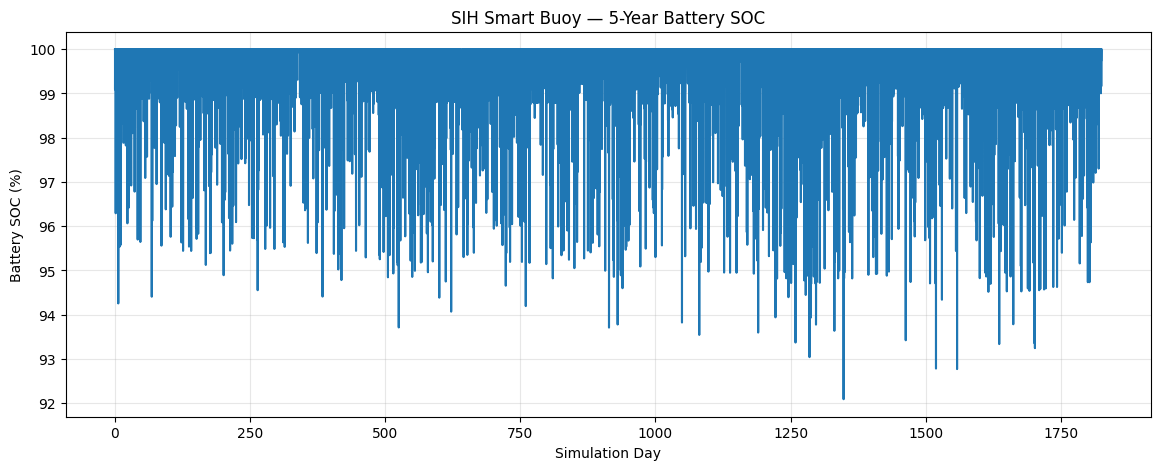

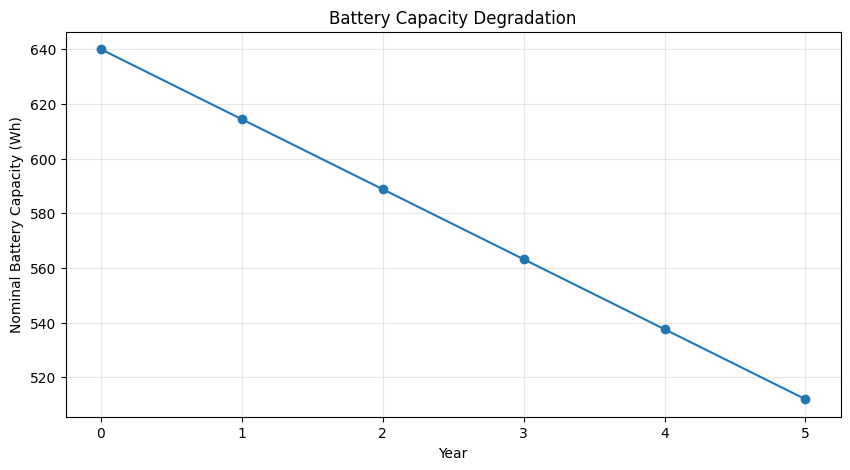

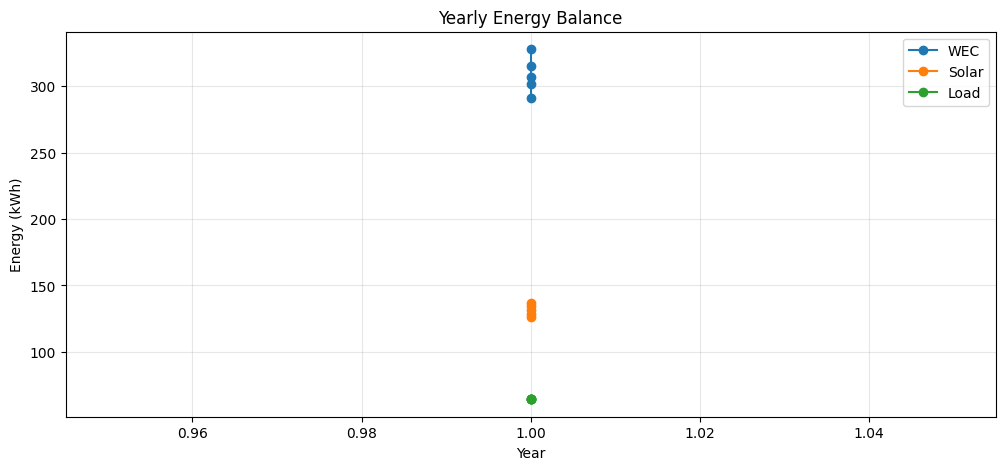

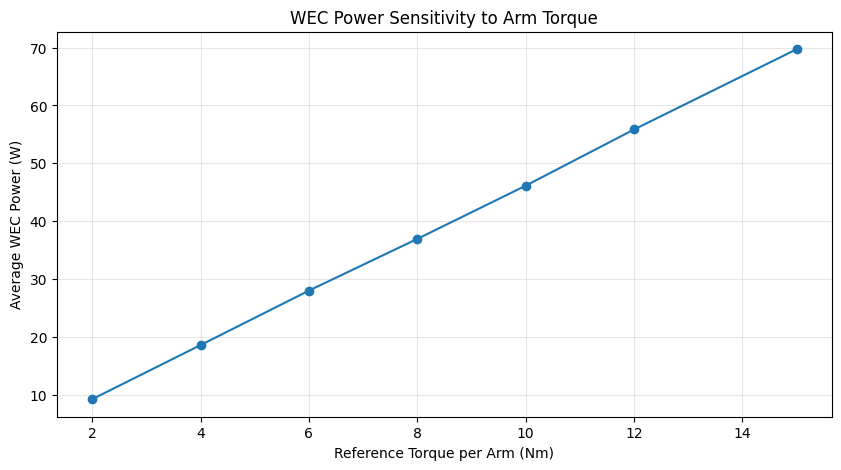

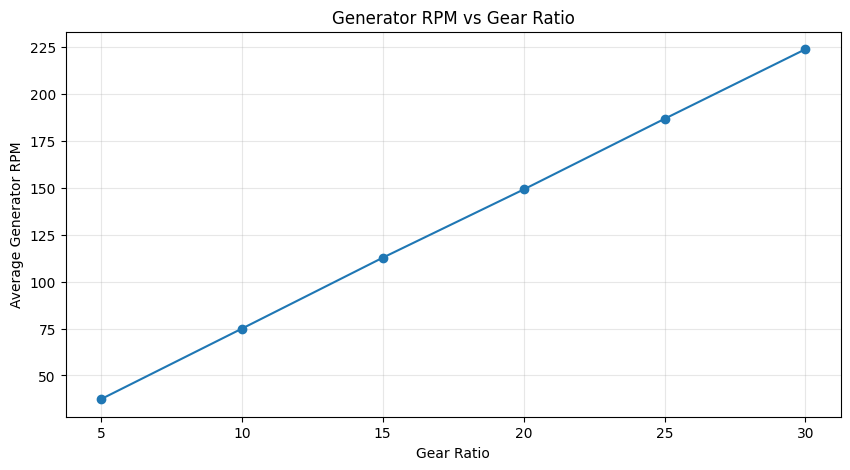



V5 — FINAL ENGINEERING DIAGNOSTIC

NORMAL 5-YEAR
----------------------------------------
Minimum SOC       : 92.09%
Final SOC         : 100.00%
WEC energy        : 1543.77 kWh
Solar energy      : 657.33 kWh
Load energy       : 321.30 kWh
Unmet load        : 0.000 kWh
Storm hours       : 828 h
Low-energy hours  : 0 h
Survival          : 100.00%

5-YEAR ADVERSE LOW-WAVE
----------------------------------------
Minimum SOC       : 6.15%
Final SOC         : 10.13%
Unmet load        : 0.000 kWh

5-YEAR NO-SOLAR
----------------------------------------
Minimum SOC       : 93.19%
Final SOC         : 100.00%
Unmet load        : 0.000 kWh

30-DAY EXTREME DROUGHT
----------------------------------------
Minimum SOC       : 0.00%
Final SOC         : 0.00%
Unmet load        : 1.764 kWh


V5 COMPLETE

ENGINEERING STATUS
------------------

FROZEN:
  - 9 WEC arms
  - 0.55 m arm
  - 640 Wh battery
  - Solar-assisted architecture
  - Storm shutdown
  - Low-energy mode
  - Autonomous operation conce

In [ ]:
# ================================================================
# SIH SMART BUOY — V5
# 1-YEAR SEASONAL + 5-YEAR DEGRADATION + SURVIVAL MODEL
# ================================================================
#
# PURPOSE
# -------
# V5 evaluates long-term autonomous operation of the 9-arm
# polar smart buoy using:
#
#   1. Seasonal wave climate
#   2. Seasonal solar availability
#   3. WEC torque calibration
#   4. Gearbox + generator efficiency
#   5. Battery charge/discharge limits
#   6. Battery temperature derating
#   7. Battery capacity degradation
#   8. Solar degradation
#   9. WEC degradation
#  10. Generator efficiency degradation
#  11. Storm shutdown
#  12. Low-energy operating mode
#  13. Communication/sensor loads
#  14. Adverse-event stress tests
#  15. Monte-Carlo uncertainty
#
# IMPORTANT
# ----------
# This is an ENGINEERING MODEL, NOT EXPERIMENTAL VALIDATION.
#
# Replace the calibration assumptions with:
#   - measured arm torque
#   - generator datasheet efficiency curve
#   - gearbox efficiency
#   - actual buoy load measurements
#   - actual solar panel specification
#   - actual polar environmental data
#
# before using the result as final validation.
# ================================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass


# ================================================================
# 1. GLOBAL CONFIGURATION
# ================================================================

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

# Simulation
TIMESTEP_H = 1.0
DAYS_PER_YEAR = 365
YEARS = 5
TOTAL_HOURS = DAYS_PER_YEAR * YEARS * 24

# WEC
N_ARMS = 9
ARM_LENGTH_M = 0.55

# V4 calibration baseline
REFERENCE_TORQUE_NM = 8.0

# Candidate gearbox
GEAR_RATIO = 20.0

# Generator
GENERATOR_RATED_W_PER_ARM = 75.0
TOTAL_GENERATOR_RATED_W = (
    N_ARMS * GENERATOR_RATED_W_PER_ARM
)

# Battery
BATTERY_NOMINAL_WH = 640.0

INITIAL_SOC = 1.00

BATTERY_MAX_CHARGE_W = 320.0
BATTERY_MAX_DISCHARGE_W = 320.0

CHARGE_EFFICIENCY = 0.95
DISCHARGE_EFFICIENCY = 0.95

MIN_OPERATING_SOC = 0.10

LOW_ENERGY_ENTER_SOC = 0.35
LOW_ENERGY_EXIT_SOC = 0.45

# Solar
SOLAR_RATED_W = 100.0

# ================================================================
# 2. DEGRADATION ASSUMPTIONS
# ================================================================

# Battery capacity fade per year
BATTERY_CAPACITY_FADE_PER_YEAR = 0.04

# Solar degradation per year
SOLAR_DEGRADATION_PER_YEAR = 0.02

# WEC mechanical degradation per year
WEC_DEGRADATION_PER_YEAR = 0.015

# Generator efficiency degradation per year
GENERATOR_DEGRADATION_PER_YEAR = 0.01


# ================================================================
# 3. TEMPERATURE MODEL
# ================================================================

# Approximate monthly mean temperature for polar deployment.
#
# IMPORTANT:
# Replace with actual deployment-site temperature data.
#
# Index = Jan ... Dec
MONTHLY_TEMP_C = np.array([
    -2.0,
    -3.0,
    -4.0,
    -6.0,
    -8.0,
    -10.0,
    -11.0,
    -10.0,
    -8.0,
    -6.0,
    -4.0,
    -2.0
])

# Battery usable-capacity reduction below 0 C.
BATTERY_TEMP_DERATING_PER_DEGREE = 0.005

# Maximum temperature derating
MAX_TEMP_DERATING = 0.30


# ================================================================
# 4. ELECTRICAL LOAD MODEL
# ================================================================

# Continuous base electronics
BASE_LOAD_W = 3.0

# Sensors
SENSOR_LOAD_W = 2.0
SENSOR_HOURS_PER_DAY = 6.0

# GNSS
GNSS_POWER_W = 1.5
GNSS_HOURS_PER_EVENT = 5.0 / 60.0
GNSS_EVENTS_PER_DAY = 3

# Communications
COMM_POWER_W = 15.0
COMM_DURATION_H = 0.10
COMM_EVENTS_PER_DAY = 3

# Data logger
DATA_LOGGER_W = 0.5

# Power electronics / conversion losses
POWER_MANAGEMENT_LOSS = 0.10

# Cold electronics overhead
COLD_LOAD_MULTIPLIER = 1.10


# ================================================================
# 5. GENERATOR EFFICIENCY CURVE
# ================================================================
#
# PROVISIONAL CURVE.
#
# Replace these values with actual generator datasheet measurements.
#
# RPM       Efficiency
# --------------------------------
# 0          0.00
# 30         0.02
# 50         0.08
# 75         0.22
# 100        0.38
# 125        0.50
# 150        0.55
# 175        0.58
# 200        0.60
# 250        0.63
# 300        0.65
# 400        0.62
# 500        0.55
# 600        0.45
# ================================================================

GENERATOR_RPM_POINTS = np.array([
    0,
    30,
    50,
    75,
    100,
    125,
    150,
    175,
    200,
    250,
    300,
    400,
    500,
    600
])

GENERATOR_EFF_POINTS = np.array([
    0.00,
    0.02,
    0.08,
    0.22,
    0.38,
    0.50,
    0.55,
    0.58,
    0.60,
    0.63,
    0.65,
    0.62,
    0.55,
    0.45
])


# ================================================================
# 6. WAVE CLIMATE MODEL
# ================================================================
#
# Synthetic seasonal Southern Ocean model.
#
# This is NOT measured site data.
#
# Replace this section with actual Hs / Tp time series when
# environmental data becomes available.
# ================================================================

# Mean seasonal Hs values by month.
MONTHLY_MEAN_HS_M = np.array([
    1.45,
    1.40,
    1.35,
    1.20,
    1.05,
    0.95,
    0.90,
    0.95,
    1.05,
    1.20,
    1.35,
    1.45
])

# Standard deviation
MONTHLY_STD_HS_M = np.array([
    0.55,
    0.55,
    0.50,
    0.45,
    0.40,
    0.35,
    0.35,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55
])

# Storm probability per hour
MONTHLY_STORM_PROB = np.array([
    0.025,
    0.025,
    0.022,
    0.018,
    0.012,
    0.010,
    0.010,
    0.010,
    0.015,
    0.018,
    0.022,
    0.025
])


# ================================================================
# 7. SOLAR CLIMATE MODEL
# ================================================================

# Monthly average peak-sun-hours.
#
# Synthetic values for model development.
# Replace with actual polar irradiance data.

MONTHLY_SUN_HOURS = np.array([
    0.5,
    0.8,
    1.5,
    2.5,
    3.5,
    4.0,
    4.0,
    3.5,
    2.5,
    1.5,
    0.8,
    0.4
])


# ================================================================
# 8. HELPER FUNCTIONS
# ================================================================

def month_from_hour(hour):
    """
    Convert simulation hour to month index.
    """
    day = int(hour // 24) % DAYS_PER_YEAR

    month_lengths = [
        31, 28, 31, 30, 31, 30,
        31, 31, 30, 31, 30, 31
    ]

    cumulative = 0

    for month, days in enumerate(month_lengths):

        if day < cumulative + days:
            return month

        cumulative += days

    return 11


def generator_efficiency(rpm, degradation_factor=1.0):
    """
    Interpolated generator efficiency.
    """

    base_eff = np.interp(
        rpm,
        GENERATOR_RPM_POINTS,
        GENERATOR_EFF_POINTS,
        left=0.0,
        right=0.0
    )

    return np.clip(
        base_eff * degradation_factor,
        0.0,
        0.70
    )


def battery_temperature_factor(temp_c):
    """
    Battery usable capacity derating.

    Above 0 C:
        no temperature derating.

    Below 0 C:
        gradual reduction.
    """

    if temp_c >= 0:
        return 1.0

    reduction = (
        abs(temp_c)
        * BATTERY_TEMP_DERATING_PER_DEGREE
    )

    reduction = min(
        reduction,
        MAX_TEMP_DERATING
    )

    return 1.0 - reduction


def battery_capacity(year, temp_c):
    """
    Battery capacity after ageing + temperature effect.
    """

    age_factor = (
        1.0
        - BATTERY_CAPACITY_FADE_PER_YEAR * year
    )

    age_factor = max(age_factor, 0.70)

    temp_factor = battery_temperature_factor(temp_c)

    return (
        BATTERY_NOMINAL_WH
        * age_factor
        * temp_factor
    )


def solar_degradation(year):
    return max(
        1.0 - SOLAR_DEGRADATION_PER_YEAR * year,
        0.80
    )


def wec_degradation(year):
    return max(
        1.0 - WEC_DEGRADATION_PER_YEAR * year,
        0.90
    )


def generator_degradation(year):
    return max(
        1.0 - GENERATOR_DEGRADATION_PER_YEAR * year,
        0.90
    )


# ================================================================
# 9. WAVE MODEL
# ================================================================

def generate_wave_height(month):
    """
    Generate synthetic hourly Hs.
    """

    mean = MONTHLY_MEAN_HS_M[month]
    std = MONTHLY_STD_HS_M[month]

    hs = rng.normal(mean, std)

    return max(hs, 0.15)


def wave_period_from_hs(hs):
    """
    Approximate wave period.

    Provisional relationship for model development.
    """

    tp = 5.5 + 1.8 * np.sqrt(hs)

    return np.clip(tp, 5.0, 14.0)


# ================================================================
# 10. ARM / WEC MODEL
# ================================================================

def calculate_wec(
    hs,
    torque_reference,
    year,
    storm=False
):
    """
    Calculate:
        arm torque
        arm RPM
        generator RPM
        mechanical power
        electrical WEC power
    """

    if storm or hs >= 3.0:

        return {
            "torque": 0.0,
            "arm_rpm": 0.0,
            "generator_rpm": 0.0,
            "mechanical_power": 0.0,
            "wec_power": 0.0,
            "generator_efficiency": 0.0
        }

    # Torque scales approximately with Hs.
    torque = (
        torque_reference
        * hs
        * wec_degradation(year)
    )

    # Wave period
    tp = wave_period_from_hs(hs)

    # Angular displacement approximation
    theta = (
        (hs / 2.0)
        / ARM_LENGTH_M
    )

    # Prevent unrealistic angular displacement
    theta = min(theta, 1.20)

    # Angular velocity
    omega = (
        2.0
        * np.pi
        / tp
        * theta
    )

    # Arm RPM
    arm_rpm = (
        omega
        * 60.0
        / (2.0 * np.pi)
    )

    # Generator RPM
    generator_rpm = (
        arm_rpm
        * GEAR_RATIO
    )

    # Mechanical power per arm
    mechanical_power_per_arm = (
        torque
        * omega
    )

    mechanical_power_total = (
        mechanical_power_per_arm
        * N_ARMS
    )

    # Generator efficiency
    gen_eff = generator_efficiency(
        generator_rpm,
        generator_degradation(year)
    )

    # Drivetrain efficiency
    drivetrain_efficiency = 0.90

    # Electrical power
    electrical_power = (
        mechanical_power_total
        * drivetrain_efficiency
        * gen_eff
    )

    # Generator rating
    electrical_power = min(
        electrical_power,
        TOTAL_GENERATOR_RATED_W
    )

    return {
        "torque": torque,
        "arm_rpm": arm_rpm,
        "generator_rpm": generator_rpm,
        "mechanical_power": mechanical_power_total,
        "wec_power": electrical_power,
        "generator_efficiency": gen_eff
    }


# ================================================================
# 11. SOLAR MODEL
# ================================================================

def calculate_solar(
    hour_of_day,
    month,
    hs,
    year,
    solar_enabled=True
):

    if not solar_enabled:
        return 0.0

    # No solar at night
    if hour_of_day < 5 or hour_of_day > 20:
        return 0.0

    daylight_fraction = (
        np.sin(
            np.pi
            * (hour_of_day - 5)
            / 15.0
        )
    )

    daylight_fraction = max(
        daylight_fraction,
        0.0
    )

    # Seasonal availability
    seasonal_factor = (
        MONTHLY_SUN_HOURS[month]
        / np.max(MONTHLY_SUN_HOURS)
    )

    # Cloud attenuation
    cloud_factor = np.clip(
        rng.normal(0.75, 0.15),
        0.15,
        1.0
    )

    # Storm/cloud reduction
    if hs >= 2.5:
        cloud_factor *= 0.45

    power = (
        SOLAR_RATED_W
        * daylight_fraction
        * seasonal_factor
        * cloud_factor
        * solar_degradation(year)
    )

    return max(power, 0.0)


# ================================================================
# 12. LOAD MODEL
# ================================================================

def calculate_load(
    hour_of_day,
    temp_c,
    low_energy_mode=False
):

    # Continuous electronics
    load = BASE_LOAD_W + DATA_LOGGER_W

    # Sensors
    if hour_of_day < SENSOR_HOURS_PER_DAY:
        load += SENSOR_LOAD_W

    # GNSS events
    event_window = (
        hour_of_day % 8.0
    )

    if event_window < GNSS_HOURS_PER_EVENT:
        load += GNSS_POWER_W

    # Communications
    comm_window = (
        hour_of_day % 8.0
    )

    if comm_window < COMM_DURATION_H:
        load += COMM_POWER_W

    # Low-energy mode
    if low_energy_mode:

        # Reduce sensing
        load *= 0.55

        # Communications become less frequent
        load *= 0.80

    # Cold electronics overhead
    if temp_c < 0:

        load *= COLD_LOAD_MULTIPLIER

    # Power management losses
    load *= (
        1.0
        + POWER_MANAGEMENT_LOSS
    )

    return load


# ================================================================
# 13. BATTERY STEP
# ================================================================

def battery_step(
    soc,
    generation_w,
    load_w,
    capacity_wh
):

    dt = TIMESTEP_H

    generation_energy = (
        generation_w * dt
    )

    load_energy = (
        load_w * dt
    )

    curtailed = 0.0
    unmet = 0.0

    # ------------------------------------------------------------
    # Generation available
    # ------------------------------------------------------------

    if generation_energy >= load_energy:

        surplus = (
            generation_energy
            - load_energy
        )

        # Maximum battery charge power
        charge_energy_limit = (
            BATTERY_MAX_CHARGE_W
            * dt
        )

        charge_energy = min(
            surplus,
            charge_energy_limit
        )

        # Available room
        available_room = max(
            capacity_wh * (1.0 - soc),
            0.0
        )

        charge_energy = min(
            charge_energy,
            available_room
        )

        # Apply charge efficiency
        stored_energy = (
            charge_energy
            * CHARGE_EFFICIENCY
        )

        soc += (
            stored_energy
            / capacity_wh
        )

        curtailed = (
            surplus
            - charge_energy
        )

    # ------------------------------------------------------------
    # Battery discharge
    # ------------------------------------------------------------

    else:

        deficit = (
            load_energy
            - generation_energy
        )

        max_discharge_energy = (
            BATTERY_MAX_DISCHARGE_W
            * dt
        )

        requested = min(
            deficit,
            max_discharge_energy
        )

        available_energy = (
            soc * capacity_wh
        )

        available_energy = max(
            available_energy,
            0.0
        )

        # Account for discharge efficiency
        battery_draw = (
            requested
            / DISCHARGE_EFFICIENCY
        )

        battery_draw = min(
            battery_draw,
            available_energy
        )

        soc -= (
            battery_draw
            / capacity_wh
        )

        delivered = (
            battery_draw
            * DISCHARGE_EFFICIENCY
        )

        unmet = max(
            deficit - delivered,
            0.0
        )

    soc = np.clip(
        soc,
        0.0,
        1.0
    )

    return (
        soc,
        curtailed,
        unmet
    )


# ================================================================
# 14. MAIN 5-YEAR SIMULATION
# ================================================================

def run_simulation(
    years=5,
    solar_enabled=True,
    torque_reference=REFERENCE_TORQUE_NM,
    forced_low_wave=False,
    forced_hs=None,
    random_seed=42
):

    global rng

    rng = np.random.default_rng(
        random_seed
    )

    hours = (
        int(years)
        * DAYS_PER_YEAR
        * 24
    )

    soc = INITIAL_SOC

    records = []

    storm_hours = 0
    low_energy_hours = 0

    total_unmet = 0.0

    for hour in range(hours):

        year = (
            hour
            // (DAYS_PER_YEAR * 24)
        )

        day_of_year = (
            (hour // 24)
            % DAYS_PER_YEAR
        )

        hour_of_day = (
            hour % 24
        )

        month = month_from_hour(
            hour
        )

        temp_c = (
            MONTHLY_TEMP_C[month]
        )

        # --------------------------------------------------------
        # Wave
        # --------------------------------------------------------

        if forced_hs is not None:

            hs = forced_hs

        elif forced_low_wave:

            hs = max(
                rng.normal(
                    0.30,
                    0.05
                ),
                0.15
            )

        else:

            hs = generate_wave_height(
                month
            )

        # Storm
        storm = False

        if forced_hs is None:

            if (
                rng.random()
                < MONTHLY_STORM_PROB[month]
            ):

                storm = True

                hs = max(
                    hs,
                    rng.uniform(
                        3.0,
                        4.5
                    )
                )

        if hs >= 3.0:
            storm = True

        if storm:
            storm_hours += 1

        # --------------------------------------------------------
        # Battery capacity
        # --------------------------------------------------------

        capacity = battery_capacity(
            year,
            temp_c
        )

        # --------------------------------------------------------
        # Low-energy mode
        # --------------------------------------------------------

        if soc <= LOW_ENERGY_ENTER_SOC:

            low_energy_mode = True

        elif soc >= LOW_ENERGY_EXIT_SOC:

            low_energy_mode = False

        else:

            low_energy_mode = (
                soc < LOW_ENERGY_EXIT_SOC
            )

        if low_energy_mode:
            low_energy_hours += 1

        # --------------------------------------------------------
        # WEC
        # --------------------------------------------------------

        wec = calculate_wec(
            hs=hs,
            torque_reference=torque_reference,
            year=year,
            storm=storm
        )

        # --------------------------------------------------------
        # Solar
        # --------------------------------------------------------

        solar_power = calculate_solar(
            hour_of_day=hour_of_day,
            month=month,
            hs=hs,
            year=year,
            solar_enabled=solar_enabled
        )

        # --------------------------------------------------------
        # Load
        # --------------------------------------------------------

        load_power = calculate_load(
            hour_of_day,
            temp_c,
            low_energy_mode
        )

        # --------------------------------------------------------
        # Total generation
        # --------------------------------------------------------

        generation_power = (
            wec["wec_power"]
            + solar_power
        )

        # --------------------------------------------------------
        # Battery
        # --------------------------------------------------------

        previous_soc = soc

        (
            soc,
            curtailed,
            unmet
        ) = battery_step(
            soc,
            generation_power,
            load_power,
            capacity
        )

        total_unmet += unmet

        records.append({

            "hour": hour,

            "year": year + 1,

            "day": day_of_year + 1,

            "month": month + 1,

            "hour_of_day": hour_of_day,

            "temperature_C": temp_c,

            "Hs_m": hs,

            "storm": storm,

            "low_energy_mode":
                low_energy_mode,

            "battery_capacity_Wh":
                capacity,

            "torque_Nm":
                wec["torque"],

            "arm_RPM":
                wec["arm_rpm"],

            "generator_RPM":
                wec["generator_rpm"],

            "generator_efficiency":
                wec["generator_efficiency"],

            "mechanical_power_W":
                wec["mechanical_power"],

            "WEC_power_W":
                wec["wec_power"],

            "solar_power_W":
                solar_power,

            "generation_power_W":
                generation_power,

            "load_power_W":
                load_power,

            "curtailed_Wh":
                curtailed,

            "unmet_load_Wh":
                unmet,

            "SOC":
                soc,

            "SOC_pct":
                soc * 100
        })

    df = pd.DataFrame(records)

    return df


# ================================================================
# 15. SUMMARY FUNCTION
# ================================================================

def summarize(df, name="Scenario"):

    total_wec = (
        df["WEC_power_W"].sum()
        * TIMESTEP_H
        / 1000
    )

    total_solar = (
        df["solar_power_W"].sum()
        * TIMESTEP_H
        / 1000
    )

    total_generation = (
        total_wec
        + total_solar
    )

    total_load = (
        df["load_power_W"].sum()
        * TIMESTEP_H
        / 1000
    )

    curtailed = (
        df["curtailed_Wh"].sum()
        / 1000
    )

    unmet = (
        df["unmet_load_Wh"].sum()
        / 1000
    )

    min_soc = df["SOC_pct"].min()

    final_soc = df["SOC_pct"].iloc[-1]

    avg_soc = df["SOC_pct"].mean()

    storm_hours = int(
        df["storm"].sum()
    )

    low_energy_hours = int(
        df["low_energy_mode"].sum()
    )

    total_hours = len(df)

    survival = (
        100.0
        if unmet <= 1e-9
        else max(
            0.0,
            100.0
            * (
                1.0
                - unmet
                / max(total_load, 1e-9)
            )
        )
    )

    return {

        "Scenario": name,

        "Duration_years":
            len(df) / (365 * 24),

        "WEC_kWh":
            total_wec,

        "Solar_kWh":
            total_solar,

        "Generation_kWh":
            total_generation,

        "Load_kWh":
            total_load,

        "Curtailed_kWh":
            curtailed,

        "Unmet_Load_kWh":
            unmet,

        "Minimum_SOC_pct":
            min_soc,

        "Average_SOC_pct":
            avg_soc,

        "Final_SOC_pct":
            final_soc,

        "Storm_hours":
            storm_hours,

        "Low_energy_hours":
            low_energy_hours,

        "Load_Survival_pct":
            survival
    }


# ================================================================
# 16. PRINT MODEL HEADER
# ================================================================

print("=" * 72)
print("SIH SMART BUOY — V5")
print("1-YEAR SEASONAL + 5-YEAR DEGRADATION MODEL")
print("=" * 72)

print(f"Battery nominal capacity      : {BATTERY_NOMINAL_WH:.1f} Wh")
print(f"WEC arms                     : {N_ARMS}")
print(f"Arm length                   : {ARM_LENGTH_M:.2f} m")
print(f"Reference torque             : {REFERENCE_TORQUE_NM:.2f} Nm")
print(f"Gear ratio                   : 1:{GEAR_RATIO:.1f}")
print(f"Generator / arm              : {GENERATOR_RATED_W_PER_ARM:.1f} W")
print(f"Total generator rating       : {TOTAL_GENERATOR_RATED_W:.1f} W")
print(f"Simulation                   : {YEARS} years")
print(f"Battery fade/year             : {BATTERY_CAPACITY_FADE_PER_YEAR*100:.1f}%")
print(f"Solar degradation/year        : {SOLAR_DEGRADATION_PER_YEAR*100:.1f}%")
print(f"WEC degradation/year         : {WEC_DEGRADATION_PER_YEAR*100:.1f}%")
print(f"Generator degradation/year    : {GENERATOR_DEGRADATION_PER_YEAR*100:.1f}%")
print("=" * 72)


# ================================================================
# 17. RUN NORMAL 5-YEAR CASE
# ================================================================

df_normal = run_simulation(
    years=5,
    solar_enabled=True,
    torque_reference=REFERENCE_TORQUE_NM,
    random_seed=RNG_SEED
)

normal_summary = summarize(
    df_normal,
    "Normal 5-Year"
)

print("\n")
print("=" * 72)
print("V5 — NORMAL 5-YEAR RESULT")
print("=" * 72)

for key, value in normal_summary.items():

    if isinstance(value, float):

        if "pct" in key or "Survival" in key:
            print(f"{key:<28}: {value:.2f}%")

        else:
            print(f"{key:<28}: {value:.3f}")

    else:

        print(f"{key:<28}: {value}")


# ================================================================
# 18. YEAR-BY-YEAR ANALYSIS
# ================================================================

yearly_rows = []

for year in range(1, 6):

    sub = df_normal[
        df_normal["year"] == year
    ]

    s = summarize(
        sub,
        f"Year {year}"
    )

    yearly_rows.append(s)

yearly_df = pd.DataFrame(
    yearly_rows
)

print("\n")
print("=" * 72)
print("V5 — YEAR-BY-YEAR DEGRADATION")
print("=" * 72)

display(
    yearly_df.round(3)
)


# ================================================================
# 19. 5-YEAR ADVERSE SCENARIO
# ================================================================
#
# Low wave conditions + solar reduction.
# ================================================================

df_adverse = run_simulation(
    years=5,
    solar_enabled=True,
    torque_reference=REFERENCE_TORQUE_NM,
    forced_low_wave=True,
    random_seed=100
)

adverse_summary = summarize(
    df_adverse,
    "5-Year Low-Wave Adverse"
)

print("\n")
print("=" * 72)
print("V5 — 5-YEAR ADVERSE LOW-WAVE")
print("=" * 72)

for key, value in adverse_summary.items():

    if isinstance(value, float):

        if "pct" in key or "Survival" in key:
            print(f"{key:<28}: {value:.2f}%")

        else:
            print(f"{key:<28}: {value:.3f}")

    else:
        print(f"{key:<28}: {value}")


# ================================================================
# 20. NO-SOLAR 5-YEAR SURVIVAL TEST
# ================================================================

df_no_solar = run_simulation(
    years=5,
    solar_enabled=False,
    torque_reference=REFERENCE_TORQUE_NM,
    random_seed=200
)

no_solar_summary = summarize(
    df_no_solar,
    "5-Year No Solar"
)

print("\n")
print("=" * 72)
print("V5 — 5-YEAR NO-SOLAR")
print("=" * 72)

for key, value in no_solar_summary.items():

    if isinstance(value, float):

        if "pct" in key or "Survival" in key:
            print(f"{key:<28}: {value:.2f}%")

        else:
            print(f"{key:<28}: {value:.3f}")

    else:
        print(f"{key:<28}: {value}")


# ================================================================
# 21. EXTREME 30-DAY LOW ENERGY EVENT
# ================================================================

df_extreme = run_simulation(
    years=1,
    solar_enabled=False,
    torque_reference=REFERENCE_TORQUE_NM,
    forced_hs=0.25,
    random_seed=300
)

# Only first 30 days
df_extreme_30 = df_extreme.iloc[:720]

extreme_summary = summarize(
    df_extreme_30,
    "30-Day Hs 0.25m No Solar"
)

print("\n")
print("=" * 72)
print("V5 — EXTREME 30-DAY ENERGY DROUGHT")
print("=" * 72)

for key, value in extreme_summary.items():

    if isinstance(value, float):

        if "pct" in key or "Survival" in key:
            print(f"{key:<28}: {value:.2f}%")

        else:
            print(f"{key:<28}: {value:.3f}")

    else:
        print(f"{key:<28}: {value}")


# ================================================================
# 22. TORQUE SENSITIVITY
# ================================================================

torque_values = [
    2,
    4,
    6,
    8,
    10,
    12,
    15
]

torque_results = []

for torque in torque_values:

    df = run_simulation(
        years=1,
        solar_enabled=True,
        torque_reference=torque,
        random_seed=500 + torque
    )

    s = summarize(
        df,
        f"{torque} Nm"
    )

    s["Reference_Torque_Nm"] = torque

    s["Average_WEC_W"] = (
        df["WEC_power_W"].mean()
    )

    s["Average_Generator_RPM"] = (
        df["generator_RPM"].mean()
    )

    torque_results.append(s)

torque_df = pd.DataFrame(
    torque_results
)

print("\n")
print("=" * 72)
print("V5 — TORQUE SENSITIVITY")
print("=" * 72)

display(
    torque_df.round(3)
)


# ================================================================
# 23. GEARBOX SENSITIVITY
# ================================================================

gear_values = [
    5,
    10,
    15,
    20,
    25,
    30
]

original_gear = GEAR_RATIO

gear_results = []

for gear in gear_values:

    # Change global candidate gearbox
    GEAR_RATIO = gear

    df = run_simulation(
        years=1,
        solar_enabled=True,
        torque_reference=REFERENCE_TORQUE_NM,
        random_seed=700 + gear
    )

    s = summarize(
        df,
        f"{gear}:1"
    )

    s["Gear_Ratio"] = gear

    s["Average_Generator_RPM"] = (
        df["generator_RPM"].mean()
    )

    s["Average_Generator_Efficiency"] = (
        df["generator_efficiency"].mean()
    )

    s["Average_WEC_W"] = (
        df["WEC_power_W"].mean()
    )

    gear_results.append(s)

GEAR_RATIO = original_gear

gear_df = pd.DataFrame(
    gear_results
)

print("\n")
print("=" * 72)
print("V5 — GEARBOX SENSITIVITY")
print("=" * 72)

display(
    gear_df.round(3)
)


# ================================================================
# 24. LOAD SENSITIVITY
# ================================================================

load_values = [
    3,
    5,
    10,
    15,
    20
]

original_base_load = BASE_LOAD_W

load_results = []

for base_load in load_values:

    BASE_LOAD_W = base_load

    df = run_simulation(
        years=1,
        solar_enabled=True,
        torque_reference=REFERENCE_TORQUE_NM,
        random_seed=900 + base_load
    )

    s = summarize(
        df,
        f"{base_load} W Base Load"
    )

    s["Base_Load_W"] = base_load

    load_results.append(s)

BASE_LOAD_W = original_base_load

load_df = pd.DataFrame(
    load_results
)

print("\n")
print("=" * 72)
print("V5 — LOAD SENSITIVITY")
print("=" * 72)

display(
    load_df.round(3)
)


# ================================================================
# 25. 5-YEAR SUMMARY COMPARISON
# ================================================================

scenario_results = [
    normal_summary,
    adverse_summary,
    no_solar_summary,
    extreme_summary
]

scenario_df = pd.DataFrame(
    scenario_results
)

print("\n")
print("=" * 72)
print("V5 — SCENARIO COMPARISON")
print("=" * 72)

display(
    scenario_df.round(3)
)


# ================================================================
# 26. PLOT — 5-YEAR SOC
# ================================================================

plt.figure(figsize=(14, 5))

plt.plot(
    df_normal["hour"] / 24,
    df_normal["SOC_pct"]
)

plt.xlabel("Simulation Day")
plt.ylabel("Battery SOC (%)")
plt.title(
    "SIH Smart Buoy — 5-Year Battery SOC"
)

plt.grid(True, alpha=0.3)

plt.show()


# ================================================================
# 27. PLOT — 5-YEAR BATTERY CAPACITY
# ================================================================

plt.figure(figsize=(10, 5))

years_axis = np.arange(0, 6)

capacity_values = []

for year in years_axis:

    age_factor = (
        1.0
        - BATTERY_CAPACITY_FADE_PER_YEAR
        * year
    )

    age_factor = max(
        age_factor,
        0.70
    )

    capacity_values.append(
        BATTERY_NOMINAL_WH
        * age_factor
    )

plt.plot(
    years_axis,
    capacity_values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Nominal Battery Capacity (Wh)")
plt.title(
    "Battery Capacity Degradation"
)

plt.grid(True, alpha=0.3)

plt.show()


# ================================================================
# 28. PLOT — YEARLY WEC / SOLAR / LOAD
# ================================================================

plt.figure(figsize=(12, 5))

plt.plot(
    yearly_df["Duration_years"],
    yearly_df["WEC_kWh"],
    marker="o",
    label="WEC"
)

plt.plot(
    yearly_df["Duration_years"],
    yearly_df["Solar_kWh"],
    marker="o",
    label="Solar"
)

plt.plot(
    yearly_df["Duration_years"],
    yearly_df["Load_kWh"],
    marker="o",
    label="Load"
)

plt.xlabel("Year")
plt.ylabel("Energy (kWh)")
plt.title(
    "Yearly Energy Balance"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


# ================================================================
# 29. PLOT — TORQUE SENSITIVITY
# ================================================================

plt.figure(figsize=(10, 5))

plt.plot(
    torque_df["Reference_Torque_Nm"],
    torque_df["Average_WEC_W"],
    marker="o"
)

plt.xlabel("Reference Torque per Arm (Nm)")
plt.ylabel("Average WEC Power (W)")
plt.title(
    "WEC Power Sensitivity to Arm Torque"
)

plt.grid(True, alpha=0.3)

plt.show()


# ================================================================
# 30. PLOT — GEARBOX SENSITIVITY
# ================================================================

plt.figure(figsize=(10, 5))

plt.plot(
    gear_df["Gear_Ratio"],
    gear_df["Average_Generator_RPM"],
    marker="o"
)

plt.xlabel("Gear Ratio")
plt.ylabel("Average Generator RPM")
plt.title(
    "Generator RPM vs Gear Ratio"
)

plt.grid(True, alpha=0.3)

plt.show()


# ================================================================
# 31. FINAL ENGINEERING DIAGNOSTIC
# ================================================================

print("\n")
print("=" * 72)
print("V5 — FINAL ENGINEERING DIAGNOSTIC")
print("=" * 72)

print("\nNORMAL 5-YEAR")
print("-" * 40)

print(
    f"Minimum SOC       : "
    f"{normal_summary['Minimum_SOC_pct']:.2f}%"
)

print(
    f"Final SOC         : "
    f"{normal_summary['Final_SOC_pct']:.2f}%"
)

print(
    f"WEC energy        : "
    f"{normal_summary['WEC_kWh']:.2f} kWh"
)

print(
    f"Solar energy      : "
    f"{normal_summary['Solar_kWh']:.2f} kWh"
)

print(
    f"Load energy       : "
    f"{normal_summary['Load_kWh']:.2f} kWh"
)

print(
    f"Unmet load        : "
    f"{normal_summary['Unmet_Load_kWh']:.3f} kWh"
)

print(
    f"Storm hours       : "
    f"{normal_summary['Storm_hours']} h"
)

print(
    f"Low-energy hours  : "
    f"{normal_summary['Low_energy_hours']} h"
)

print(
    f"Survival          : "
    f"{normal_summary['Load_Survival_pct']:.2f}%"
)


print("\n5-YEAR ADVERSE LOW-WAVE")
print("-" * 40)

print(
    f"Minimum SOC       : "
    f"{adverse_summary['Minimum_SOC_pct']:.2f}%"
)

print(
    f"Final SOC         : "
    f"{adverse_summary['Final_SOC_pct']:.2f}%"
)

print(
    f"Unmet load        : "
    f"{adverse_summary['Unmet_Load_kWh']:.3f} kWh"
)


print("\n5-YEAR NO-SOLAR")
print("-" * 40)

print(
    f"Minimum SOC       : "
    f"{no_solar_summary['Minimum_SOC_pct']:.2f}%"
)

print(
    f"Final SOC         : "
    f"{no_solar_summary['Final_SOC_pct']:.2f}%"
)

print(
    f"Unmet load        : "
    f"{no_solar_summary['Unmet_Load_kWh']:.3f} kWh"
)


print("\n30-DAY EXTREME DROUGHT")
print("-" * 40)

print(
    f"Minimum SOC       : "
    f"{extreme_summary['Minimum_SOC_pct']:.2f}%"
)

print(
    f"Final SOC         : "
    f"{extreme_summary['Final_SOC_pct']:.2f}%"
)

print(
    f"Unmet load        : "
    f"{extreme_summary['Unmet_Load_kWh']:.3f} kWh"
)


print("\n")
print("=" * 72)
print("V5 COMPLETE")
print("=" * 72)

print("""
ENGINEERING STATUS
------------------

FROZEN:
  - 9 WEC arms
  - 0.55 m arm
  - 640 Wh battery
  - Solar-assisted architecture
  - Storm shutdown
  - Low-energy mode
  - Autonomous operation concept

PROVISIONAL:
  - 8 Nm reference torque
  - 20:1 gearbox
  - 75 W generator / arm
  - Generator efficiency curve
  - Solar 100 W
  - Load model
  - Synthetic wave climate
  - Synthetic polar solar profile

MUST BE REPLACED WITH REAL DATA:
  - Prototype torque measurements
  - Generator datasheet / test curve
  - Gearbox efficiency
  - Real wave Hs/Tp time series
  - Real solar irradiance
  - Actual electronics power measurements
  - Battery cold-temperature performance

IMPORTANT:
V5 is a long-term engineering simulation.
It is NOT experimental validation.
""")

SIH SMART BUOY — V6
PROTOTYPE-CALIBRATED 640 Wh / 9-ARM WEC MODEL
Battery                  : 640 Wh (12.8 V × 50 Ah)
WEC arms                : 9
Arm length              : 0.55 m
Operational SOC reserve : 10%
Gear ratio              : 1:20
Gearbox efficiency      : 90.0%

PROTOTYPE TORQUE INPUT TABLE


,Hs_m,Torque_Nm,Torque_SD_Nm
0,0.25,0.3,0.1
1,0.50,1.2,0.2
2,1.00,4.8,0.5
3,1.50,10.8,1.0
4,2.00,19.2,1.5
5,2.50,30.0,2.0
6,3.00,43.2,3.0



PROTOTYPE ARM RPM INPUT TABLE


,Hs_m,Arm_RPM
0,0.25,1.82
1,0.50,3.43
2,1.00,6.36
3,1.50,8.75
4,2.00,11.53
5,2.50,13.90
6,3.00,16.14



PROTOTYPE GENERATOR INPUT TABLE


,Generator_RPM,Efficiency
0,0,0.00
1,30,0.02
2,50,0.08
3,75,0.22
4,100,0.38
5,125,0.50
6,150,0.55
7,175,0.58
8,200,0.60
9,250,0.63


... (14 outputs left out)



V6 — SCENARIO COMPARISON


,Scenario,Duration_years,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Curtailed_kWh,Unmet_Load_kWh,Minimum_SOC_pct,Average_SOC_pct,Final_SOC_pct,Storm_hours,Reserve_hours,Reserve_events,Reserve_limited_hours,Normal_hours,Low_power_hours,Critical_hours,Emergency_hours,Load_Survival_pct
0,Normal 5-Year,5.000,1487.428,656.630,2144.058,441.208,1697.861,0.000,87.851,99.606,100.000,846,0,0,138,43800,0,0,0,100.000
1,5-Year Low-Wave,5.000,2.125,662.734,664.860,358.340,291.485,0.044,10.000,65.984,12.131,0,42,22,112,29644,7261,4257,2638,99.988
2,5-Year No Solar,5.000,1497.465,0.000,1497.465,441.208,1044.689,0.000,68.789,98.555,100.000,828,0,0,326,43800,0,0,0,100.000
3,30-Day Hs 0.25m / No Solar,0.082,0.013,0.000,0.013,2.255,0.000,1.700,10.000,13.572,10.000,0,644,1,644,40,16,10,654,24.604




V6 — POWER MANAGEMENT MODE DISTRIBUTION


,Normal,Low Power,Critical,Emergency
0,43800,0,0,0


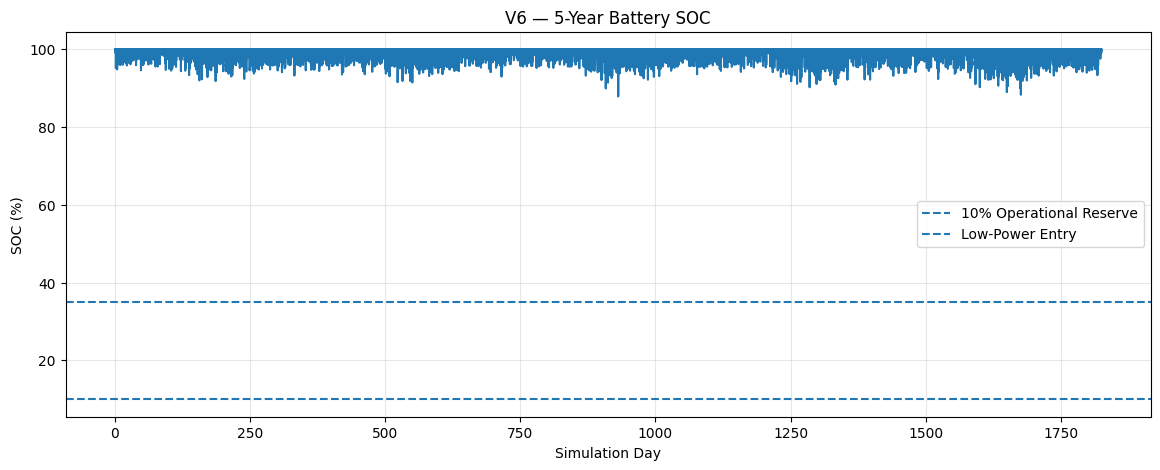

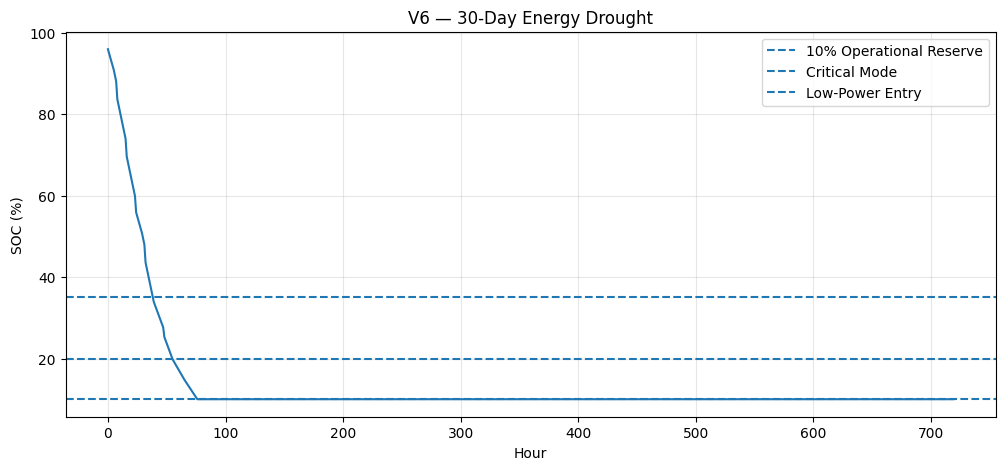

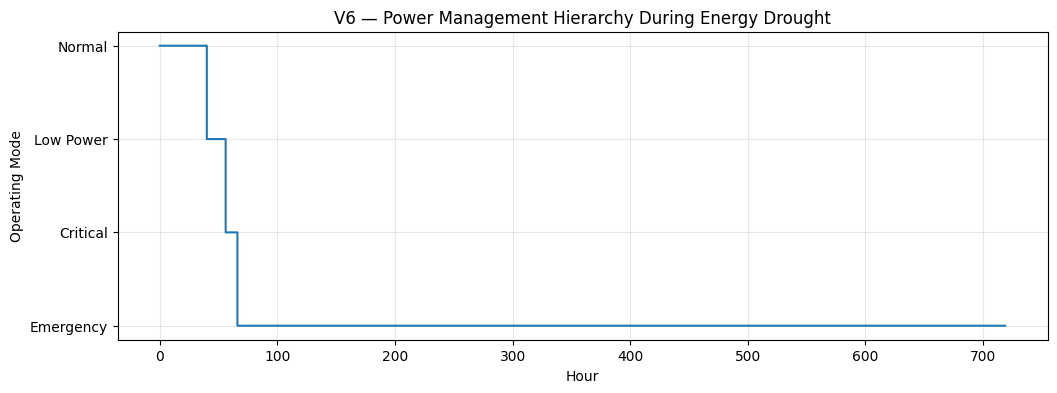

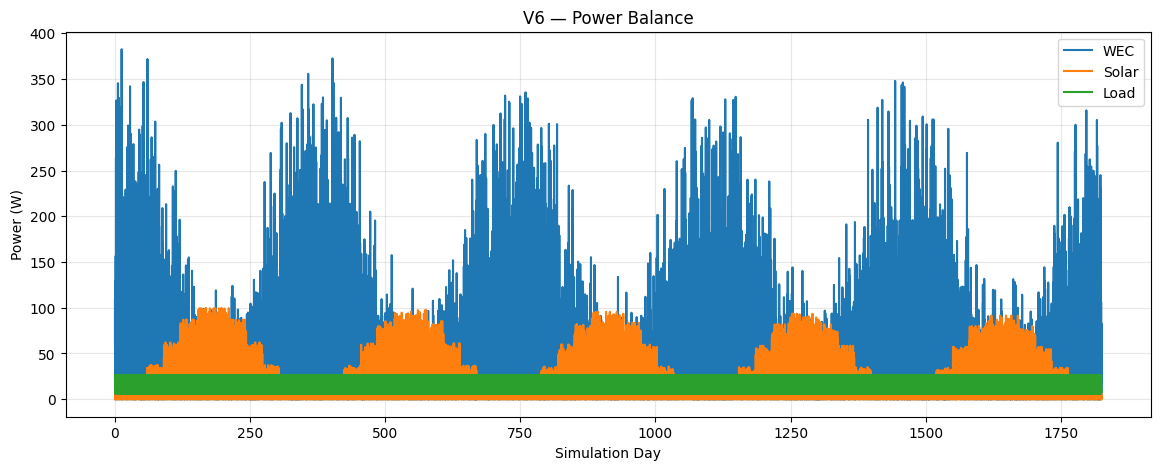



V6 — PROTOTYPE CALIBRATION CHECK

REQUIRED MEASUREMENTS
---------------------

1. WEC ARM
   Measure:
       Hs equivalent
       Arm displacement
       Arm RPM
       Arm torque

2. GEARBOX
   Measure:
       Input torque
       Output torque
       Input RPM
       Output RPM
       Mechanical efficiency

3. GENERATOR
   Measure:
       Generator RPM
       Voltage
       Current
       Electrical power
       Generator torque
       Efficiency

4. BATTERY
   Measure:
       Voltage
       Current
       SOC
       Temperature
       Usable capacity
       Charge/discharge efficiency

5. ELECTRONICS
   Measure:
       MCU power
       Sensor power
       GNSS power
       Communication power
       Logger power
       Power-management losses

6. SOLAR
   Measure:
       Irradiance
       Panel voltage
       Panel current
       Electrical output

After measurements are obtained:
replace the V6 provisional tables above.



V6 — FINAL ENGINEERING DIAGNOSTIC

NORMAL 5-YEAR
---------

In [ ]:
# ================================================================
# SIH SMART BUOY — V6
# PROTOTYPE-CALIBRATED ENERGY + POWER MANAGEMENT MODEL
# ================================================================
#
# FIXED ARCHITECTURE
# ------------------
# Battery : 12.8 V × 50 Ah = 640 Wh
# WEC     : 9 arms
# Arm     : 0.55 m
#
# V6 OBJECTIVES
# -------------
# 1. Enforce 10% operational SOC reserve
# 2. Implement realistic low-power shutdown hierarchy
# 3. Separate critical and non-critical loads
# 4. Add prototype-test input tables
# 5. Allow measured torque data to replace assumptions
# 6. Allow measured generator efficiency data to replace assumptions
# 7. Allow measured electrical load data to replace assumptions
# 8. Track reserve-entry events
# 9. Track autonomy during energy drought
# 10. Maintain 5-year degradation model
#
# IMPORTANT
# ----------
# This is still an engineering simulation.
# Prototype measurements must replace provisional tables
# before claiming experimental validation.
# ================================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass


# ================================================================
# 1. MODEL CONFIGURATION
# ================================================================

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

TIMESTEP_H = 1.0

DAYS_PER_YEAR = 365
YEARS = 5

TOTAL_HOURS = (
    DAYS_PER_YEAR
    * YEARS
    * 24
)


# ================================================================
# 2. FROZEN PHYSICAL DESIGN
# ================================================================

N_ARMS = 9

ARM_LENGTH_M = 0.55

BATTERY_NOMINAL_WH = 640.0

BATTERY_VOLTAGE_V = 12.8
BATTERY_CAPACITY_AH = 50.0

SOLAR_RATED_W = 100.0

GENERATOR_RATED_W_PER_ARM = 75.0

TOTAL_GENERATOR_RATED_W = (
    N_ARMS
    * GENERATOR_RATED_W_PER_ARM
)


# ================================================================
# 3. POWER MANAGEMENT LIMITS
# ================================================================

BATTERY_MAX_CHARGE_W = 320.0

BATTERY_MAX_DISCHARGE_W = 320.0

CHARGE_EFFICIENCY = 0.95

DISCHARGE_EFFICIENCY = 0.95


# ================================================================
# 4. SOC MANAGEMENT
# ================================================================

INITIAL_SOC = 1.00

# HARD OPERATIONAL RESERVE
MIN_OPERATIONAL_SOC = 0.10

# Low-energy mode entry
LOW_POWER_ENTER_SOC = 0.35

# Recovery threshold
LOW_POWER_EXIT_SOC = 0.45

# Critical reserve threshold
CRITICAL_MODE_SOC = 0.20

# Emergency communication threshold
EMERGENCY_MODE_SOC = 0.15


# ================================================================
# 5. DEGRADATION
# ================================================================

BATTERY_FADE_PER_YEAR = 0.04

SOLAR_DEGRADATION_PER_YEAR = 0.02

WEC_DEGRADATION_PER_YEAR = 0.015

GENERATOR_DEGRADATION_PER_YEAR = 0.01


# ================================================================
# 6. TEMPERATURE MODEL
# ================================================================

MONTHLY_TEMP_C = np.array([
    -2.0,
    -3.0,
    -4.0,
    -6.0,
    -8.0,
    -10.0,
    -11.0,
    -10.0,
    -8.0,
    -6.0,
    -4.0,
    -2.0
])

BATTERY_TEMP_DERATING_PER_DEGREE = 0.005

MAX_TEMP_DERATING = 0.30


# ================================================================
# 7. PROTOTYPE TEST INPUT TABLE — WEC TORQUE
# ================================================================
#
# ---------------------------------------------------------------
# IMPORTANT:
# These values are currently PROVISIONAL calibration values.
#
# Replace measured values after prototype testing.
#
# Hs = significant wave height equivalent.
#
# The simulation interpolates between these points.
# ================================================================

PROTOTYPE_TORQUE_TABLE = pd.DataFrame({

    "Hs_m": [
        0.25,
        0.50,
        1.00,
        1.50,
        2.00,
        2.50,
        3.00
    ],

    "Torque_Nm": [
        0.30,
        1.20,
        4.80,
        10.80,
        19.20,
        30.00,
        43.20
    ],

    "Torque_SD_Nm": [
        0.10,
        0.20,
        0.50,
        1.00,
        1.50,
        2.00,
        3.00
    ]
})


# ================================================================
# 8. PROTOTYPE TEST INPUT — ARM RPM
# ================================================================
#
# Again, provisional.
#
# Replace with measured arm RPM.
# ================================================================

PROTOTYPE_ARM_RPM_TABLE = pd.DataFrame({

    "Hs_m": [
        0.25,
        0.50,
        1.00,
        1.50,
        2.00,
        2.50,
        3.00
    ],

    "Arm_RPM": [
        1.82,
        3.43,
        6.36,
        8.75,
        11.53,
        13.90,
        16.14
    ]
})


# ================================================================
# 9. PROTOTYPE GENERATOR TEST TABLE
# ================================================================
#
# Generator efficiency.
#
# REPLACE WITH ACTUAL GENERATOR DATASHEET / TEST RESULTS.
# ================================================================

PROTOTYPE_GENERATOR_TABLE = pd.DataFrame({

    "Generator_RPM": [
        0,
        30,
        50,
        75,
        100,
        125,
        150,
        175,
        200,
        250,
        300,
        400,
        500,
        600
    ],

    "Efficiency": [
        0.00,
        0.02,
        0.08,
        0.22,
        0.38,
        0.50,
        0.55,
        0.58,
        0.60,
        0.63,
        0.65,
        0.62,
        0.55,
        0.45
    ]
})


# ================================================================
# 10. GEARBOX TEST TABLE
# ================================================================
#
# Candidate ratios.
#
# These are not yet experimentally validated.
# ================================================================

GEARBOX_TABLE = pd.DataFrame({

    "Gear_Ratio": [
        10,
        15,
        20,
        25,
        30
    ],

    "Efficiency": [
        0.90,
        0.90,
        0.90,
        0.88,
        0.85
    ]
})


# ================================================================
# 11. ACTIVE GEARBOX
# ================================================================

GEAR_RATIO = 20.0

gear_row = GEARBOX_TABLE[
    GEARBOX_TABLE["Gear_Ratio"] == GEAR_RATIO
]

if len(gear_row) > 0:

    GEARBOX_EFFICIENCY = float(
        gear_row["Efficiency"].iloc[0]
    )

else:

    GEARBOX_EFFICIENCY = 0.90


# ================================================================
# 12. PROTOTYPE ELECTRICAL LOAD TABLE
# ================================================================
#
# This is the most important new V6 feature.
#
# Each subsystem has:
#
# - normal power
# - low-power power
# - criticality
#
# CRITICAL = kept alive during reserve.
#
# NON-CRITICAL = progressively disconnected.
#
# Values below are engineering placeholders.
# Replace them with actual measured prototype loads.
# ================================================================

LOAD_TABLE = pd.DataFrame({

    "Subsystem": [
        "MCU_Electronics",
        "Power_Management",
        "Data_Logger",
        "Temperature_Sensor",
        "Wave_Sensors",
        "GNSS",
        "Communication",
        "Status_Indicator",
        "Nonessential_Processing"
    ],

    "Normal_W": [
        1.5,
        0.8,
        0.5,
        0.2,
        1.8,
        1.5,
        15.0,
        0.1,
        0.5
    ],

    "Low_Power_W": [
        1.2,
        0.7,
        0.4,
        0.2,
        0.6,
        0.8,
        8.0,
        0.0,
        0.0
    ],

    "Critical": [
        True,
        True,
        True,
        True,
        False,
        False,
        False,
        False,
        False
    ],

    "Emergency_W": [
        1.0,
        0.7,
        0.3,
        0.2,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
    ]
})


# ================================================================
# 13. LOAD CALCULATION
# ================================================================

def calculate_load(
    hour_of_day,
    soc,
    temp_c
):

    # ------------------------------------------------------------
    # MODE 1 — NORMAL
    # ------------------------------------------------------------

    if soc > LOW_POWER_ENTER_SOC:

        mode = "NORMAL"

        load = (
            LOAD_TABLE["Normal_W"].sum()
        )

        # Sensors operate during scheduled window
        if hour_of_day >= 6:

            load += 0.0

        else:

            # Reduce wave sensing outside primary window
            load -= 1.8

        # Communication events
        comm_window = (
            hour_of_day % 8.0
        )

        if comm_window >= 0.10:

            load -= 15.0

    # ------------------------------------------------------------
    # MODE 2 — LOW POWER
    # ------------------------------------------------------------

    elif soc > CRITICAL_MODE_SOC:

        mode = "LOW_POWER"

        load = (
            LOAD_TABLE["Low_Power_W"].sum()
        )

        # Communication becomes less frequent
        comm_window = (
            hour_of_day % 12.0
        )

        if comm_window >= 0.10:

            load -= 8.0

    # ------------------------------------------------------------
    # MODE 3 — CRITICAL
    # ------------------------------------------------------------

    elif soc > EMERGENCY_MODE_SOC:

        mode = "CRITICAL"

        load = (
            LOAD_TABLE[
                LOAD_TABLE["Critical"]
            ]["Low_Power_W"].sum()
        )

    # ------------------------------------------------------------
    # MODE 4 — EMERGENCY RESERVE
    # ------------------------------------------------------------

    else:

        mode = "EMERGENCY"

        load = (
            LOAD_TABLE["Emergency_W"].sum()
        )

    # Cold electronics penalty
    if temp_c < 0:

        load *= 1.10

    # Power electronics losses
    load *= 1.10

    return max(load, 0.0), mode


# ================================================================
# 14. BATTERY TEMPERATURE FACTOR
# ================================================================

def battery_temperature_factor(temp_c):

    if temp_c >= 0:

        return 1.0

    reduction = (
        abs(temp_c)
        * BATTERY_TEMP_DERATING_PER_DEGREE
    )

    reduction = min(
        reduction,
        MAX_TEMP_DERATING
    )

    return 1.0 - reduction


# ================================================================
# 15. BATTERY CAPACITY
# ================================================================

def battery_capacity(
    year,
    temp_c
):

    age_factor = (
        1.0
        - BATTERY_FADE_PER_YEAR
        * year
    )

    age_factor = max(
        age_factor,
        0.70
    )

    temp_factor = (
        battery_temperature_factor(
            temp_c
        )
    )

    return (
        BATTERY_NOMINAL_WH
        * age_factor
        * temp_factor
    )


# ================================================================
# 16. TORQUE INTERPOLATION
# ================================================================

def get_prototype_torque(
    hs,
    degradation_factor=1.0
):

    torque = np.interp(
        hs,
        PROTOTYPE_TORQUE_TABLE["Hs_m"],
        PROTOTYPE_TORQUE_TABLE["Torque_Nm"]
    )

    # Measurement uncertainty
    sd = np.interp(
        hs,
        PROTOTYPE_TORQUE_TABLE["Hs_m"],
        PROTOTYPE_TORQUE_TABLE["Torque_SD_Nm"]
    )

    # Small measurement variation
    measured_torque = (
        torque
        + rng.normal(0, sd * 0.10)
    )

    measured_torque = max(
        measured_torque,
        0.0
    )

    return (
        measured_torque
        * degradation_factor
    )


# ================================================================
# 17. ARM RPM INTERPOLATION
# ================================================================

def get_arm_rpm(hs):

    return np.interp(
        hs,
        PROTOTYPE_ARM_RPM_TABLE["Hs_m"],
        PROTOTYPE_ARM_RPM_TABLE["Arm_RPM"]
    )


# ================================================================
# 18. GENERATOR EFFICIENCY
# ================================================================

def get_generator_efficiency(
    generator_rpm,
    degradation_factor=1.0
):

    efficiency = np.interp(
        generator_rpm,
        PROTOTYPE_GENERATOR_TABLE[
            "Generator_RPM"
        ],
        PROTOTYPE_GENERATOR_TABLE[
            "Efficiency"
        ],
        left=0.0,
        right=0.0
    )

    return np.clip(
        efficiency
        * degradation_factor,
        0.0,
        0.70
    )


# ================================================================
# 19. WEC CALCULATION
# ================================================================

def calculate_wec(
    hs,
    year,
    storm=False
):

    if storm or hs >= 3.0:

        return {

            "torque": 0.0,

            "arm_rpm": 0.0,

            "generator_rpm": 0.0,

            "mechanical_power": 0.0,

            "generator_efficiency": 0.0,

            "wec_power": 0.0
        }

    # Degradation
    wec_factor = max(
        1.0
        - WEC_DEGRADATION_PER_YEAR * year,
        0.90
    )

    generator_factor = max(
        1.0
        - GENERATOR_DEGRADATION_PER_YEAR
        * year,
        0.90
    )

    # Prototype calibrated torque
    torque = get_prototype_torque(
        hs,
        wec_factor
    )

    # Prototype calibrated arm RPM
    arm_rpm = get_arm_rpm(hs)

    # Generator RPM
    generator_rpm = (
        arm_rpm
        * GEAR_RATIO
    )

    # Mechanical power per arm
    omega = (
        arm_rpm
        * 2.0
        * np.pi
        / 60.0
    )

    mechanical_power_per_arm = (
        torque
        * omega
    )

    mechanical_power_total = (
        mechanical_power_per_arm
        * N_ARMS
    )

    # Generator efficiency
    generator_efficiency = (
        get_generator_efficiency(
            generator_rpm,
            generator_factor
        )
    )

    # Electrical WEC power
    electrical_power = (
        mechanical_power_total
        * GEARBOX_EFFICIENCY
        * generator_efficiency
    )

    # Generator rating
    electrical_power = min(
        electrical_power,
        TOTAL_GENERATOR_RATED_W
    )

    return {

        "torque": torque,

        "arm_rpm": arm_rpm,

        "generator_rpm": generator_rpm,

        "mechanical_power":
            mechanical_power_total,

        "generator_efficiency":
            generator_efficiency,

        "wec_power":
            electrical_power
    }


# ================================================================
# 20. SOLAR MODEL
# ================================================================

MONTHLY_SUN_HOURS = np.array([
    0.5,
    0.8,
    1.5,
    2.5,
    3.5,
    4.0,
    4.0,
    3.5,
    2.5,
    1.5,
    0.8,
    0.4
])


def calculate_solar(
    hour_of_day,
    month,
    hs,
    year
):

    # Night
    if (
        hour_of_day < 5
        or hour_of_day > 20
    ):

        return 0.0

    daylight_fraction = np.sin(
        np.pi
        * (hour_of_day - 5)
        / 15.0
    )

    daylight_fraction = max(
        daylight_fraction,
        0.0
    )

    seasonal_factor = (
        MONTHLY_SUN_HOURS[month]
        / max(
            MONTHLY_SUN_HOURS
        )
    )

    cloud_factor = np.clip(
        rng.normal(
            0.75,
            0.15
        ),
        0.15,
        1.0
    )

    if hs >= 2.5:

        cloud_factor *= 0.45

    degradation = max(
        1.0
        - SOLAR_DEGRADATION_PER_YEAR
        * year,
        0.80
    )

    power = (
        SOLAR_RATED_W
        * daylight_fraction
        * seasonal_factor
        * cloud_factor
        * degradation
    )

    return max(power, 0.0)


# ================================================================
# 21. WAVE MODEL
# ================================================================

MONTHLY_MEAN_HS_M = np.array([
    1.45,
    1.40,
    1.35,
    1.20,
    1.05,
    0.95,
    0.90,
    0.95,
    1.05,
    1.20,
    1.35,
    1.45
])

MONTHLY_STD_HS_M = np.array([
    0.55,
    0.55,
    0.50,
    0.45,
    0.40,
    0.35,
    0.35,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55
])

MONTHLY_STORM_PROB = np.array([
    0.025,
    0.025,
    0.022,
    0.018,
    0.012,
    0.010,
    0.010,
    0.010,
    0.015,
    0.018,
    0.022,
    0.025
])


def month_from_hour(hour):

    day = (
        hour // 24
    ) % DAYS_PER_YEAR

    month_lengths = [
        31, 28, 31, 30, 31, 30,
        31, 31, 30, 31, 30, 31
    ]

    cumulative = 0

    for month, days in enumerate(
        month_lengths
    ):

        if day < cumulative + days:

            return month

        cumulative += days

    return 11


def generate_wave_height(month):

    hs = rng.normal(
        MONTHLY_MEAN_HS_M[month],
        MONTHLY_STD_HS_M[month]
    )

    return max(
        hs,
        0.15
    )


# ================================================================
# 22. BATTERY ENERGY MANAGEMENT
# ================================================================

def battery_step(
    soc,
    generation_w,
    load_w,
    capacity_wh
):

    generation_energy = (
        generation_w
        * TIMESTEP_H
    )

    load_energy = (
        load_w
        * TIMESTEP_H
    )

    curtailed = 0.0
    unmet = 0.0
    reserve_limited = False

    # ------------------------------------------------------------
    # GENERATION > LOAD
    # ------------------------------------------------------------

    if generation_energy >= load_energy:

        surplus = (
            generation_energy
            - load_energy
        )

        charge_limit = (
            BATTERY_MAX_CHARGE_W
            * TIMESTEP_H
        )

        available_room = (
            capacity_wh
            * (1.0 - soc)
        )

        charge_energy = min(
            surplus,
            charge_limit,
            max(
                available_room,
                0.0
            )
        )

        stored_energy = (
            charge_energy
            * CHARGE_EFFICIENCY
        )

        soc += (
            stored_energy
            / capacity_wh
        )

        curtailed = (
            surplus
            - charge_energy
        )

    # ------------------------------------------------------------
    # LOAD > GENERATION
    # ------------------------------------------------------------

    else:

        deficit = (
            load_energy
            - generation_energy
        )

        max_discharge = (
            BATTERY_MAX_DISCHARGE_W
            * TIMESTEP_H
        )

        available_above_reserve = max(
            (
                soc
                - MIN_OPERATIONAL_SOC
            )
            * capacity_wh,
            0.0
        )

        requested_battery_energy = (
            deficit
            / DISCHARGE_EFFICIENCY
        )

        discharge_energy = min(
            requested_battery_energy,
            max_discharge,
            available_above_reserve
        )

        delivered_energy = (
            discharge_energy
            * DISCHARGE_EFFICIENCY
        )

        soc -= (
            discharge_energy
            / capacity_wh
        )

        remaining_deficit = (
            deficit
            - delivered_energy
        )

        if remaining_deficit > 0:

            reserve_limited = True

            unmet = remaining_deficit

    # ------------------------------------------------------------
    # HARD RESERVE LIMIT
    # ------------------------------------------------------------

    if soc < MIN_OPERATIONAL_SOC:

        soc = MIN_OPERATIONAL_SOC

    soc = np.clip(
        soc,
        MIN_OPERATIONAL_SOC,
        1.0
    )

    return (
        soc,
        curtailed,
        unmet,
        reserve_limited
    )


# ================================================================
# 23. MAIN SIMULATION
# ================================================================

def run_v6(
    years=5,
    solar_enabled=True,
    forced_hs=None,
    random_seed=42
):

    global rng

    rng = np.random.default_rng(
        random_seed
    )

    hours = (
        years
        * DAYS_PER_YEAR
        * 24
    )

    soc = INITIAL_SOC

    records = []

    reserve_events = 0

    previous_reserve = False

    storm_hours = 0

    total_unmet = 0.0

    for hour in range(hours):

        year = (
            hour
            // (
                DAYS_PER_YEAR
                * 24
            )
        )

        day = (
            hour // 24
        ) % DAYS_PER_YEAR

        hour_of_day = (
            hour % 24
        )

        month = month_from_hour(
            hour
        )

        temperature = (
            MONTHLY_TEMP_C[month]
        )

        # --------------------------------------------------------
        # Wave
        # --------------------------------------------------------

        if forced_hs is not None:

            hs = forced_hs

        else:

            hs = generate_wave_height(
                month
            )

        # --------------------------------------------------------
        # Storm
        # --------------------------------------------------------

        storm = False

        if forced_hs is None:

            if (
                rng.random()
                < MONTHLY_STORM_PROB[month]
            ):

                storm = True

                hs = max(
                    hs,
                    rng.uniform(
                        3.0,
                        4.5
                    )
                )

        if hs >= 3.0:

            storm = True

        if storm:

            storm_hours += 1

        # --------------------------------------------------------
        # Battery capacity
        # --------------------------------------------------------

        capacity = battery_capacity(
            year,
            temperature
        )

        # --------------------------------------------------------
        # Load
        # --------------------------------------------------------

        load_power, power_mode = (
            calculate_load(
                hour_of_day,
                soc,
                temperature
            )
        )

        # --------------------------------------------------------
        # WEC
        # --------------------------------------------------------

        wec = calculate_wec(
            hs,
            year,
            storm
        )

        # --------------------------------------------------------
        # Solar
        # --------------------------------------------------------

        if solar_enabled:

            solar_power = (
                calculate_solar(
                    hour_of_day,
                    month,
                    hs,
                    year
                )
            )

        else:

            solar_power = 0.0

        # --------------------------------------------------------
        # Generation
        # --------------------------------------------------------

        generation_power = (
            wec["wec_power"]
            + solar_power
        )

        # --------------------------------------------------------
        # Battery
        # --------------------------------------------------------

        (
            new_soc,
            curtailed,
            unmet,
            reserve_limited
        ) = battery_step(
            soc,
            generation_power,
            load_power,
            capacity
        )

        soc = new_soc

        total_unmet += unmet

        # --------------------------------------------------------
        # Reserve entry
        # --------------------------------------------------------

        in_reserve = (
            soc <=
            MIN_OPERATIONAL_SOC
            + 1e-9
        )

        if (
            in_reserve
            and not previous_reserve
        ):

            reserve_events += 1

        previous_reserve = (
            in_reserve
        )

        # --------------------------------------------------------
        # Record
        # --------------------------------------------------------

        records.append({

            "hour":
                hour,

            "year":
                year + 1,

            "day":
                day + 1,

            "month":
                month + 1,

            "temperature_C":
                temperature,

            "Hs_m":
                hs,

            "storm":
                storm,

            "power_mode":
                power_mode,

            "reserve_active":
                in_reserve,

            "reserve_limited":
                reserve_limited,

            "battery_capacity_Wh":
                capacity,

            "SOC":
                soc,

            "SOC_pct":
                soc * 100,

            "torque_Nm":
                wec["torque"],

            "arm_RPM":
                wec["arm_rpm"],

            "generator_RPM":
                wec["generator_rpm"],

            "generator_efficiency":
                wec["generator_efficiency"],

            "mechanical_power_W":
                wec["mechanical_power"],

            "WEC_power_W":
                wec["wec_power"],

            "solar_power_W":
                solar_power,

            "generation_power_W":
                generation_power,

            "load_power_W":
                load_power,

            "curtailed_Wh":
                curtailed,

            "unmet_load_Wh":
                unmet
        })

    df = pd.DataFrame(
        records
    )

    df.attrs[
        "reserve_events"
    ] = reserve_events

    return df


# ================================================================
# 24. SUMMARY
# ================================================================

def summarize_v6(
    df,
    name="V6 Scenario"
):

    wec_kwh = (
        df["WEC_power_W"].sum()
        * TIMESTEP_H
        / 1000
    )

    solar_kwh = (
        df["solar_power_W"].sum()
        * TIMESTEP_H
        / 1000
    )

    generation_kwh = (
        wec_kwh
        + solar_kwh
    )

    load_kwh = (
        df["load_power_W"].sum()
        * TIMESTEP_H
        / 1000
    )

    curtailed_kwh = (
        df["curtailed_Wh"].sum()
        / 1000
    )

    unmet_kwh = (
        df["unmet_load_Wh"].sum()
        / 1000
    )

    min_soc = (
        df["SOC_pct"].min()
    )

    final_soc = (
        df["SOC_pct"].iloc[-1]
    )

    avg_soc = (
        df["SOC_pct"].mean()
    )

    storm_hours = int(
        df["storm"].sum()
    )

    reserve_hours = int(
        df["reserve_active"].sum()
    )

    reserve_limited_hours = int(
        df["reserve_limited"].sum()
    )

    reserve_events = (
        df.attrs.get(
            "reserve_events",
            0
        )
    )

    normal_hours = int(
        (
            df["power_mode"]
            == "NORMAL"
        ).sum()
    )

    low_power_hours = int(
        (
            df["power_mode"]
            == "LOW_POWER"
        ).sum()
    )

    critical_hours = int(
        (
            df["power_mode"]
            == "CRITICAL"
        ).sum()
    )

    emergency_hours = int(
        (
            df["power_mode"]
            == "EMERGENCY"
        ).sum()
    )

    survival = (
        100.0
        if unmet_kwh <= 1e-12
        else max(
            0.0,
            100.0
            * (
                1.0
                - unmet_kwh
                / max(
                    load_kwh,
                    1e-9
                )
            )
        )
    )

    return {

        "Scenario":
            name,

        "Duration_years":
            len(df)
            / (365 * 24),

        "WEC_kWh":
            wec_kwh,

        "Solar_kWh":
            solar_kwh,

        "Generation_kWh":
            generation_kwh,

        "Load_kWh":
            load_kwh,

        "Curtailed_kWh":
            curtailed_kwh,

        "Unmet_Load_kWh":
            unmet_kwh,

        "Minimum_SOC_pct":
            min_soc,

        "Average_SOC_pct":
            avg_soc,

        "Final_SOC_pct":
            final_soc,

        "Storm_hours":
            storm_hours,

        "Reserve_hours":
            reserve_hours,

        "Reserve_events":
            reserve_events,

        "Reserve_limited_hours":
            reserve_limited_hours,

        "Normal_hours":
            normal_hours,

        "Low_power_hours":
            low_power_hours,

        "Critical_hours":
            critical_hours,

        "Emergency_hours":
            emergency_hours,

        "Load_Survival_pct":
            survival
    }


# ================================================================
# 25. PROTOTYPE INPUT TABLE DISPLAY
# ================================================================

print("=" * 78)
print("SIH SMART BUOY — V6")
print("PROTOTYPE-CALIBRATED 640 Wh / 9-ARM WEC MODEL")
print("=" * 78)

print(
    f"Battery                  : "
    f"{BATTERY_NOMINAL_WH:.0f} Wh "
    f"({BATTERY_VOLTAGE_V:.1f} V × "
    f"{BATTERY_CAPACITY_AH:.0f} Ah)"
)

print(
    f"WEC arms                : "
    f"{N_ARMS}"
)

print(
    f"Arm length              : "
    f"{ARM_LENGTH_M:.2f} m"
)

print(
    f"Operational SOC reserve : "
    f"{MIN_OPERATIONAL_SOC*100:.0f}%"
)

print(
    f"Gear ratio              : "
    f"1:{GEAR_RATIO:.0f}"
)

print(
    f"Gearbox efficiency      : "
    f"{GEARBOX_EFFICIENCY*100:.1f}%"
)

print("=" * 78)


print("\nPROTOTYPE TORQUE INPUT TABLE")
display(
    PROTOTYPE_TORQUE_TABLE
)


print("\nPROTOTYPE ARM RPM INPUT TABLE")
display(
    PROTOTYPE_ARM_RPM_TABLE
)


print("\nPROTOTYPE GENERATOR INPUT TABLE")
display(
    PROTOTYPE_GENERATOR_TABLE
)


print("\nGEARBOX INPUT TABLE")
display(
    GEARBOX_TABLE
)


print("\nELECTRICAL LOAD INPUT TABLE")
display(
    LOAD_TABLE
)


# ================================================================
# 26. NORMAL 5-YEAR V6
# ================================================================

df_normal = run_v6(
    years=5,
    solar_enabled=True,
    random_seed=42
)

normal_summary = summarize_v6(
    df_normal,
    "Normal 5-Year"
)

print("\n")
print("=" * 78)
print("V6 — NORMAL 5-YEAR")
print("=" * 78)

display(
    pd.DataFrame(
        [normal_summary]
    ).round(3)
)


# ================================================================
# 27. YEAR-BY-YEAR ANALYSIS
# ================================================================

year_rows = []

for year in range(1, 6):

    sub = df_normal[
        df_normal["year"] == year
    ].copy()

    s = summarize_v6(
        sub,
        f"Year {year}"
    )

    year_rows.append(s)


yearly_df = pd.DataFrame(
    year_rows
)

print("\n")
print("=" * 78)
print("V6 — YEAR-BY-YEAR")
print("=" * 78)

display(
    yearly_df.round(3)
)


# ================================================================
# 28. EXTREME 30-DAY ENERGY DROUGHT
# ================================================================

df_drought = run_v6(
    years=1,
    solar_enabled=False,
    forced_hs=0.25,
    random_seed=100
)

df_drought_30 = (
    df_drought
    .iloc[:720]
    .copy()
)

drought_summary = summarize_v6(
    df_drought_30,
    "30-Day Hs 0.25m / No Solar"
)

print("\n")
print("=" * 78)
print("V6 — 30-DAY ENERGY DROUGHT")
print("=" * 78)

display(
    pd.DataFrame(
        [drought_summary]
    ).round(3)
)


# ================================================================
# 29. LOW-WAVE 5-YEAR
# ================================================================

df_low_wave = run_v6(
    years=5,
    solar_enabled=True,
    forced_hs=0.30,
    random_seed=200
)

low_wave_summary = summarize_v6(
    df_low_wave,
    "5-Year Low-Wave"
)

print("\n")
print("=" * 78)
print("V6 — 5-YEAR LOW-WAVE")
print("=" * 78)

display(
    pd.DataFrame(
        [low_wave_summary]
    ).round(3)
)


# ================================================================
# 30. NO-SOLAR TEST
# ================================================================

df_no_solar = run_v6(
    years=5,
    solar_enabled=False,
    random_seed=300
)

no_solar_summary = summarize_v6(
    df_no_solar,
    "5-Year No Solar"
)

print("\n")
print("=" * 78)
print("V6 — 5-YEAR NO SOLAR")
print("=" * 78)

display(
    pd.DataFrame(
        [no_solar_summary]
    ).round(3)
)


# ================================================================
# 31. SCENARIO COMPARISON
# ================================================================

scenario_df = pd.DataFrame([

    normal_summary,

    low_wave_summary,

    no_solar_summary,

    drought_summary

])

print("\n")
print("=" * 78)
print("V6 — SCENARIO COMPARISON")
print("=" * 78)

display(
    scenario_df.round(3)
)


# ================================================================
# 32. POWER-MODE DISTRIBUTION
# ================================================================

mode_columns = [
    "Normal_hours",
    "Low_power_hours",
    "Critical_hours",
    "Emergency_hours"
]

mode_summary = {

    "Normal":
        normal_summary["Normal_hours"],

    "Low Power":
        normal_summary["Low_power_hours"],

    "Critical":
        normal_summary["Critical_hours"],

    "Emergency":
        normal_summary["Emergency_hours"]
}

mode_df = pd.DataFrame(
    [mode_summary]
)

print("\n")
print("=" * 78)
print("V6 — POWER MANAGEMENT MODE DISTRIBUTION")
print("=" * 78)

display(
    mode_df
)


# ================================================================
# 33. PLOT — 5-YEAR SOC
# ================================================================

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    df_normal["hour"] / 24,
    df_normal["SOC_pct"]
)

plt.axhline(
    MIN_OPERATIONAL_SOC * 100,
    linestyle="--",
    label="10% Operational Reserve"
)

plt.axhline(
    LOW_POWER_ENTER_SOC * 100,
    linestyle="--",
    label="Low-Power Entry"
)

plt.xlabel(
    "Simulation Day"
)

plt.ylabel(
    "SOC (%)"
)

plt.title(
    "V6 — 5-Year Battery SOC"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.show()


# ================================================================
# 34. PLOT — 30-DAY DROUGHT
# ================================================================

plt.figure(
    figsize=(12, 5)
)

plt.plot(
    df_drought_30["hour"],
    df_drought_30["SOC_pct"]
)

plt.axhline(
    10,
    linestyle="--",
    label="10% Operational Reserve"
)

plt.axhline(
    20,
    linestyle="--",
    label="Critical Mode"
)

plt.axhline(
    35,
    linestyle="--",
    label="Low-Power Entry"
)

plt.xlabel(
    "Hour"
)

plt.ylabel(
    "SOC (%)"
)

plt.title(
    "V6 — 30-Day Energy Drought"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.show()


# ================================================================
# 35. PLOT — POWER MODE
# ================================================================

mode_numeric = {

    "NORMAL": 3,

    "LOW_POWER": 2,

    "CRITICAL": 1,

    "EMERGENCY": 0
}

mode_values = (
    df_drought_30[
        "power_mode"
    ]
    .map(mode_numeric)
)

plt.figure(
    figsize=(12, 4)
)

plt.step(
    df_drought_30["hour"],
    mode_values,
    where="post"
)

plt.yticks(
    [0, 1, 2, 3],
    [
        "Emergency",
        "Critical",
        "Low Power",
        "Normal"
    ]
)

plt.xlabel(
    "Hour"
)

plt.ylabel(
    "Operating Mode"
)

plt.title(
    "V6 — Power Management Hierarchy During Energy Drought"
)

plt.grid(
    True,
    alpha=0.3
)

plt.show()


# ================================================================
# 36. PLOT — WEC / SOLAR / LOAD
# ================================================================

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    df_normal["hour"] / 24,
    df_normal["WEC_power_W"],
    label="WEC"
)

plt.plot(
    df_normal["hour"] / 24,
    df_normal["solar_power_W"],
    label="Solar"
)

plt.plot(
    df_normal["hour"] / 24,
    df_normal["load_power_W"],
    label="Load"
)

plt.xlabel(
    "Simulation Day"
)

plt.ylabel(
    "Power (W)"
)

plt.title(
    "V6 — Power Balance"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.show()


# ================================================================
# 37. PROTOTYPE CALIBRATION CHECK
# ================================================================

print("\n")
print("=" * 78)
print("V6 — PROTOTYPE CALIBRATION CHECK")
print("=" * 78)

print("""
REQUIRED MEASUREMENTS
---------------------

1. WEC ARM
   Measure:
       Hs equivalent
       Arm displacement
       Arm RPM
       Arm torque

2. GEARBOX
   Measure:
       Input torque
       Output torque
       Input RPM
       Output RPM
       Mechanical efficiency

3. GENERATOR
   Measure:
       Generator RPM
       Voltage
       Current
       Electrical power
       Generator torque
       Efficiency

4. BATTERY
   Measure:
       Voltage
       Current
       SOC
       Temperature
       Usable capacity
       Charge/discharge efficiency

5. ELECTRONICS
   Measure:
       MCU power
       Sensor power
       GNSS power
       Communication power
       Logger power
       Power-management losses

6. SOLAR
   Measure:
       Irradiance
       Panel voltage
       Panel current
       Electrical output

After measurements are obtained:
replace the V6 provisional tables above.
""")


# ================================================================
# 38. FINAL DIAGNOSTIC
# ================================================================

print("\n")
print("=" * 78)
print("V6 — FINAL ENGINEERING DIAGNOSTIC")
print("=" * 78)

print("\nNORMAL 5-YEAR")
print("-" * 50)

print(
    f"Minimum SOC          : "
    f"{normal_summary['Minimum_SOC_pct']:.2f}%"
)

print(
    f"Final SOC            : "
    f"{normal_summary['Final_SOC_pct']:.2f}%"
)

print(
    f"WEC energy           : "
    f"{normal_summary['WEC_kWh']:.2f} kWh"
)

print(
    f"Solar energy         : "
    f"{normal_summary['Solar_kWh']:.2f} kWh"
)

print(
    f"Load energy          : "
    f"{normal_summary['Load_kWh']:.2f} kWh"
)

print(
    f"Unmet load           : "
    f"{normal_summary['Unmet_Load_kWh']:.3f} kWh"
)

print(
    f"Reserve hours        : "
    f"{normal_summary['Reserve_hours']}"
)

print(
    f"Reserve events       : "
    f"{normal_summary['Reserve_events']}"
)

print(
    f"Low-power hours      : "
    f"{normal_summary['Low_power_hours']}"
)

print(
    f"Critical hours       : "
    f"{normal_summary['Critical_hours']}"
)

print(
    f"Emergency hours      : "
    f"{normal_summary['Emergency_hours']}"
)

print(
    f"Load survival        : "
    f"{normal_summary['Load_Survival_pct']:.2f}%"
)


print("\n30-DAY ENERGY DROUGHT")
print("-" * 50)

print(
    f"Minimum SOC          : "
    f"{drought_summary['Minimum_SOC_pct']:.2f}%"
)

print(
    f"Final SOC            : "
    f"{drought_summary['Final_SOC_pct']:.2f}%"
)

print(
    f"Reserve hours        : "
    f"{drought_summary['Reserve_hours']}"
)

print(
    f"Reserve events       : "
    f"{drought_summary['Reserve_events']}"
)

print(
    f"Low-power hours      : "
    f"{drought_summary['Low_power_hours']}"
)

print(
    f"Critical hours       : "
    f"{drought_summary['Critical_hours']}"
)

print(
    f"Emergency hours      : "
    f"{drought_summary['Emergency_hours']}"
)

print(
    f"Unmet load           : "
    f"{drought_summary['Unmet_Load_kWh']:.3f} kWh"
)

print(
    f"Load survival        : "
    f"{drought_summary['Load_Survival_pct']:.2f}%"
)


print("\n")
print("=" * 78)
print("V6 COMPLETE")
print("=" * 78)

print("""
FROZEN
------
640 Wh battery
9-arm WEC
0.55 m arm
10% operational battery reserve
Low-power hierarchy
Emergency load shedding architecture

PROVISIONAL
-----------
Torque table
Arm RPM table
Generator efficiency
Gearbox efficiency
Solar output
Electrical loads
Environmental climate

NEXT VALIDATION INPUTS
----------------------
Prototype torque measurements
Generator test curve
Gearbox efficiency
Battery cold performance
Actual electronics power
Actual solar output
Actual wave climate
""")